# Clustering des sites via PCA (sans scaling)
**Étapes**
1. Chargement du data mart (`site_2350.csv`, séparateur `;`)
2. Sélection des colonnes **CARREF → CORA** (parts / volumes par enseigne)
3. **PCA sans standardisation** (données brutes)
4. **Choix du nombre de composantes à retenir (L)** : 5 critères à titre d'aide, puis **L = 10 imposé** (`L_MANUAL`)
5. Espace latent **PC1…PC10 à côté des données originales** (et enregistrement)
6. **KMeans alimenté uniquement par PC1…PC10** : aucune donnée originale (enseignes, MEN03, DEP03, SITE) n'entre dans le clustering
7. **Classification mixte : KMeans fin (K_PRE centres) puis CAH de Ward sur ces centres**, nombre de classes choisi **à partir du graphe d'inertie** (coude + gain marginal + taille minimale) avec synthèse rédigée de la décision, dendrogramme = schéma de partition
8. **Caractérisation de chaque cluster par les variables d'origine (indice de dominance)** : graphiques, fiches explicatives et tableau de synthèse pour le client
9. Caractérisation / synthèse de chaque composante, visualisations et export

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

# ---- Paramètres ----
CSV_PATH   = "/mnt/user-data/uploads/site_2350.csv"   # adapter si besoin (ex: "site_2350.csv")
if not os.path.exists(CSV_PATH):
    CSV_PATH = "site_2350.csv"
FIRST_COL, LAST_COL = "CARREF", "CORA"   # plage de colonnes pour la PCA
K_RANGE    = range(2, 11)                # k testés pour le choix du nombre de clusters
K_CHOSEN   = None                        # None = meilleur k par silhouette ; ou imposer ex: 5
RANDOM_STATE = 42

# ---- Choix du nombre de composantes L ----
L_METHOD      = "consensus"   # "consensus" | "variance" | "kaiser" | "coude" | "broken_stick" | "parallele"
L_MANUAL      = 10            # L imposé : on retient PC1…PC10 ; None = décision automatique (consensus)
VAR_THRESHOLD = 0.90          # seuil de variance cumulée
N_PERM        = 200           # nb de permutations pour l'analyse parallèle
L_MIN         = 2             # au moins 2 composantes (pour les graphiques en plan)

# ---- Classification mixte KMeans + CAH (Ward) ----
K_PRE      = 50     # nb de clusters du KMeans « fin » (les centres seront regroupés par la CAH)
CAH_K_MIN  = 2      # nb minimal de classes finales considérées
CAH_K_MAX  = 10     # nb maximal de classes finales considérées
K_CAH      = None   # imposer le nb de classes finales (ex: 4) ; None = décision automatique (graphe d'inertie)
GAIN_MIN   = 5.0    # gain minimal d'inertie expliquée (en points de %) pour justifier une classe de plus
MIN_SHARE  = 2.0    # part minimale (en % des sites) de la plus petite classe

# ---- Caractérisation des clusters (indice de dominance, base 100) ----
CLUSTER_COL = "CLUSTER_CAH"   # partition à caractériser (ex: "CLUSTER" pour le KMeans simple)
DOM_FORT    = 150             # indice >= 150 : dominance forte
DOM_MOD     = 120             # indice >= 120 : dominance modérée
DOM_FAIBLE  = 80              # indice <= 80  : sous-représentation
PART_MIN    = 5.0             # une enseigne n'est « dominante » que si elle pèse >= 5 % du cluster
PART_POLE   = 30.0            # un cluster est un « pôle » d'une enseigne si elle pèse >= 30 % du cluster (et indice >= DOM_MOD)
NOMS_MANUELS = {}             # renommer un cluster pour le client, ex: {0: "Zones diversifiées", 2: "Pôle AUCHAN"}

## 1. Chargement des données

In [2]:
df = pd.read_csv(CSV_PATH, sep=";")
print(df.shape)
df.head()

(2350, 17)


,SITE,MEN03,DEP03,CARREF,HDAL,HDFR,HMSMAUT,INTERM,MONOPRIX,SYSTEM_U,CHAMPION,LECLERC,CASINO,GEANT,AUCHAN,ATAC,CORA
0,1,2513,9511281,0,0,0,0,2098,0,0,0,0,0,0,0,0,0
1,2,3032,11629101,0,0,0,0,3938,0,0,0,0,0,0,0,0,0
2,3,1104,4354977,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,4,2401,9508016,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,5,494,1800568,0,0,0,0,0,0,0,0,0,0,0,0,0,0


## 2. Sélection des variables (CARREF → CORA), sans scaling

In [3]:
cols = df.loc[:, FIRST_COL:LAST_COL].columns.tolist()
print(len(cols), "variables :", cols)
X = df[cols].astype(float)      # AUCUNE standardisation
X.describe().T[["mean", "std", "min", "max"]]

14 variables : ['CARREF', 'HDAL', 'HDFR', 'HMSMAUT', 'INTERM', 'MONOPRIX', 'SYSTEM_U', 'CHAMPION', 'LECLERC', 'CASINO', 'GEANT', 'AUCHAN', 'ATAC', 'CORA']


,mean,std,min,max
CARREF,3772.678298,15574.299567,0.0,208522.0
HDAL,1964.857872,3516.320324,0.0,43369.0
HDFR,2498.826809,4655.142697,0.0,46994.0
HMSMAUT,1474.712766,4061.977825,0.0,61131.0
INTERM,4093.447660,6000.641173,0.0,59999.0
MONOPRIX,839.814894,4799.899524,0.0,91783.0
SYSTEM_U,2787.004255,6313.179551,0.0,120058.0
CHAMPION,2743.154468,5518.601568,0.0,66608.0
LECLERC,4839.398298,11963.252691,0.0,93063.0
CASINO,587.144681,2338.298639,0.0,25317.0


## 3. PCA sur données non scalées

In [4]:
pca = PCA(random_state=RANDOM_STATE)
Z = pca.fit_transform(X.values)

pc_names = [f"PC{i+1}" for i in range(Z.shape[1])]
latent = pd.DataFrame(Z, columns=pc_names, index=df.index)

var = pd.DataFrame({
    "PC": pc_names,
    "variance_expliquee_%": pca.explained_variance_ratio_ * 100,
    "cumulee_%": np.cumsum(pca.explained_variance_ratio_) * 100,
})
var.round(2)

,PC,variance_expliquee_%,cumulee_%
0,PC1,34.85,34.85
1,PC2,21.99,56.83
2,PC3,15.81,72.65
3,PC4,5.70,78.34
4,PC5,4.62,82.96
5,PC6,3.81,86.77
6,PC7,3.53,90.30
7,PC8,2.89,93.19
8,PC9,2.48,95.67
9,PC10,1.19,96.86


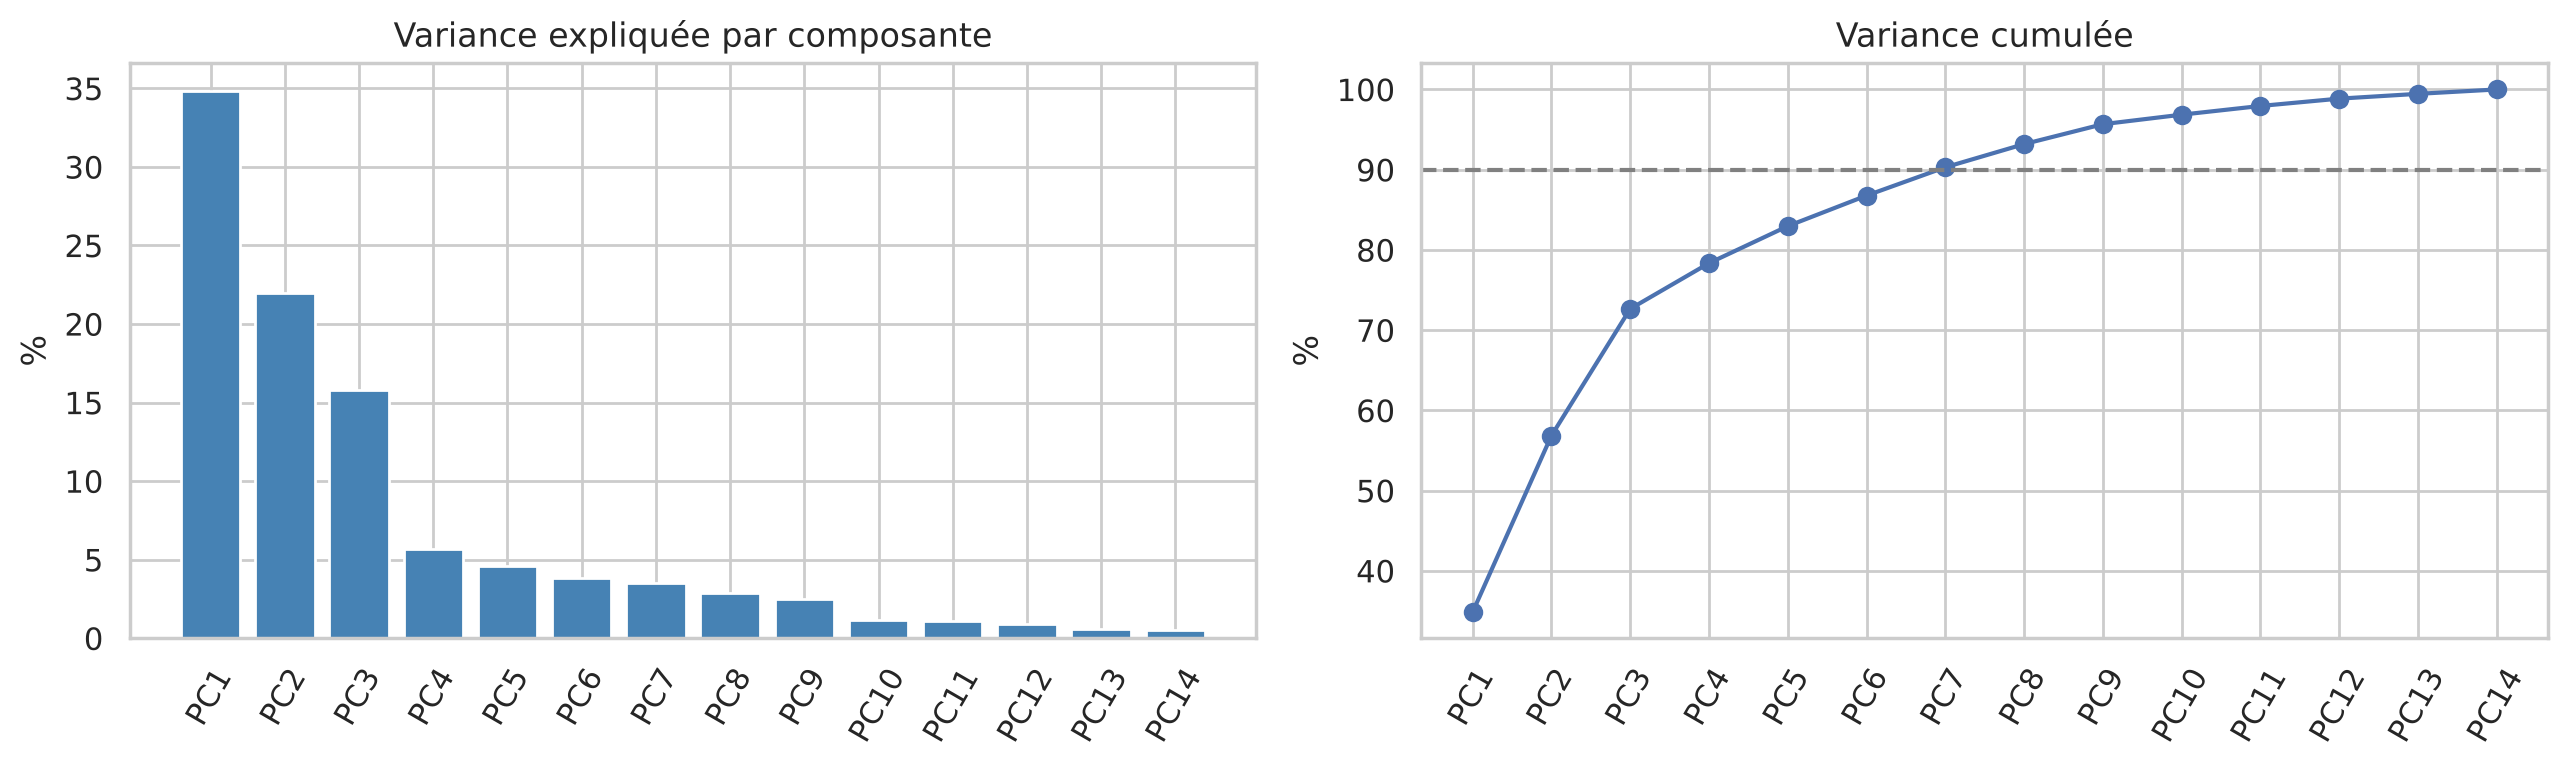

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(var["PC"], var["variance_expliquee_%"], color="steelblue")
ax[0].set_title("Variance expliquée par composante"); ax[0].set_ylabel("%")
ax[0].tick_params(axis="x", rotation=60)
ax[1].plot(var["PC"], var["cumulee_%"], marker="o")
ax[1].axhline(90, ls="--", c="grey"); ax[1].set_title("Variance cumulée"); ax[1].set_ylabel("%")
ax[1].tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

## 4. Choix du nombre de composantes à retenir (L)
Aucun critère n'est parfait. On calcule **5 critères** et on retient par défaut le **consensus** (médiane arrondie à l'entier supérieur).

| Critère | Règle |
|---|---|
| Variance cumulée | plus petit L tel que la variance cumulée ≥ `VAR_THRESHOLD` |
| Kaiser adapté | composantes dont la valeur propre > moyenne des valeurs propres (version adaptée aux données **non standardisées**) |
| Coude (scree) | point de la courbe des valeurs propres le plus éloigné de la droite premier–dernier point |
| Broken-stick | composantes dont la part de variance dépasse celle d'un « bâton brisé » aléatoire |
| Analyse parallèle | valeur propre > 95e percentile de valeurs propres obtenues sur données dont chaque colonne est permutée |

La fonction `choose_n_components` **retourne L**, le tableau des critères et les éléments utiles aux graphiques.

In [6]:
def _leading_true(mask):
    mask = np.asarray(mask)
    return int(mask.shape[0]) if mask.all() else int(np.argmin(mask))

def choose_n_components(pca, X, var_threshold=0.90, n_perm=200, method="consensus",
                        l_min=2, seed=42, manual=None):
    lam, ratio = pca.explained_variance_, pca.explained_variance_ratio_
    p = len(lam)
    ks = np.arange(1, p + 1)

    # 1. variance cumulée
    n_var = int(np.searchsorted(np.cumsum(ratio), var_threshold) + 1)

    # 2. Kaiser adapté (non standardisé) : valeur propre > moyenne
    n_kaiser = int((lam > lam.mean()).sum())

    # 3. coude : distance maximale à la corde (courbe normalisée)
    x = (ks - 1) / (p - 1)
    y = (lam - lam.min()) / (lam.max() - lam.min())
    dist = (1 - x - y) / np.sqrt(2)
    n_elbow = int(ks[np.argmax(dist)])

    # 4. broken-stick
    bs = np.array([np.sum(1.0 / np.arange(k, p + 1)) / p for k in ks])
    n_bs = _leading_true(ratio > bs)

    # 5. analyse parallèle (permutation indépendante de chaque colonne)
    rng = np.random.default_rng(seed)
    Xv = X.values
    perm = np.empty((n_perm, p))
    for b in range(n_perm):
        Xp = np.column_stack([rng.permutation(Xv[:, j]) for j in range(p)])
        perm[b] = np.sort(np.linalg.eigvalsh(np.cov(Xp, rowvar=False)))[::-1]
    thr95 = np.percentile(perm, 95, axis=0)
    n_pa = _leading_true(lam > thr95)

    table = pd.DataFrame({
        "critere": ["variance", "kaiser", "coude", "broken_stick", "parallele"],
        "L_suggere": [n_var, n_kaiser, n_elbow, n_bs, n_pa],
        "regle": [f"variance cumulée ≥ {var_threshold:.0%}",
                  "valeur propre > moyenne",
                  "coude de la courbe des valeurs propres",
                  "variance > bâton brisé",
                  "valeur propre > percentile 95 (permutations)"],
    })
    n_cons = int(np.ceil(np.median(table["L_suggere"])))

    if manual is not None:
        L, how = int(manual), "manuel"
    elif method == "consensus":
        L, how = n_cons, "consensus (médiane des 5 critères)"
    else:
        key = {"variance": n_var, "kaiser": n_kaiser, "coude": n_elbow,
               "broken_stick": n_bs, "parallele": n_pa}
        L, how = key[method], method
    L = int(min(max(L, l_min), p))
    info = {"broken_stick": bs * lam.sum(), "parallele_p95": thr95, "dist_coude": dist,
            "consensus": n_cons, "mode": how}
    return L, table, info

L, crit_table, L_info = choose_n_components(
    pca, X, var_threshold=VAR_THRESHOLD, n_perm=N_PERM,
    method=L_METHOD, l_min=L_MIN, seed=RANDOM_STATE, manual=L_MANUAL)

print(f"==> Nombre de composantes retenues : L = {L}  (mode : {L_info['mode']})")
print(f"    Variance cumulée conservée par PC1..PC{L} : {np.cumsum(pca.explained_variance_ratio_)[L-1]*100:.1f} %")
crit_table

==> Nombre de composantes retenues : L = 10  (mode : manuel)
    Variance cumulée conservée par PC1..PC10 : 96.9 %


,critere,L_suggere,regle
0,variance,7,variance cumulée ≥ 90%
1,kaiser,3,valeur propre > moyenne
2,coude,4,coude de la courbe des valeurs propres
3,broken_stick,3,variance > bâton brisé
4,parallele,1,valeur propre > percentile 95 (permutations)


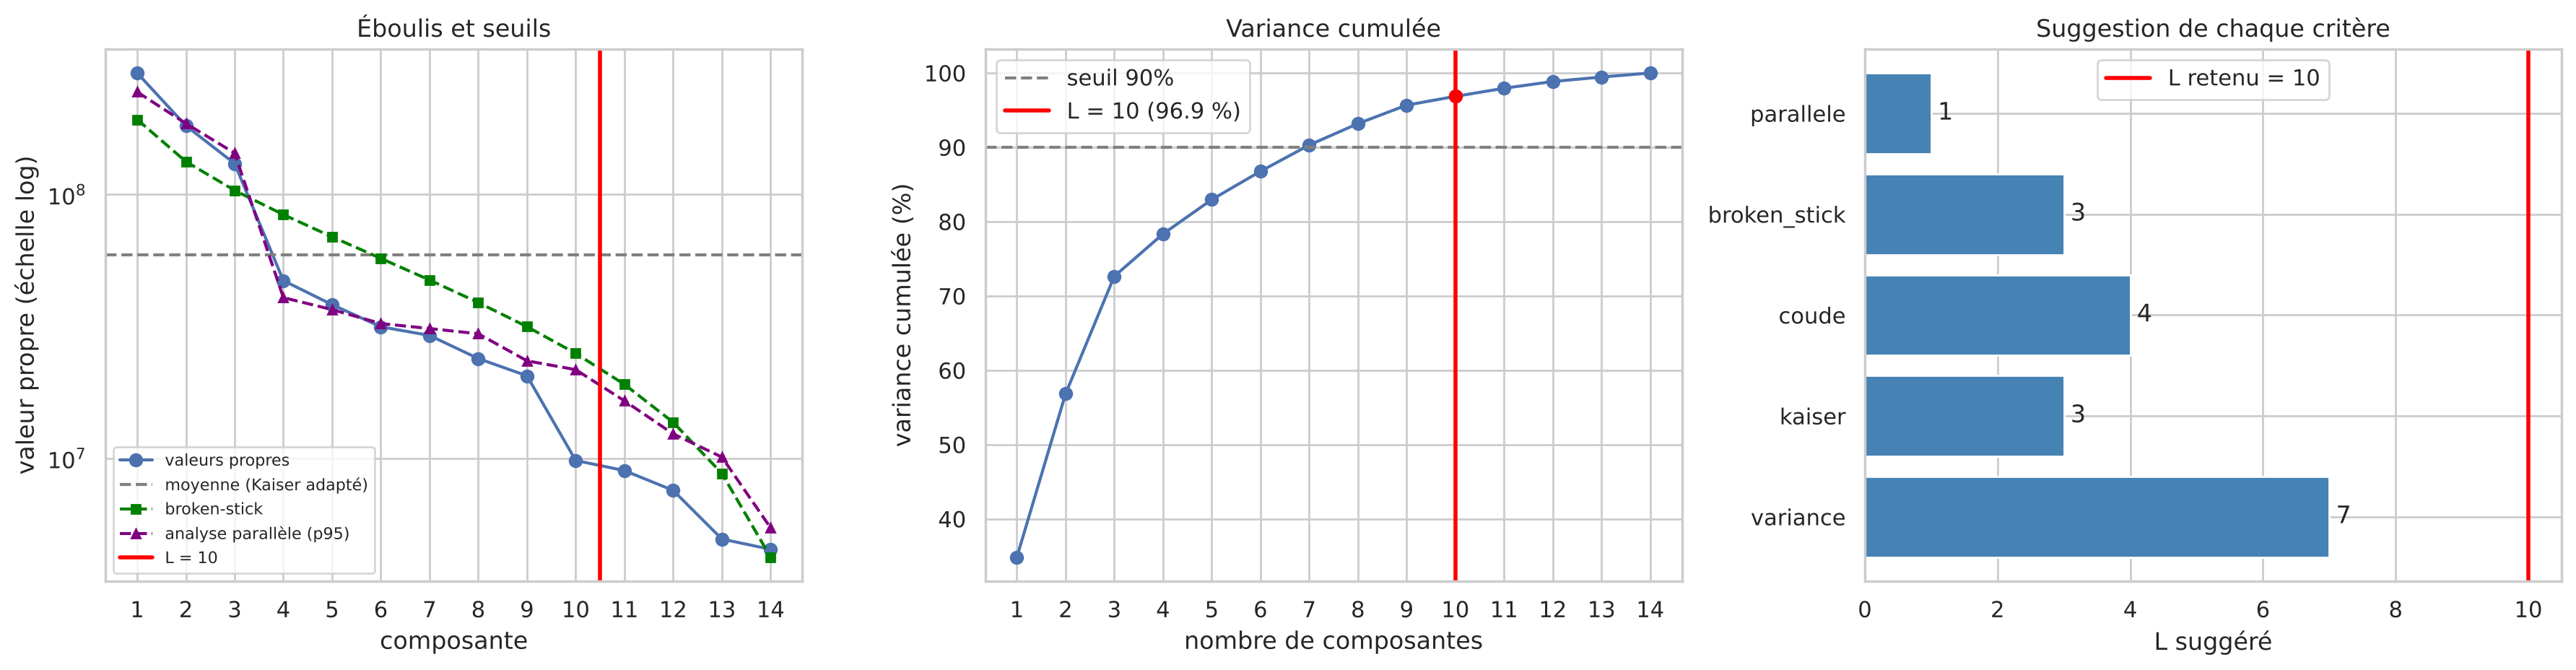

In [7]:
lam = pca.explained_variance_
ks = np.arange(1, len(lam) + 1)
cumv = np.cumsum(pca.explained_variance_ratio_) * 100

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))

# (a) éboulis + seuils
ax[0].plot(ks, lam, "o-", label="valeurs propres")
ax[0].axhline(lam.mean(), ls="--", c="grey", label="moyenne (Kaiser adapté)")
ax[0].plot(ks, L_info["broken_stick"], "s--", c="green", ms=4, label="broken-stick")
ax[0].plot(ks, L_info["parallele_p95"], "^--", c="purple", ms=4, label="analyse parallèle (p95)")
ax[0].axvline(L + 0.5, c="red", lw=2, label=f"L = {L}")
ax[0].set_yscale("log"); ax[0].set_xticks(ks)
ax[0].set_xlabel("composante"); ax[0].set_ylabel("valeur propre (échelle log)")
ax[0].set_title("Éboulis et seuils"); ax[0].legend(fontsize=8)

# (b) variance cumulée
ax[1].plot(ks, cumv, "o-")
ax[1].axhline(VAR_THRESHOLD * 100, ls="--", c="grey", label=f"seuil {VAR_THRESHOLD:.0%}")
ax[1].axvline(L, c="red", lw=2, label=f"L = {L} ({cumv[L-1]:.1f} %)")
ax[1].scatter([L], [cumv[L-1]], c="red", zorder=5)
ax[1].set_xticks(ks); ax[1].set_xlabel("nombre de composantes"); ax[1].set_ylabel("variance cumulée (%)")
ax[1].set_title("Variance cumulée"); ax[1].legend()

# (c) suggestion de chaque critère
colors = ["steelblue"] * len(crit_table)
ax[2].barh(crit_table["critere"], crit_table["L_suggere"], color=colors)
for i, v in enumerate(crit_table["L_suggere"]):
    ax[2].text(v + 0.1, i, str(v), va="center")
ax[2].axvline(L, c="red", lw=2, label=f"L retenu = {L}")
ax[2].set_xlabel("L suggéré"); ax[2].set_title("Suggestion de chaque critère"); ax[2].legend()
plt.tight_layout(); plt.show()

## 5. Données originales **à côté** des données latentes PC1…PCL

In [8]:
pc_names_L = pc_names[:L]
Z_L = Z[:, :L]                              # coordonnées latentes retenues
latent_L = latent[pc_names_L]

df_all = pd.concat([df.reset_index(drop=True), latent_L.reset_index(drop=True)], axis=1)

out_latent = f"site_2350_original_latent_PC1_PC{L}.csv"
df_all.to_csv(out_latent, sep=";", index=False)
print(f"Données originales ({df.shape[1]} col.) + latent PC1..PC{L} ({L} col.) = {df_all.shape}")
print("Fichier enregistré :", out_latent)
df_all.head()

Données originales (17 col.) + latent PC1..PC10 (10 col.) = (2350, 27)
Fichier enregistré : site_2350_original_latent_PC1_PC10.csv


,SITE,MEN03,DEP03,CARREF,HDAL,HDFR,HMSMAUT,INTERM,MONOPRIX,SYSTEM_U,CHAMPION,LECLERC,CASINO,GEANT,AUCHAN,ATAC,CORA,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
0,1,2513,9511281,0,0,0,0,2098,0,0,0,0,0,0,0,0,0,-7410.075183,-1812.539208,-3145.379976,-2880.988728,-204.510355,981.381943,728.251453,-1087.467529,277.763188,-821.745985
1,2,3032,11629101,0,0,0,0,3938,0,0,0,0,0,0,0,0,0,-7136.226403,-1768.905595,-2915.378670,-2150.475726,-138.345958,1851.573703,1447.454004,-575.721266,1302.358284,-923.620132
2,3,1104,4354977,0,0,0,0,0,0,0,0,0,0,0,0,0,0,-7722.322325,-1862.291013,-3407.631465,-3713.932358,-279.952152,-10.825834,-91.795805,-1670.969520,-890.497960,-705.587311
3,4,2401,9508016,0,0,0,0,0,0,0,0,0,0,0,0,0,0,-7722.322325,-1862.291013,-3407.631465,-3713.932358,-279.952152,-10.825834,-91.795805,-1670.969520,-890.497960,-705.587311
4,5,494,1800568,0,0,0,0,0,0,0,0,0,0,0,0,0,0,-7722.322325,-1862.291013,-3407.631465,-3713.932358,-279.952152,-10.825834,-91.795805,-1670.969520,-890.497960,-705.587311


## 6. Entrée du KMeans : uniquement les composantes retenues (PC1…PCL)
La matrice donnée à KMeans (`X_km`) est construite **uniquement** à partir des colonnes latentes `PC1…PCL`.
Les variables originales restent dans `df_all` pour l'interprétation, mais ne servent jamais d'entrée au clustering.

In [9]:
X_km = df_all[pc_names_L].to_numpy()          # entrée de KMeans = PC1..PCL uniquement

# garde-fous : aucune variable d'origine dans l'entrée
assert X_km.shape == (len(df), L), X_km.shape
assert all(c.startswith("PC") for c in pc_names_L)
assert not set(pc_names_L) & set(df.columns)
print(f"Entrée KMeans : {X_km.shape[0]} sites x {X_km.shape[1]} composantes ({pc_names_L[0]}..{pc_names_L[-1]})")
print(f"Variance cumulée portée par ces composantes : {np.cumsum(pca.explained_variance_ratio_)[L-1]*100:.1f} %")
pd.DataFrame(X_km, columns=pc_names_L).head()

Entrée KMeans : 2350 sites x 10 composantes (PC1..PC10)
Variance cumulée portée par ces composantes : 96.9 %


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
0,-7410.075183,-1812.539208,-3145.379976,-2880.988728,-204.510355,981.381943,728.251453,-1087.467529,277.763188,-821.745985
1,-7136.226403,-1768.905595,-2915.378670,-2150.475726,-138.345958,1851.573703,1447.454004,-575.721266,1302.358284,-923.620132
2,-7722.322325,-1862.291013,-3407.631465,-3713.932358,-279.952152,-10.825834,-91.795805,-1670.969520,-890.497960,-705.587311
3,-7722.322325,-1862.291013,-3407.631465,-3713.932358,-279.952152,-10.825834,-91.795805,-1670.969520,-890.497960,-705.587311
4,-7722.322325,-1862.291013,-3407.631465,-3713.932358,-279.952152,-10.825834,-91.795805,-1670.969520,-890.497960,-705.587311


## 6 bis. Choix du nombre de clusters k (sur X_km)

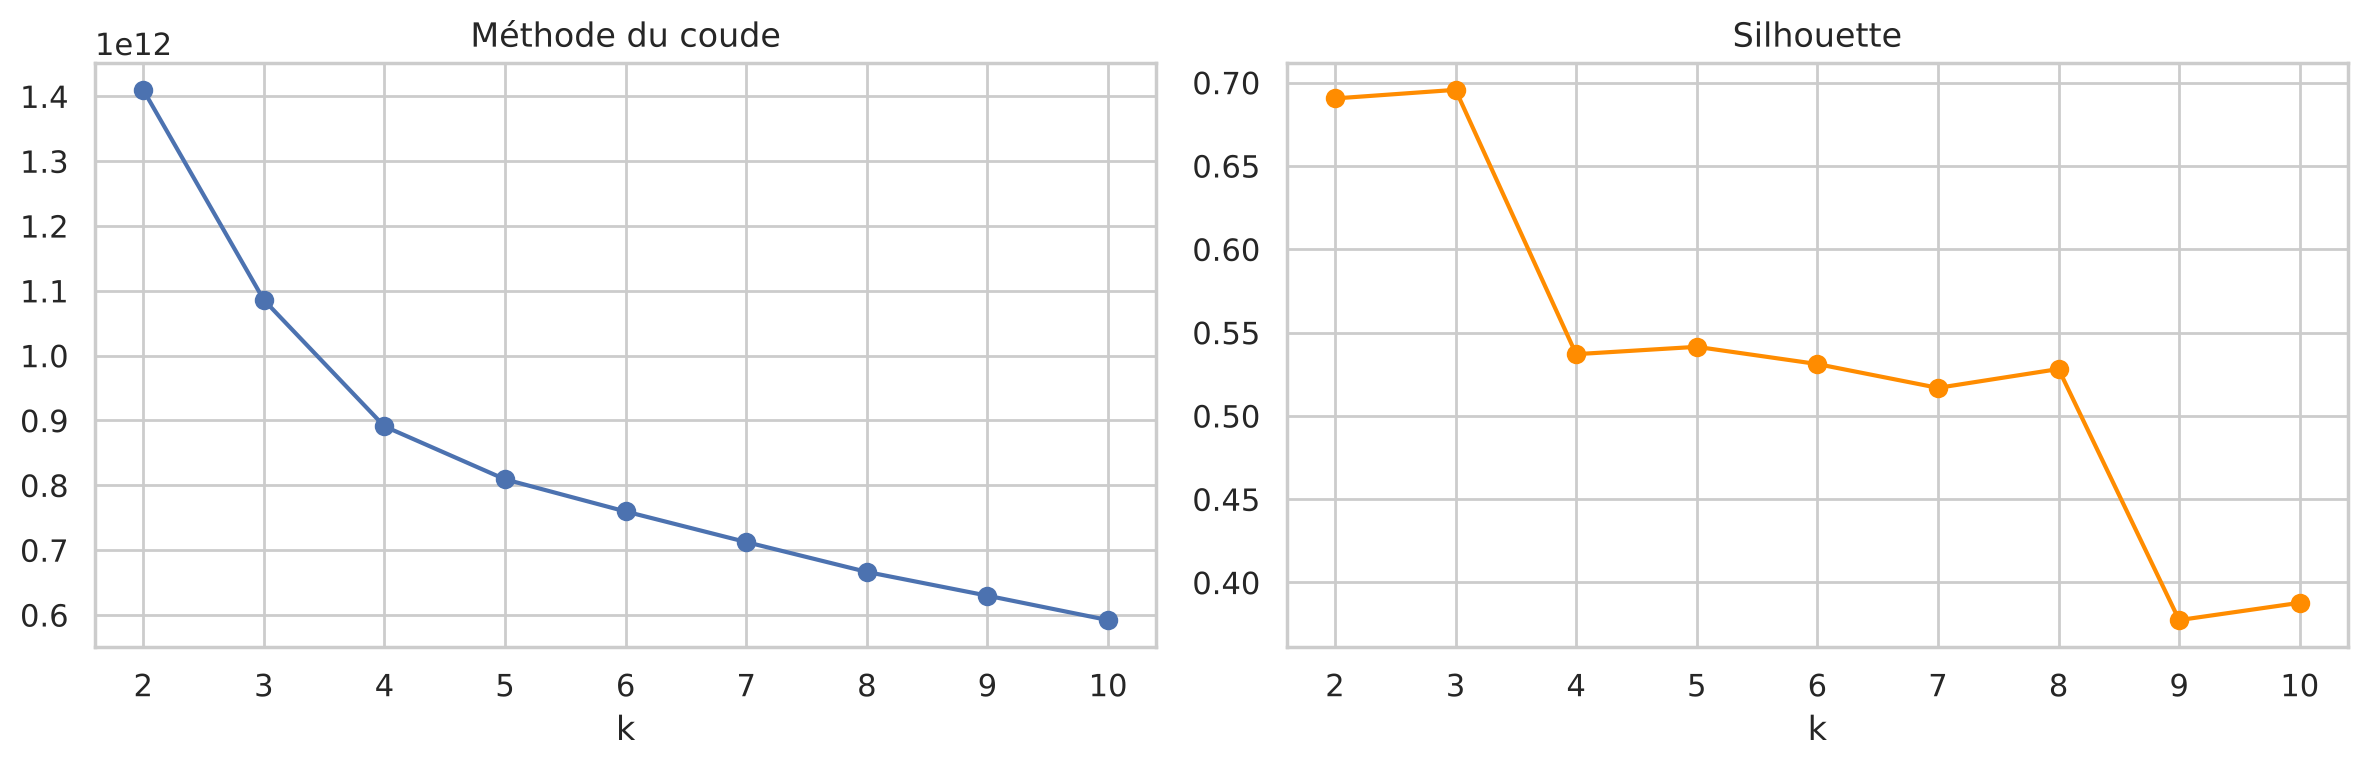

k retenu : 3


,k,inertie,silhouette
0,2,1.410029e+12,0.690
1,3,1.085939e+12,0.696
2,4,8.908673e+11,0.537
3,5,8.091858e+11,0.541
4,6,7.595657e+11,0.531
5,7,7.123751e+11,0.517
6,8,6.663239e+11,0.528
7,9,6.296669e+11,0.377
8,10,5.920133e+11,0.388


In [10]:
res = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_km)
    res.append((k, km.inertia_, silhouette_score(X_km, km.labels_)))
sel = pd.DataFrame(res, columns=["k", "inertie", "silhouette"])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(sel["k"], sel["inertie"], marker="o"); ax[0].set_title("Méthode du coude"); ax[0].set_xlabel("k")
ax[1].plot(sel["k"], sel["silhouette"], marker="o", c="darkorange"); ax[1].set_title("Silhouette"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()

K = K_CHOSEN or int(sel.loc[sel["silhouette"].idxmax(), "k"])
print("k retenu :", K)
sel.round(3)

## 7. Clustering KMeans (entrée : PC1…PCL uniquement)

In [11]:
km = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X_km)
df_all["CLUSTER"] = km.labels_
df_all["CLUSTER"].value_counts().sort_index().rename("nb_sites").to_frame()

,nb_sites
CLUSTER,
0,2148
1,81
2,121


## 8. Classification mixte : KMeans fin → CAH de Ward sur les centres
Enchaînement classique pour les grandes bases :
1. **KMeans « fin »** avec `K_PRE` clusters, uniquement sur les variables latentes PC1…PCL (`X_km`) ;
2. **CAH de Ward** sur les `K_PRE` **centres**, pondérés par la taille de chaque cluster (ce qui équivaut à une CAH de Ward sur les 2350 sites regroupés par micro-cluster) ;
3. **Choix du nombre de classes à partir du graphe d'inertie** : on lit la courbe d'inertie intra-classe (coude) et le gain marginal d'inertie expliquée ; on vérifie que chaque classe est assez grande. La règle de Ward (plus grand saut) et la silhouette servent de contrôles croisés, et une **synthèse rédigée** justifie le nombre retenu ;
4. Chaque site hérite de la classe CAH de son micro-cluster KMeans (`CLUSTER_CAH`).

In [12]:
from scipy.cluster.hierarchy import dendrogram, fcluster

# ---- 1. KMeans fin sur PC1..PCL uniquement ----
km_pre = KMeans(n_clusters=K_PRE, n_init=10, random_state=RANDOM_STATE).fit(X_km)
centers = km_pre.cluster_centers_
sizes = np.bincount(km_pre.labels_, minlength=K_PRE)
df_all["KM_MICRO"] = km_pre.labels_
print(f"KMeans fin : {K_PRE} clusters ; taille min / médiane / max = {sizes.min()} / {int(np.median(sizes))} / {sizes.max()}")

# ---- 2. CAH de Ward pondérée sur les centres ----
def ward_on_centroids(C, w):
    # CAH de Ward sur des centres C (K x p) de masses w.
    # Hauteur de fusion = gain d'inertie intra-classe  m_a*m_b/(m_a+m_b) * ||g_a - g_b||^2.
    # Retourne une matrice de liaison au format scipy.
    K = len(C)
    cent = {i: C[i].astype(float) for i in range(K)}
    mass = {i: float(w[i]) for i in range(K)}
    nleaf = {i: 1 for i in range(K)}
    active = list(range(K))
    Zl = np.zeros((K - 1, 4))
    for step in range(K - 1):
        best = (np.inf, None, None)
        for ia in range(len(active)):
            a = active[ia]
            for ib in range(ia + 1, len(active)):
                b = active[ib]
                d = mass[a] * mass[b] / (mass[a] + mass[b]) * np.sum((cent[a] - cent[b]) ** 2)
                if d < best[0]:
                    best = (d, a, b)
        d, a, b = best
        new = K + step
        m = mass[a] + mass[b]
        cent[new] = (mass[a] * cent[a] + mass[b] * cent[b]) / m
        mass[new], nleaf[new] = m, nleaf[a] + nleaf[b]
        Zl[step] = [a, b, d, nleaf[new]]
        active.remove(a); active.remove(b); active.append(new)
    Zl[:, 2] = np.maximum.accumulate(Zl[:, 2])      # monotonie (arrondis flottants)
    return Zl

Zw = ward_on_centroids(centers, sizes)
h = Zw[:, 2]                                         # indices d'agrégation (gain d'inertie intra)
print("Dernières fusions (indice d'agrégation) :", np.round(h[-5:], 0))

KMeans fin : 50 clusters ; taille min / médiane / max = 1 / 11 / 743
Dernières fusions (indice d'agrégation) : [7.68766097e+10 1.04686548e+11 1.97985600e+11 3.01816633e+11
 3.78559087e+11]


### Règle de décision (lecture du graphe d'inertie)
Le nombre de classes est lu sur la **courbe d'inertie intra-classe** de la CAH :
1. **Coude** : on retient le k où la courbe s'écarte le plus de la corde reliant k minimal et k maximal (au-delà, chaque classe ajoutée apporte peu d'information) ;
2. **Gain marginal** : passer de k-1 à k classes doit gagner au moins `GAIN_MIN` points d'inertie expliquée ;
3. **Taille minimale** : la plus petite classe doit regrouper au moins `MIN_SHARE` % des sites (pas de classe « anecdotique ») ;
4. Si le coude ne passe pas les tests 2 et 3, on diminue k jusqu'à les satisfaire.

Contrôles croisés : plus grand saut de Ward et indice de silhouette. Une synthèse rédigée est générée juste après les graphiques.

In [13]:
# ---- 3. Choix du nombre de classes à partir du graphe d'inertie ----
X_c = X_km - X_km.mean(axis=0)
I_tot = float((X_c ** 2).sum())                      # inertie totale des sites
I_w0 = float(km_pre.inertia_)                        # inertie intra du KMeans fin

def labels_sites(k):
    # classes CAH à k classes, projetées sur les sites via leur micro-cluster
    lab_c = fcluster(Zw, t=k, criterion="maxclust") - 1
    return lab_c[km_pre.labels_]

rows = []
for k in range(2, K_PRE):                            # k classes = après (K_PRE - k) fusions
    n_merges = K_PRE - k
    I_w = I_w0 + h[:n_merges].sum()                  # inertie intra de la partition à k classes
    saut = h[K_PRE - k] - h[K_PRE - k - 1] if (K_PRE - k - 1) >= 0 else np.nan
    rows.append({"k": k, "inertie_intra": I_w, "R2_inter_%": 100 * (1 - I_w / I_tot),
                 "indice_fusion_suivante": h[K_PRE - k], "saut": saut})
cah_table = pd.DataFrame(rows).set_index("k")
cah_table["gain_R2_pts"] = cah_table["R2_inter_%"].diff()        # gain en passant de k-1 à k classes

sil, minshare = {}, {}
for k in range(CAH_K_MIN, CAH_K_MAX + 2):
    ls = labels_sites(k)
    sil[k] = silhouette_score(X_km, ls)
    minshare[k] = 100 * np.bincount(ls).min() / len(ls)
cah_table["silhouette"] = pd.Series(sil)
cah_table["taille_min_%"] = pd.Series(minshare)

# --- coude de la courbe d'inertie intra (distance à la corde) ---
kk = np.arange(CAH_K_MIN, CAH_K_MAX + 1)
Iw = cah_table.loc[kk, "inertie_intra"].to_numpy()
x = (kk - kk[0]) / (kk[-1] - kk[0])
y = (Iw - Iw.min()) / (Iw.max() - Iw.min())
dist_coude = pd.Series((1 - x - y) / np.sqrt(2), index=kk)
k_coude = int(dist_coude.idxmax())

# --- tests de validation : gain marginal et taille minimale ---
def valide(k):
    return (cah_table.loc[k, "gain_R2_pts"] >= GAIN_MIN) and (cah_table.loc[k, "taille_min_%"] >= MIN_SHARE)

k_dec = k_coude
while k_dec > CAH_K_MIN and not valide(k_dec):
    k_dec -= 1

# --- contrôle croisé : règle de Ward (plus grand saut) ---
cand = cah_table.loc[CAH_K_MIN:CAH_K_MAX].dropna(subset=["saut"])
k_ward = int(cand["saut"].idxmax())

K_FINAL = int(K_CAH) if K_CAH is not None else k_dec
print(f"Coude de la courbe d'inertie intra : k = {k_coude}")
print(f"Après tests (gain >= {GAIN_MIN} pts, plus petite classe >= {MIN_SHARE} %) : k = {k_dec}")
print(f"Contrôle : règle de Ward (plus grand saut) : k = {k_ward} ; meilleure silhouette : k = {int(cah_table.loc[CAH_K_MIN:CAH_K_MAX, 'silhouette'].idxmax())}")
print(f"==> Nombre de classes retenu (CAH) : {K_FINAL}" + ("  [imposé]" if K_CAH is not None else ""))
cah_table.loc[CAH_K_MIN:max(CAH_K_MAX, K_FINAL), ["inertie_intra", "R2_inter_%", "gain_R2_pts", "saut", "silhouette", "taille_min_%"]].round(2)

Coude de la courbe d'inertie intra : k = 4
Après tests (gain >= 5.0 pts, plus petite classe >= 2.0 %) : k = 4
Contrôle : règle de Ward (plus grand saut) : k = 3 ; meilleure silhouette : k = 3
==> Nombre de classes retenu (CAH) : 4


,inertie_intra,R2_inter_%,gain_R2_pts,saut,silhouette,taille_min_%
k,,,,,,
2,1.503263e+12,20.08,NaN,7.674245e+10,0.63,9.91
3,1.201446e+12,36.12,16.05,1.038310e+11,0.63,4.17
4,1.003461e+12,46.65,10.53,9.329905e+10,0.50,4.17
5,8.987742e+11,52.22,5.57,2.780994e+10,0.51,0.85
6,8.218976e+11,56.30,4.09,2.246606e+10,0.47,0.85
7,7.674871e+11,59.20,2.89,1.140489e+10,0.47,0.55
8,7.244814e+11,61.48,2.29,3.667145e+09,0.48,0.55
9,6.851429e+11,63.57,2.09,7.671648e+08,0.48,0.55
10,6.465715e+11,65.62,2.05,5.669425e+09,0.35,0.55


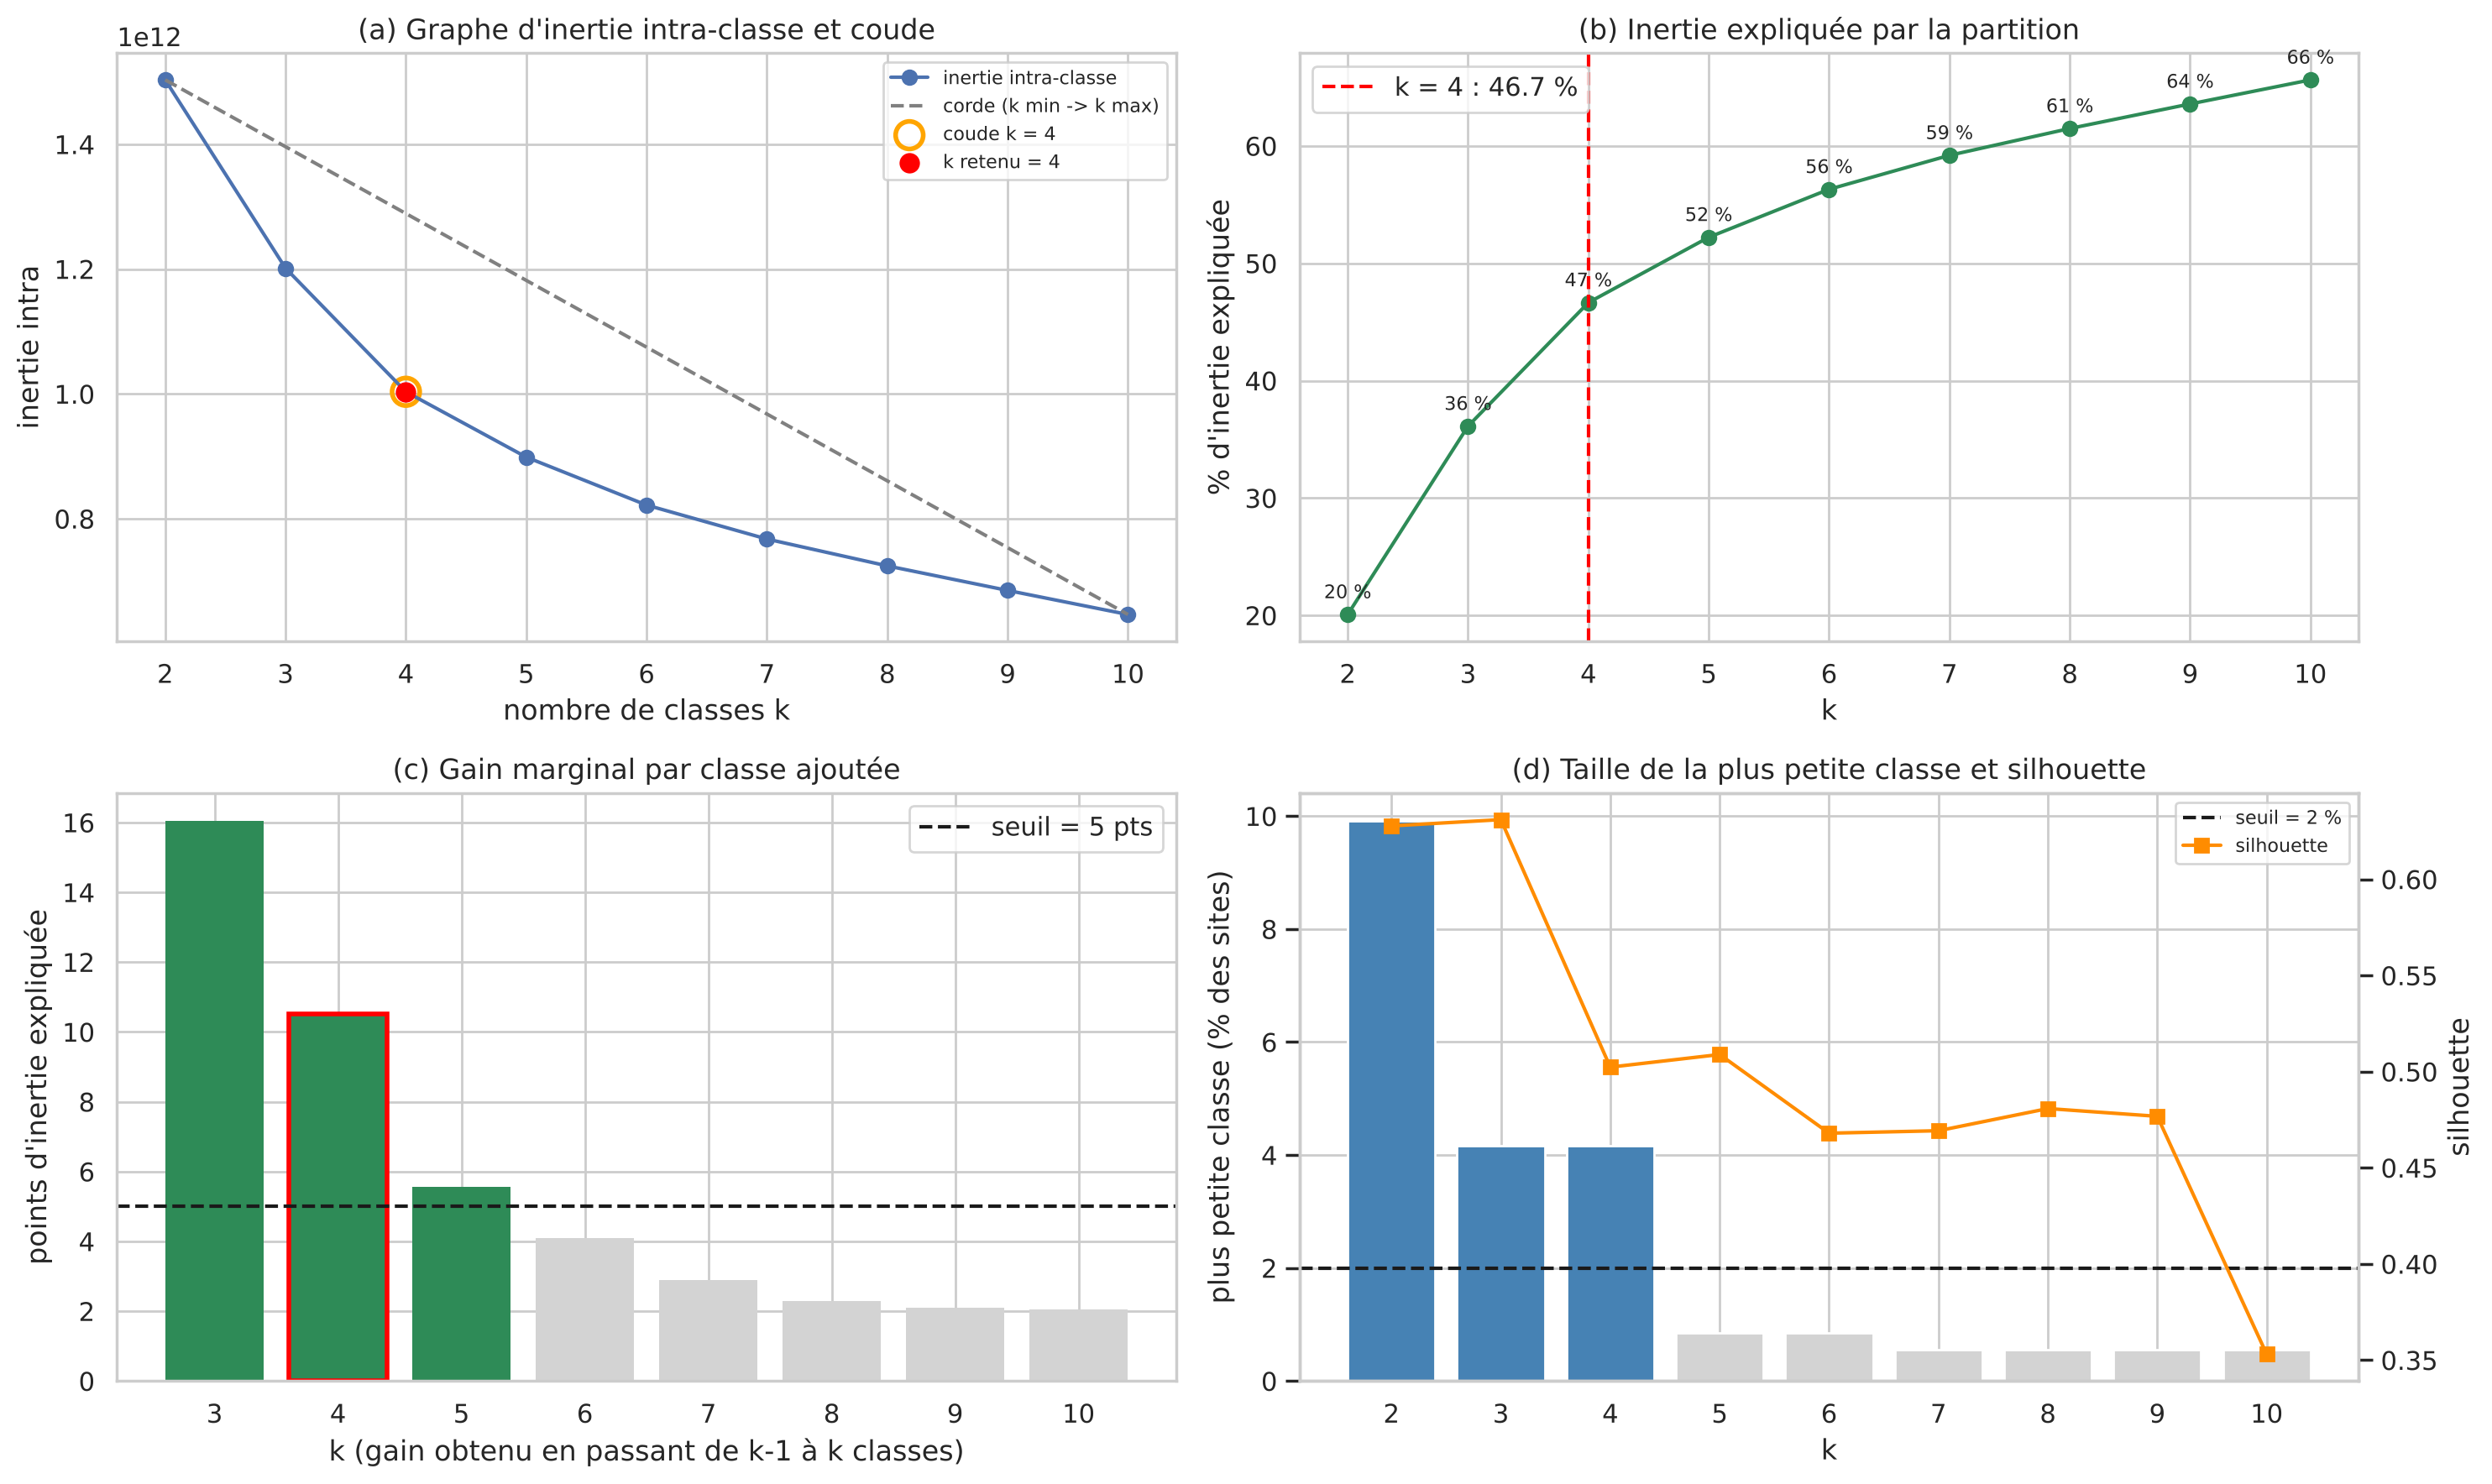

In [14]:
# ---- Graphe d'inertie : base du choix du nombre de classes ----
fig, ax = plt.subplots(2, 2, figsize=(15, 9))

# (a) inertie intra-classe + corde + coude
a = ax[0, 0]
a.plot(kk, Iw, "o-", label="inertie intra-classe")
a.plot([kk[0], kk[-1]], [Iw[0], Iw[-1]], "--", c="grey", label="corde (k min -> k max)")
a.scatter([k_coude], [cah_table.loc[k_coude, "inertie_intra"]], s=140, facecolors="none", edgecolors="orange", linewidths=2, label=f"coude k = {k_coude}")
a.scatter([K_FINAL], [cah_table.loc[K_FINAL, "inertie_intra"]], s=60, c="red", zorder=5, label=f"k retenu = {K_FINAL}")
a.set_xticks(kk); a.set_xlabel("nombre de classes k"); a.set_ylabel("inertie intra")
a.set_title("(a) Graphe d'inertie intra-classe et coude"); a.legend(fontsize=8)

# (b) inertie expliquée
b = ax[0, 1]
r2 = cah_table.loc[kk, "R2_inter_%"]
b.plot(kk, r2.values, "o-", c="seagreen")
for k_, v_ in zip(kk, r2.values):
    b.annotate(f"{v_:.0f} %", (k_, v_), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
b.axvline(K_FINAL, c="red", ls="--", label=f"k = {K_FINAL} : {cah_table.loc[K_FINAL, 'R2_inter_%']:.1f} %")
b.set_xticks(kk); b.set_xlabel("k"); b.set_ylabel("% d'inertie expliquée")
b.set_title("(b) Inertie expliquée par la partition"); b.legend()

# (c) gain marginal
c_ = ax[1, 0]
kg = np.arange(CAH_K_MIN + 1, CAH_K_MAX + 1)
gains = cah_table.loc[kg, "gain_R2_pts"]
c_.bar(kg, gains.values, color=["seagreen" if g >= GAIN_MIN else "lightgrey" for g in gains.values],
       edgecolor=["red" if k_ == K_FINAL else "none" for k_ in kg], linewidth=2)
c_.axhline(GAIN_MIN, c="k", ls="--", label=f"seuil = {GAIN_MIN:.0f} pts")
c_.set_xticks(kg); c_.set_xlabel("k (gain obtenu en passant de k-1 à k classes)"); c_.set_ylabel("points d'inertie expliquée")
c_.set_title("(c) Gain marginal par classe ajoutée"); c_.legend()

# (d) taille minimale + silhouette
d_ = ax[1, 1]
ms = cah_table.loc[kk, "taille_min_%"]
d_.bar(kk, ms.values, color=["steelblue" if v >= MIN_SHARE else "lightgrey" for v in ms.values])
d_.axhline(MIN_SHARE, c="k", ls="--", label=f"seuil = {MIN_SHARE:.0f} %")
d_.set_xticks(kk); d_.set_xlabel("k"); d_.set_ylabel("plus petite classe (% des sites)")
d2 = d_.twinx()
d2.plot(kk, cah_table.loc[kk, "silhouette"].values, "s-", c="darkorange", label="silhouette")
d2.set_ylabel("silhouette"); d2.grid(False)
d_.set_title("(d) Taille de la plus petite classe et silhouette")
h1, l1 = d_.get_legend_handles_labels(); h2, l2 = d2.get_legend_handles_labels()
d_.legend(h1 + h2, l1 + l2, fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

In [15]:
# ---- Synthèse rédigée : pourquoi ce nombre de classes ? ----
from IPython.display import Markdown, display
NL = chr(10)
k = K_FINAL
T = cah_table
origine = "imposé manuellement (K_CAH)" if K_CAH is not None else "déduit du graphe d'inertie"
L_txt = [f"### Synthèse du choix du nombre de classes : **K = {k}** ({origine})", ""]

L_txt.append(f"- **Lecture du graphe d'inertie.** La partition en {k} classes explique **{T.loc[k, 'R2_inter_%']:.1f} %** de l'inertie totale "
             f"(inertie intra : {T.loc[k, 'inertie_intra']:.3e}). Le coude de la courbe d'inertie intra (point le plus éloigné de la corde entre k = {CAH_K_MIN} et k = {CAH_K_MAX}) se situe à **k = {k_coude}**.")

# pourquoi pas k-1
if k > CAH_K_MIN:
    ls_k, ls_m = labels_sites(k), labels_sites(k - 1)
    fusions = []
    for c in np.unique(ls_m):
        parents = np.unique(ls_k[ls_m == c])
        if len(parents) > 1:
            fusions.append(" + ".join(str(int((ls_k == p).sum())) for p in parents))
    L_txt.append(f"- **Pourquoi pas {k - 1} classes ?** Cela ferait perdre **{T.loc[k, 'gain_R2_pts']:.1f} points** d'inertie expliquée "
                 f"({T.loc[k - 1, 'R2_inter_%']:.1f} % -> {T.loc[k, 'R2_inter_%']:.1f} %) en fusionnant des groupes distincts de {' ; '.join(fusions)} sites, "
                 f"ce qui masquerait une structure réelle (perte {'supérieure' if T.loc[k, 'gain_R2_pts'] >= GAIN_MIN else 'inférieure'} au seuil de {GAIN_MIN:.0f} points).")

# pourquoi pas k+1
ls_k, ls_p = labels_sites(k), labels_sites(k + 1)
scinde = []
for c in np.unique(ls_k):
    enfants = np.unique(ls_p[ls_k == c])
    if len(enfants) > 1:
        scinde.append((int((ls_k == c).sum()), sorted(int((ls_p == e).sum()) for e in enfants)))
gain_p = T.loc[k + 1, "gain_R2_pts"]
part_min_p = T.loc[k + 1, "taille_min_%"]
raisons = []
if gain_p < GAIN_MIN:
    raisons.append(f"le gain n'est que de +{gain_p:.1f} point(s), sous le seuil de {GAIN_MIN:.0f} points")
if part_min_p < MIN_SHARE:
    raisons.append(f"la plus petite classe ne contiendrait que {part_min_p:.2f} % des sites, sous le seuil de {MIN_SHARE:.0f} %")
detail = ("elle ne ferait que scinder une classe de " + str(scinde[0][0]) + " sites en " + " et ".join(map(str, scinde[0][1])) + " sites") if scinde else "elle scinderait une classe existante"
if raisons:
    L_txt.append(f"- **Pourquoi pas {k + 1} classes ?** {detail} ; " + " et ".join(raisons) + ". Les classes supplémentaires n'apportent pas d'information importante.")
else:
    L_txt.append(f"- **Pourquoi pas {k + 1} classes ?** {detail} (gain de +{gain_p:.1f} points) ; {k} classes sont retenues par parcimonie et pour la lisibilité.")

# contrôles croisés
sil_k = T.loc[k, "silhouette"]
sil_txt = f"silhouette = {sil_k:.3f} pour k = {k}" + (f" (contre {T.loc[k - 1, 'silhouette']:.3f} pour k = {k - 1})" if k > CAH_K_MIN else "") + f" et {T.loc[k + 1, 'silhouette']:.3f} pour k = {k + 1}"
ward_txt = (f"la règle de Ward (plus grand saut) **confirme** k = {k_ward}" if k_ward == k
            else f"la règle de Ward (plus grand saut) suggère k = {k_ward} : elle ne regarde que l'écart entre deux dernières fusions et ignore la part d'inertie expliquée ; on privilégie donc le graphe d'inertie")
sil_note = ""
if k > CAH_K_MIN and T.loc[k - 1, "silhouette"] > sil_k:
    sil_note = (f" La silhouette est plus élevée à k = {k - 1} : elle récompense surtout la séparation des très gros écarts (quelques gros sites) "
                f"et sous-estime les groupes intermédiaires ; elle ne sert ici que de contrôle, le choix reposant sur l'inertie expliquée.")
L_txt.append(f"- **Contrôles croisés.** {sil_txt} ; {ward_txt}.{sil_note}")

tailles = np.bincount(labels_sites(k))
L_txt.append(f"- **Classes obtenues.** Tailles (sites) : {', '.join(str(int(n)) for n in sorted(tailles, reverse=True))} — la plus petite représente {100 * tailles.min() / len(df_all):.1f} % des sites (seuil {MIN_SHARE:.0f} %).")
suite = (f"la classe suivante ne serait pas retenue car {' et '.join(raisons)}" if raisons
         else f"la classe suivante (+{gain_p:.1f} point(s)) reste possible mais {k} classes sont retenues par parcimonie")
L_txt.append(f"- **Conclusion.** {k} classes constituent le meilleur compromis : elles expliquent {T.loc[k, 'R2_inter_%']:.1f} % de l'inertie, la dernière classe ajoutée apporte +{T.loc[k, 'gain_R2_pts']:.1f} point(s) (seuil {GAIN_MIN:.0f}), {suite}, et la plus petite classe retenue représente {100 * tailles.min() / len(df_all):.1f} % des sites.")

txt_choix = NL.join(L_txt)
display(Markdown(txt_choix))

### Synthèse du choix du nombre de classes : **K = 4** (déduit du graphe d'inertie)

- **Lecture du graphe d'inertie.** La partition en 4 classes explique **46.7 %** de l'inertie totale (inertie intra : 1.003e+12). Le coude de la courbe d'inertie intra (point le plus éloigné de la corde entre k = 2 et k = 10) se situe à **k = 4**.
- **Pourquoi pas 3 classes ?** Cela ferait perdre **10.5 points** d'inertie expliquée (36.1 % -> 46.7 %) en fusionnant des groupes distincts de 1748 + 369 sites, ce qui masquerait une structure réelle (perte supérieure au seuil de 5 points).
- **Pourquoi pas 5 classes ?** elle ne ferait que scinder une classe de 135 sites en 20 et 115 sites ; la plus petite classe ne contiendrait que 0.85 % des sites, sous le seuil de 2 %. Les classes supplémentaires n'apportent pas d'information importante.
- **Contrôles croisés.** silhouette = 0.502 pour k = 4 (contre 0.631 pour k = 3) et 0.509 pour k = 5 ; la règle de Ward (plus grand saut) suggère k = 3 : elle ne regarde que l'écart entre deux dernières fusions et ignore la part d'inertie expliquée ; on privilégie donc le graphe d'inertie. La silhouette est plus élevée à k = 3 : elle récompense surtout la séparation des très gros écarts (quelques gros sites) et sous-estime les groupes intermédiaires ; elle ne sert ici que de contrôle, le choix reposant sur l'inertie expliquée.
- **Classes obtenues.** Tailles (sites) : 1748, 369, 135, 98 — la plus petite représente 4.2 % des sites (seuil 2 %).
- **Conclusion.** 4 classes constituent le meilleur compromis : elles expliquent 46.7 % de l'inertie, la dernière classe ajoutée apporte +10.5 point(s) (seuil 5), la classe suivante ne serait pas retenue car la plus petite classe ne contiendrait que 0.85 % des sites, sous le seuil de 2 %, et la plus petite classe retenue représente 4.2 % des sites.

In [16]:
# ---- 4. Partition finale : chaque site hérite de la classe de son micro-cluster ----
lab_micro = fcluster(Zw, t=K_FINAL, criterion="maxclust") - 1      # classe CAH de chaque centre (0..K_FINAL-1)
df_all["CLUSTER_CAH"] = lab_micro[km_pre.labels_]

res_cah = pd.DataFrame({"nb_sites": df_all["CLUSTER_CAH"].value_counts().sort_index()})
res_cah["%"] = (100 * res_cah["nb_sites"] / len(df_all)).round(1)
res_cah["nb_micro_clusters"] = pd.Series(lab_micro).value_counts().sort_index()
print(f"Inertie inter-classes expliquée par la partition à {K_FINAL} classes : {cah_table.loc[K_FINAL, 'R2_inter_%']:.1f} %")
res_cah

Inertie inter-classes expliquée par la partition à 4 classes : 46.7 %


,nb_sites,%,nb_micro_clusters
CLUSTER_CAH,,,
0,1748,74.4,11
1,369,15.7,13
2,98,4.2,13
3,135,5.7,13


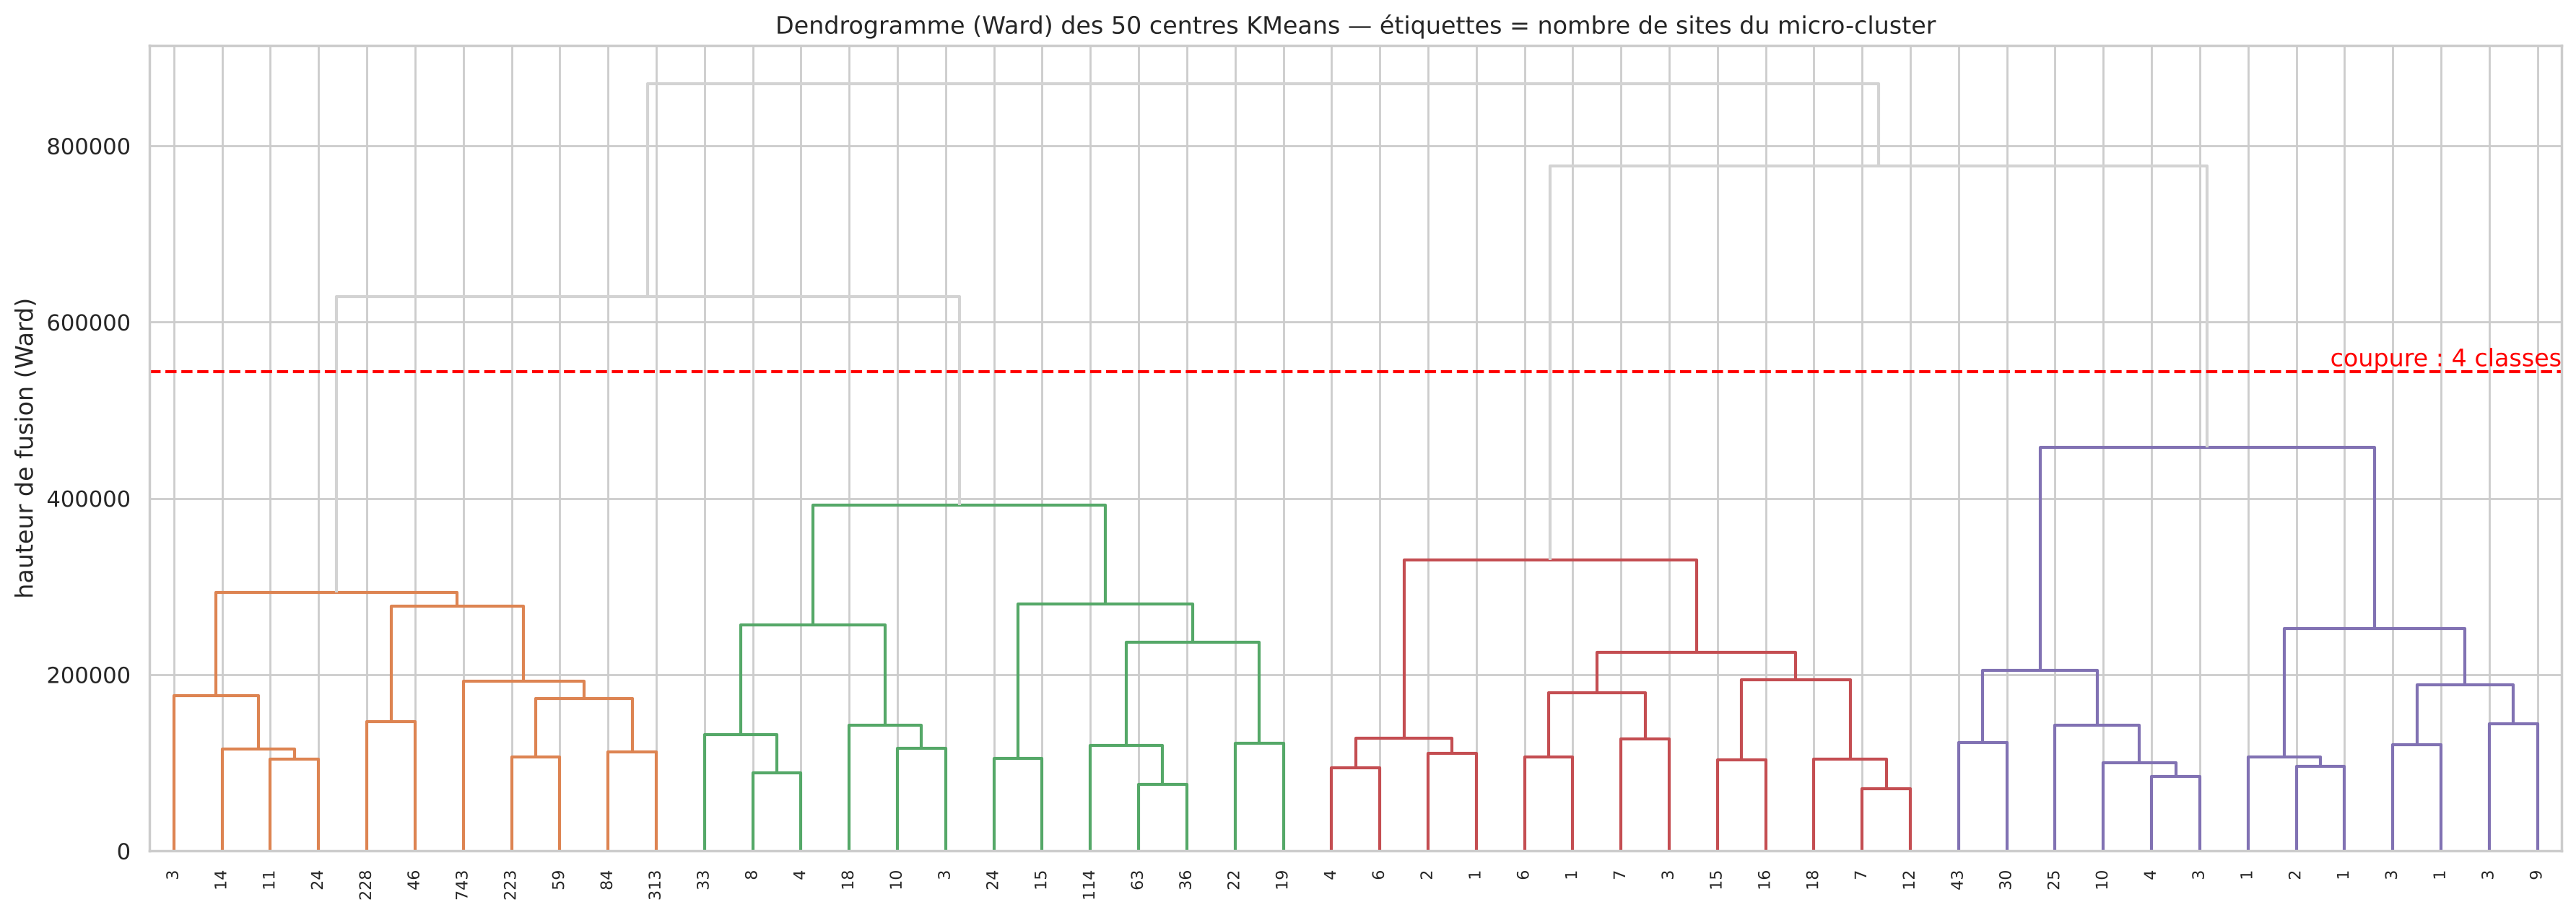

In [17]:
# ---- Schéma de partition : dendrogramme de la CAH de Ward sur les centres ----
Zp = Zw.copy()
Zp[:, 2] = np.sqrt(2 * Zw[:, 2])                    # hauteur au sens scipy/Ward : sqrt(2 * gain d'inertie)
cut_h = 0.5 * (Zp[K_PRE - K_FINAL - 1, 2] + Zp[K_PRE - K_FINAL, 2]) if K_FINAL > 1 else Zp[-1, 2]

fig, ax = plt.subplots(figsize=(18, 6.5))
dendrogram(Zp, ax=ax, color_threshold=cut_h, above_threshold_color="lightgrey",
           labels=[f"{n}" for n in sizes], leaf_rotation=90, leaf_font_size=8)
ax.axhline(cut_h, ls="--", c="red", lw=1.5)
ax.text(ax.get_xlim()[1], cut_h, f"  coupure : {K_FINAL} classes", color="red", va="bottom", ha="right")
ax.set_title(f"Dendrogramme (Ward) des {K_PRE} centres KMeans — étiquettes = nombre de sites du micro-cluster")
ax.set_ylabel("hauteur de fusion (Ward)")
plt.tight_layout(); plt.show()

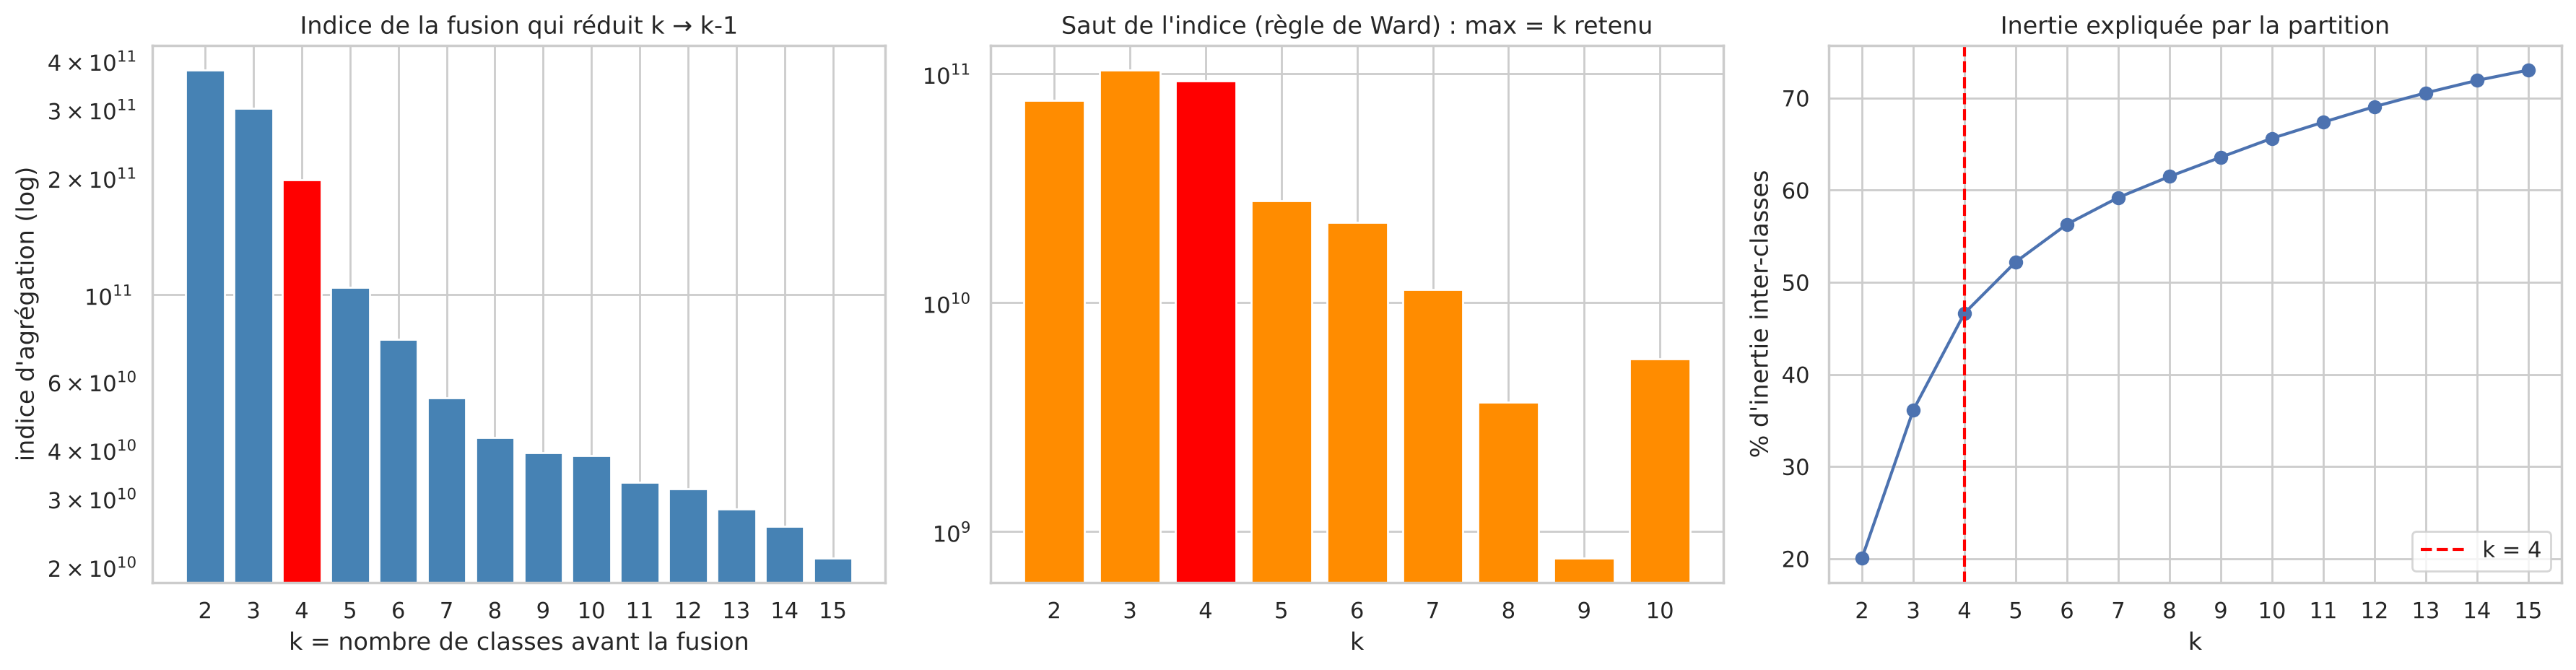

In [18]:
# ---- Indices d'agrégation et inertie expliquée : justification du choix de k ----
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
kk = np.arange(2, 16)
ax[0].bar(kk, [h[K_PRE - k] for k in kk], color=["red" if k == K_FINAL else "steelblue" for k in kk])
ax[0].set_yscale("log"); ax[0].set_xticks(kk)
ax[0].set_xlabel("k = nombre de classes avant la fusion"); ax[0].set_ylabel("indice d'agrégation (log)")
ax[0].set_title("Indice de la fusion qui réduit k → k-1")

sa = cah_table.loc[CAH_K_MIN:CAH_K_MAX, "saut"]
ax[1].bar(sa.index, sa.values, color=["red" if k == K_FINAL else "darkorange" for k in sa.index])
ax[1].set_xticks(list(sa.index)); ax[1].set_yscale("log")
ax[1].set_xlabel("k"); ax[1].set_title("Saut de l'indice (règle de Ward) : max = k retenu")

r2 = cah_table.loc[2:15, "R2_inter_%"]
ax[2].plot(r2.index, r2.values, "o-"); ax[2].axvline(K_FINAL, c="red", ls="--", label=f"k = {K_FINAL}")
ax[2].set_xticks(list(r2.index)); ax[2].set_xlabel("k"); ax[2].set_ylabel("% d'inertie inter-classes")
ax[2].set_title("Inertie expliquée par la partition"); ax[2].legend()
plt.tight_layout(); plt.show()

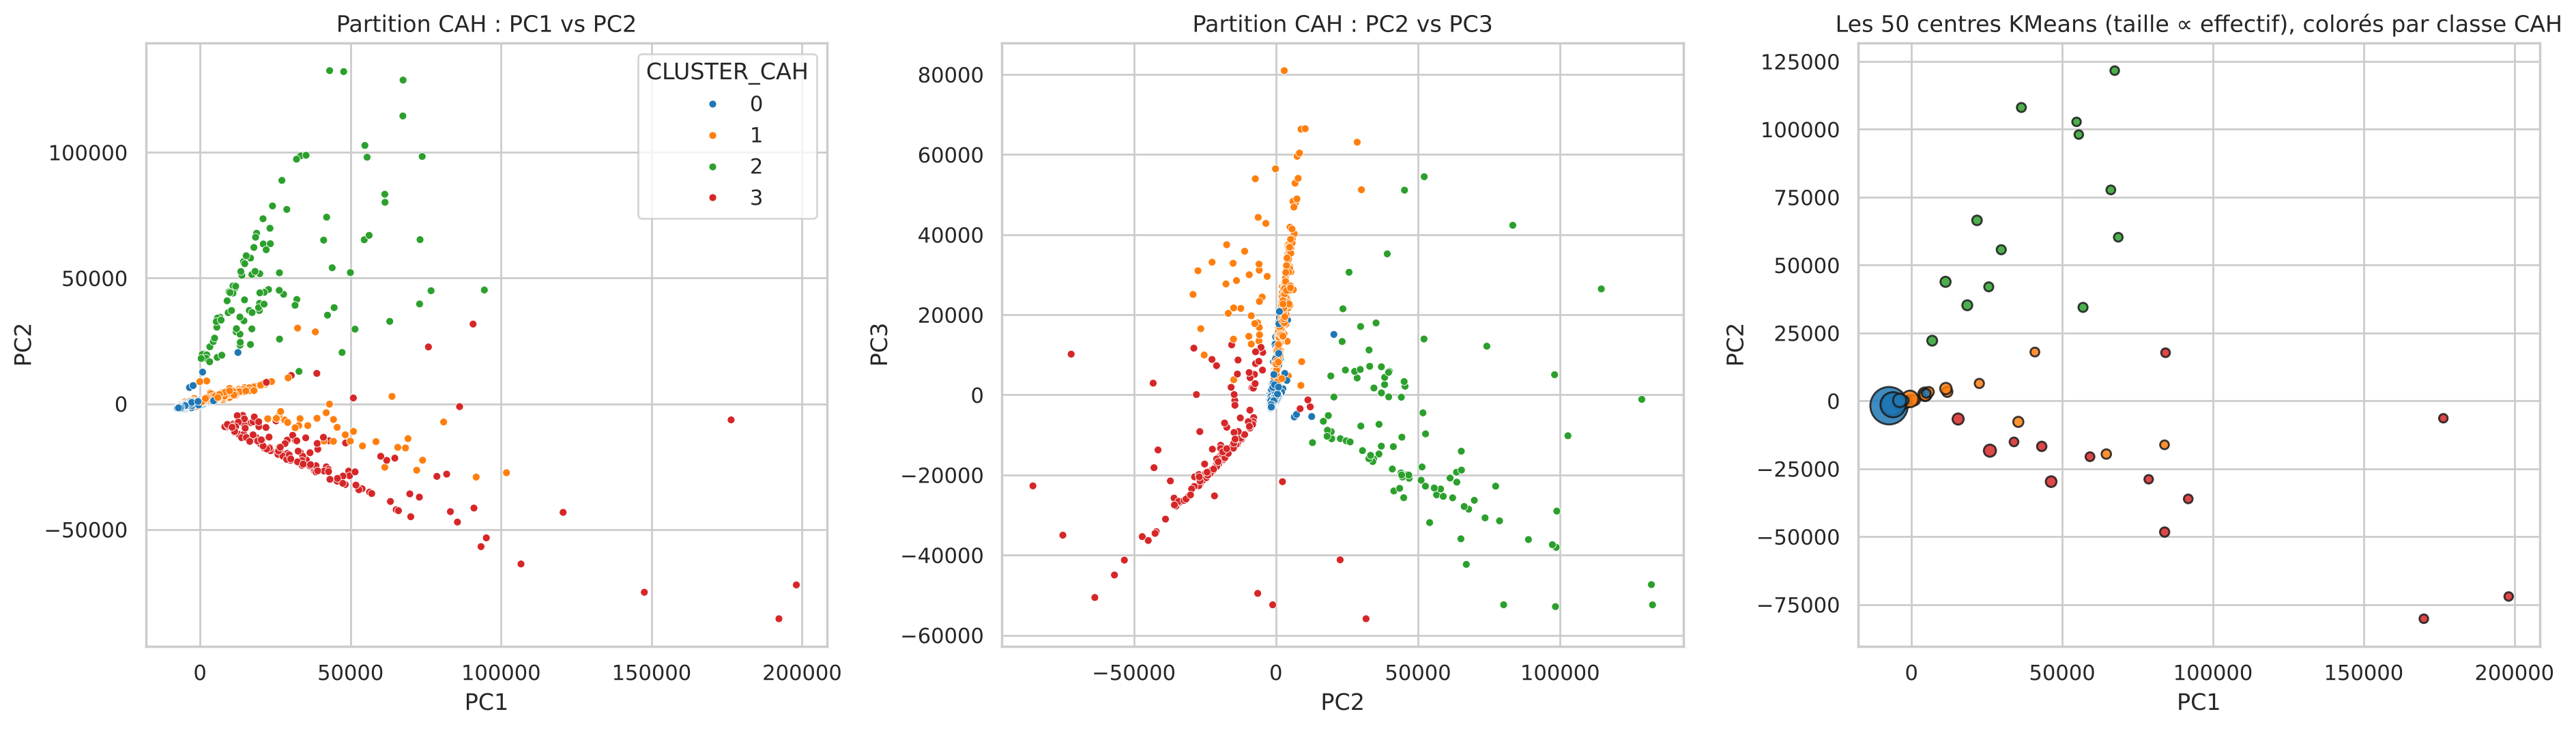

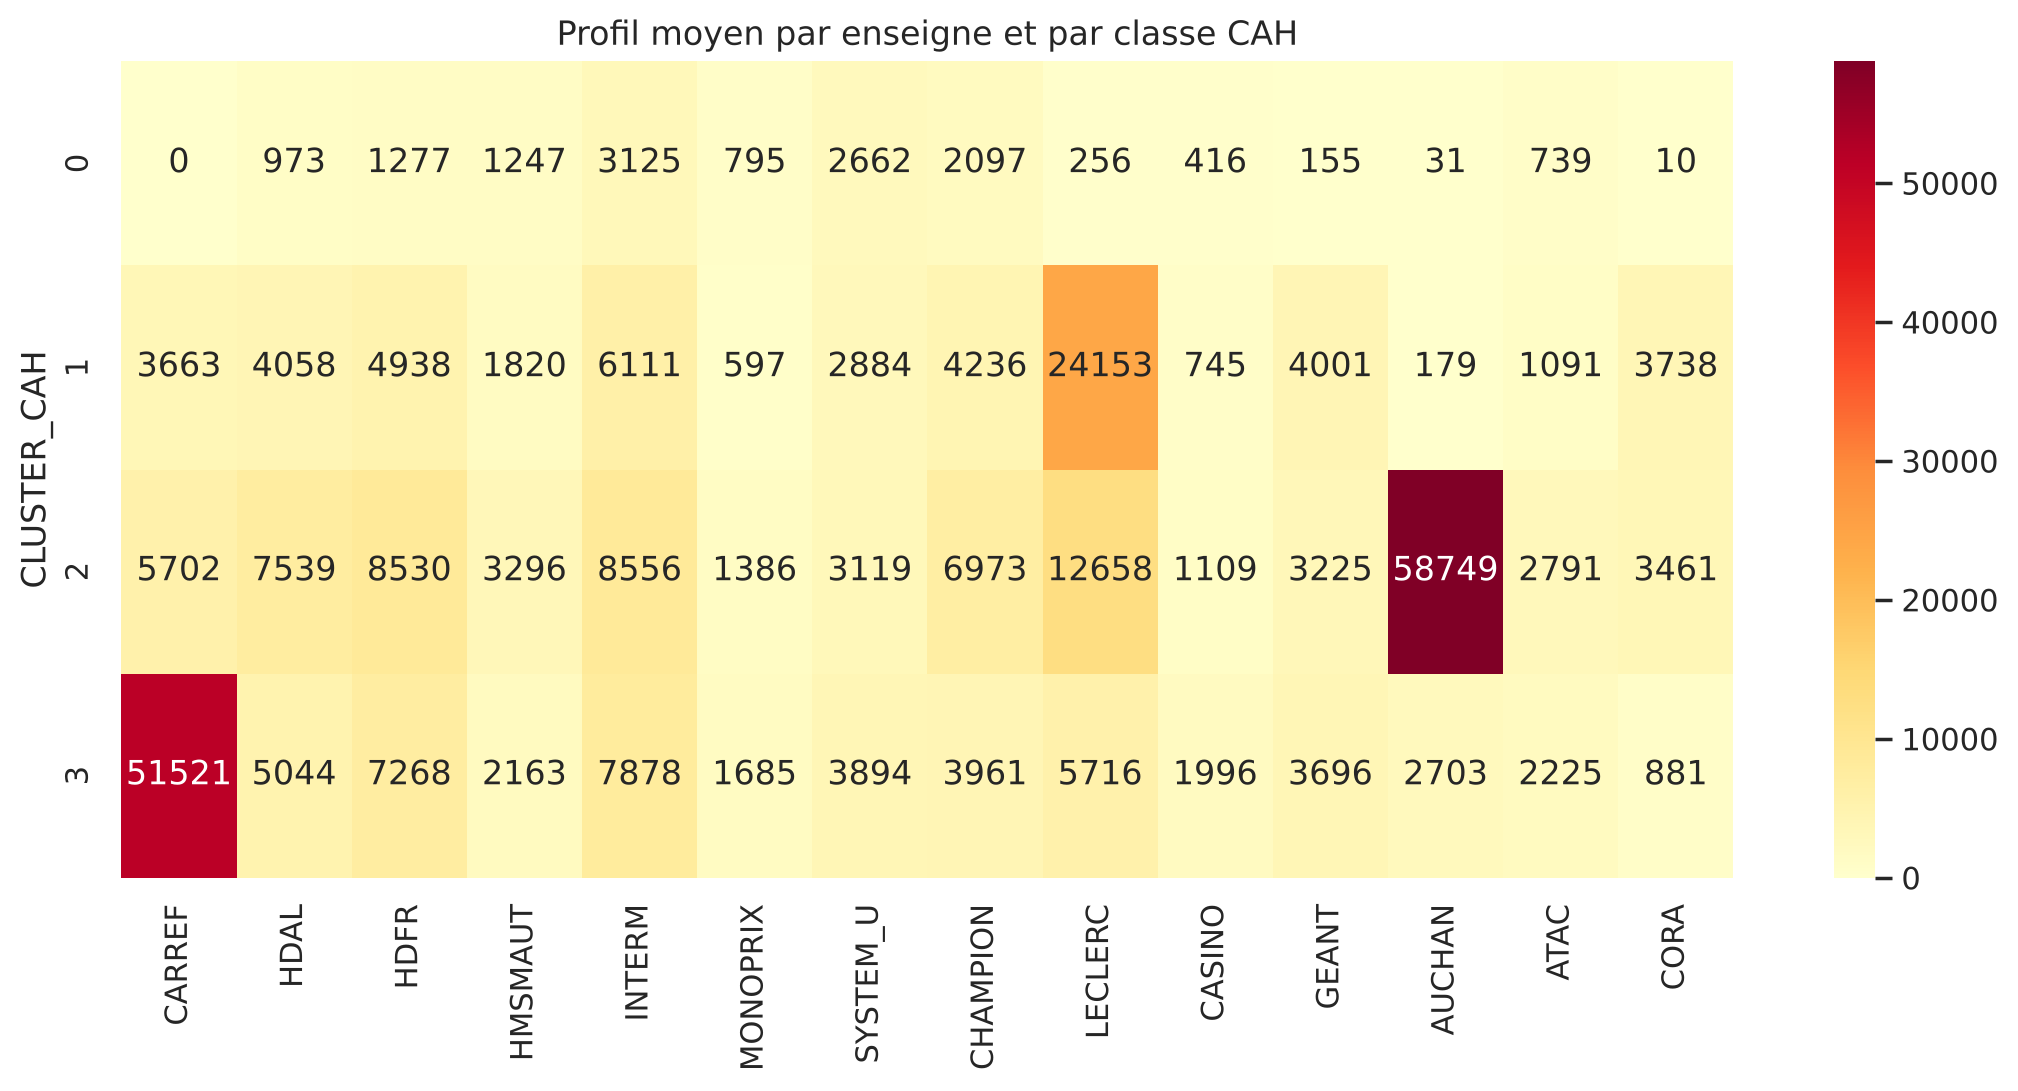

CAH,0,1,2,3
KMeans (k choisi),,,,
0,1748,339,20,41
1,0,2,78,1
2,0,28,0,93


In [19]:
# ---- Visualisation de la partition CAH dans l'espace latent + profils ----
pal = sns.color_palette("tab10", K_FINAL)
fig, ax = plt.subplots(1, 3, figsize=(19, 5.5))
sns.scatterplot(data=df_all, x="PC1", y="PC2", hue="CLUSTER_CAH", palette=pal, s=16, ax=ax[0])
ax[0].set_title("Partition CAH : PC1 vs PC2")
sns.scatterplot(data=df_all, x="PC2", y="PC3", hue="CLUSTER_CAH", palette=pal, s=16, ax=ax[1], legend=False)
ax[1].set_title("Partition CAH : PC2 vs PC3")
ax[2].scatter(centers[:, 0], centers[:, 1], s=20 + sizes * 0.5, c=[pal[l] for l in lab_micro], edgecolor="k", alpha=.85)
ax[2].set_title(f"Les {K_PRE} centres KMeans (taille ∝ effectif), colorés par classe CAH")
ax[2].set_xlabel("PC1"); ax[2].set_ylabel("PC2")
plt.tight_layout(); plt.show()

profile_cah = df_all.groupby("CLUSTER_CAH")[cols].mean()
plt.figure(figsize=(13, 3.5 + 0.45 * K_FINAL))
sns.heatmap(profile_cah, annot=True, fmt=".0f", cmap="YlOrRd")
plt.title("Profil moyen par enseigne et par classe CAH"); plt.show()

pd.crosstab(df_all["CLUSTER"], df_all["CLUSTER_CAH"], rownames=["KMeans (k choisi)"], colnames=["CAH"])

In [20]:
# ---- Synthèse des classes retenues (CAH) ----
glob = df[cols].mean()
rows, lignes = [], [f"### Synthèse des {K_FINAL} classes retenues", ""]
for c in sorted(df_all["CLUSTER_CAH"].unique()):
    sub = df_all[df_all["CLUSTER_CAH"] == c]
    n, share = len(sub), 100 * len(sub) / len(df_all)
    m = sub[cols].mean()
    lift = (m / glob)
    sur = lift[lift >= 1.5].sort_values(ascending=False).head(4)
    top = m.sort_values(ascending=False).head(3)
    sur_txt = ", ".join(f"{e} (x{v:.1f})" for e, v in sur.items()) if len(sur) else "aucune (profil proche de la moyenne)"
    top_txt = ", ".join(f"{e} ({v:.0f})" for e, v in top.items())
    lignes.append(f"- **Classe {c}** : {n} sites ({share:.1f} %). Enseignes sur-représentées (>= 1,5 x la moyenne) : {sur_txt}. "
                  f"Principales enseignes en volume moyen : {top_txt}. MEN03 moyen = {sub['MEN03'].mean():.0f} (global {df['MEN03'].mean():.0f}).")
    rows.append({"classe": c, "nb_sites": n, "part_%": round(share, 1), "enseignes_sur_representees": sur_txt,
                 "principales_enseignes": top_txt, "MEN03_moyen": round(sub["MEN03"].mean()), "DEP03_moyen": round(sub["DEP03"].mean()),
                 **{f"{p}_moyen": round(sub[p].mean(), 1) for p in pc_names_L[:3]}})
display(Markdown(chr(10).join(lignes)))
synth_classes = pd.DataFrame(rows)
synth_classes

### Synthèse des 4 classes retenues

- **Classe 0** : 1748 sites (74.4 %). Enseignes sur-représentées (>= 1,5 x la moyenne) : aucune (profil proche de la moyenne). Principales enseignes en volume moyen : INTERM (3125), SYSTEM_U (2662), CHAMPION (2097). MEN03 moyen = 6664 (global 10280).
- **Classe 1** : 369 sites (15.7 %). Enseignes sur-représentées (>= 1,5 x la moyenne) : LECLERC (x5.0), CORA (x4.7), GEANT (x3.7), HDAL (x2.1). Principales enseignes en volume moyen : LECLERC (24153), INTERM (6111), HDFR (4938). MEN03 moyen = 16116 (global 10280).
- **Classe 2** : 98 sites (4.2 %). Enseignes sur-représentées (>= 1,5 x la moyenne) : AUCHAN (x22.1), CORA (x4.4), HDAL (x3.8), HDFR (x3.4). Principales enseignes en volume moyen : AUCHAN (58749), LECLERC (12658), INTERM (8556). MEN03 moyen = 30935 (global 10280).
- **Classe 3** : 135 sites (5.7 %). Enseignes sur-représentées (>= 1,5 x la moyenne) : CARREF (x13.7), CASINO (x3.4), GEANT (x3.4), HDFR (x2.9). Principales enseignes en volume moyen : CARREF (51521), INTERM (7878), HDFR (7268). MEN03 moyen = 26158 (global 10280).

,classe,nb_sites,part_%,enseignes_sur_representees,principales_enseignes,MEN03_moyen,DEP03_moyen,PC1_moyen,PC2_moyen,PC3_moyen
0,0,1748,74.4,aucune (profil proche de la moyenne),"INTERM (3125), SYSTEM_U (2662), CHAMPION (2097)",6664,26086430,-6321.6,-1430.6,-2248.6
1,1,369,15.7,"LECLERC (x5.0), CORA (x4.7), GEANT (x3.7), HDA...","LECLERC (24153), INTERM (6111), HDFR (4938)",16116,62624151,7863.3,914.2,18462.5
2,2,98,4.2,"AUCHAN (x22.1), CORA (x4.4), HDAL (x3.8), HDFR...","AUCHAN (58749), LECLERC (12658), INTERM (8556)",30935,120935128,26108.7,50502.9,-9942.5
3,3,135,5.7,"CARREF (x13.7), CASINO (x3.4), GEANT (x3.4), H...","CARREF (51521), INTERM (7878), HDFR (7268)",26158,101740870,41407.3,-20637.2,-14131.7


## 9. Caractérisation des clusters par les variables d'origine : indice de dominance
**Objectif — faire le lien entre la Data Science et le client** : traduire des classes statistiques (issues de PC1…PC10) en **profils métier lisibles**, exprimés avec les variables que le client connaît (les enseignes, MEN03, DEP03).

**Indice de dominance (base 100)** de l'enseigne *e* dans le cluster *c* :

> **ID(c, e) = 100 × [part de *e* dans la valeur totale du cluster *c*] ÷ [part de *e* dans la valeur totale de tous les sites]**

- **100** : l'enseigne pèse dans le cluster autant que sur l'ensemble du parc ; **200** : deux fois plus ; **50** : deux fois moins.
- **≥ `DOM_FORT` (150)** dominance forte · **≥ `DOM_MOD` (120)** dominance modérée · **≤ `DOM_FAIBLE` (80)** sous-représentée · entre les deux : neutre.
- Une enseigne n'est déclarée **dominante** que si elle pèse au moins `PART_MIN` % de la valeur du cluster (on évite de mettre en avant une enseigne marginale).
- Un cluster est qualifié de **pôle** d'une enseigne si celle-ci est la plus pesante du cluster, pèse au moins `PART_POLE` % de sa valeur et a un indice ≥ `DOM_MOD` ; sinon le cluster est **multi-enseignes** (aucune enseigne ne domine).

Compléments : le **poids du cluster** dans le total de chaque enseigne, le **pouvoir discriminant (η²)** de chaque variable, et le contexte **MEN03 / DEP03** (variables non utilisées dans la PCA).

In [21]:
# ---- Calcul de l'indice de dominance ----
CL = CLUSTER_COL
clusters = [int(c_) for c_ in sorted(df_all[CL].unique())]
n_cl = len(clusters)
pal_cl = dict(zip(clusters, sns.color_palette("tab10", n_cl)))

V_tot = df_all[cols].sum()                                    # valeur totale par enseigne (tous sites)
V_cl = df_all.groupby(CL)[cols].sum()                         # valeur par cluster et par enseigne
part_glob = (V_tot / V_tot.sum()).replace(0, np.nan)          # structure globale des enseignes
part_cl = V_cl.div(V_cl.sum(axis=1), axis=0)                  # structure de chaque cluster
indice_dom = (100 * part_cl.div(part_glob, axis=1)).fillna(0) # INDICE DE DOMINANCE (base 100)
poids_cl = 100 * V_cl.div(V_tot, axis=1)                      # % du total de l'enseigne capté par chaque cluster
n_sites = df_all[CL].value_counts().sort_index()
part_sites = 100 * n_sites / len(df_all)
part_valeur = 100 * V_cl.sum(axis=1) / V_tot.sum()            # % de la valeur totale captée par le cluster

def niveau_dom(v):
    if v >= DOM_FORT: return "dominance forte"
    if v >= DOM_MOD: return "dominance modérée"
    if v <= DOM_FAIBLE: return "sous-représentée"
    return "neutre"

# enseigne leader de chaque cluster (la plus pesante) et test « pôle »
info = {}
for c in clusters:
    pc = 100 * part_cl.loc[c]
    ens = pc.idxmax()
    info[c] = {"ens": ens, "indice": float(indice_dom.loc[c, ens]), "part": float(pc[ens]),
               "pole": bool(pc[ens] >= PART_POLE and indice_dom.loc[c, ens] >= DOM_MOD)}

# noms lisibles pour le client (modifiables via NOMS_MANUELS)
noms = {}
for c in clusters:
    noms[c] = f"Pôle {info[c]['ens']}" if info[c]["pole"] else "Multi-enseignes"
doublons = pd.Series(noms).value_counts()
for c in clusters:
    if doublons[noms[c]] > 1:
        noms[c] = f"{noms[c]} ({c})"
    if c in NOMS_MANUELS:
        noms[c] = NOMS_MANUELS[c]
lab = {c: f"C{c} · {noms[c]}" for c in clusters}
df_all["NOM_CLUSTER"] = df_all[CL].map(lab)

print("Clusters nommés :", lab)
indice_dom.rename(index=lab).round(0)

Clusters nommés : {0: 'C0 · Multi-enseignes', 1: 'C1 · Pôle LECLERC', 2: 'C2 · Pôle AUCHAN', 3: 'C3 · Pôle CARREF'}


,CARREF,HDAL,HDFR,HMSMAUT,INTERM,MONOPRIX,SYSTEM_U,CHAMPION,LECLERC,CASINO,GEANT,AUCHAN,ATAC,CORA
CLUSTER_CAH,,,,,,,,,,,,,,
C0 · Multi-enseignes,0.0,112.0,115.0,191.0,172.0,214.0,216.0,172.0,12.0,160.0,32.0,3.0,173.0,3.0
C1 · Pôle LECLERC,49.0,103.0,99.0,62.0,75.0,36.0,52.0,77.0,250.0,63.0,183.0,3.0,56.0,237.0
C2 · Pôle AUCHAN,37.0,94.0,84.0,55.0,51.0,40.0,27.0,62.0,64.0,46.0,72.0,541.0,71.0,107.0
C3 · Pôle CARREF,422.0,79.0,90.0,45.0,59.0,62.0,43.0,45.0,37.0,105.0,105.0,31.0,71.0,35.0


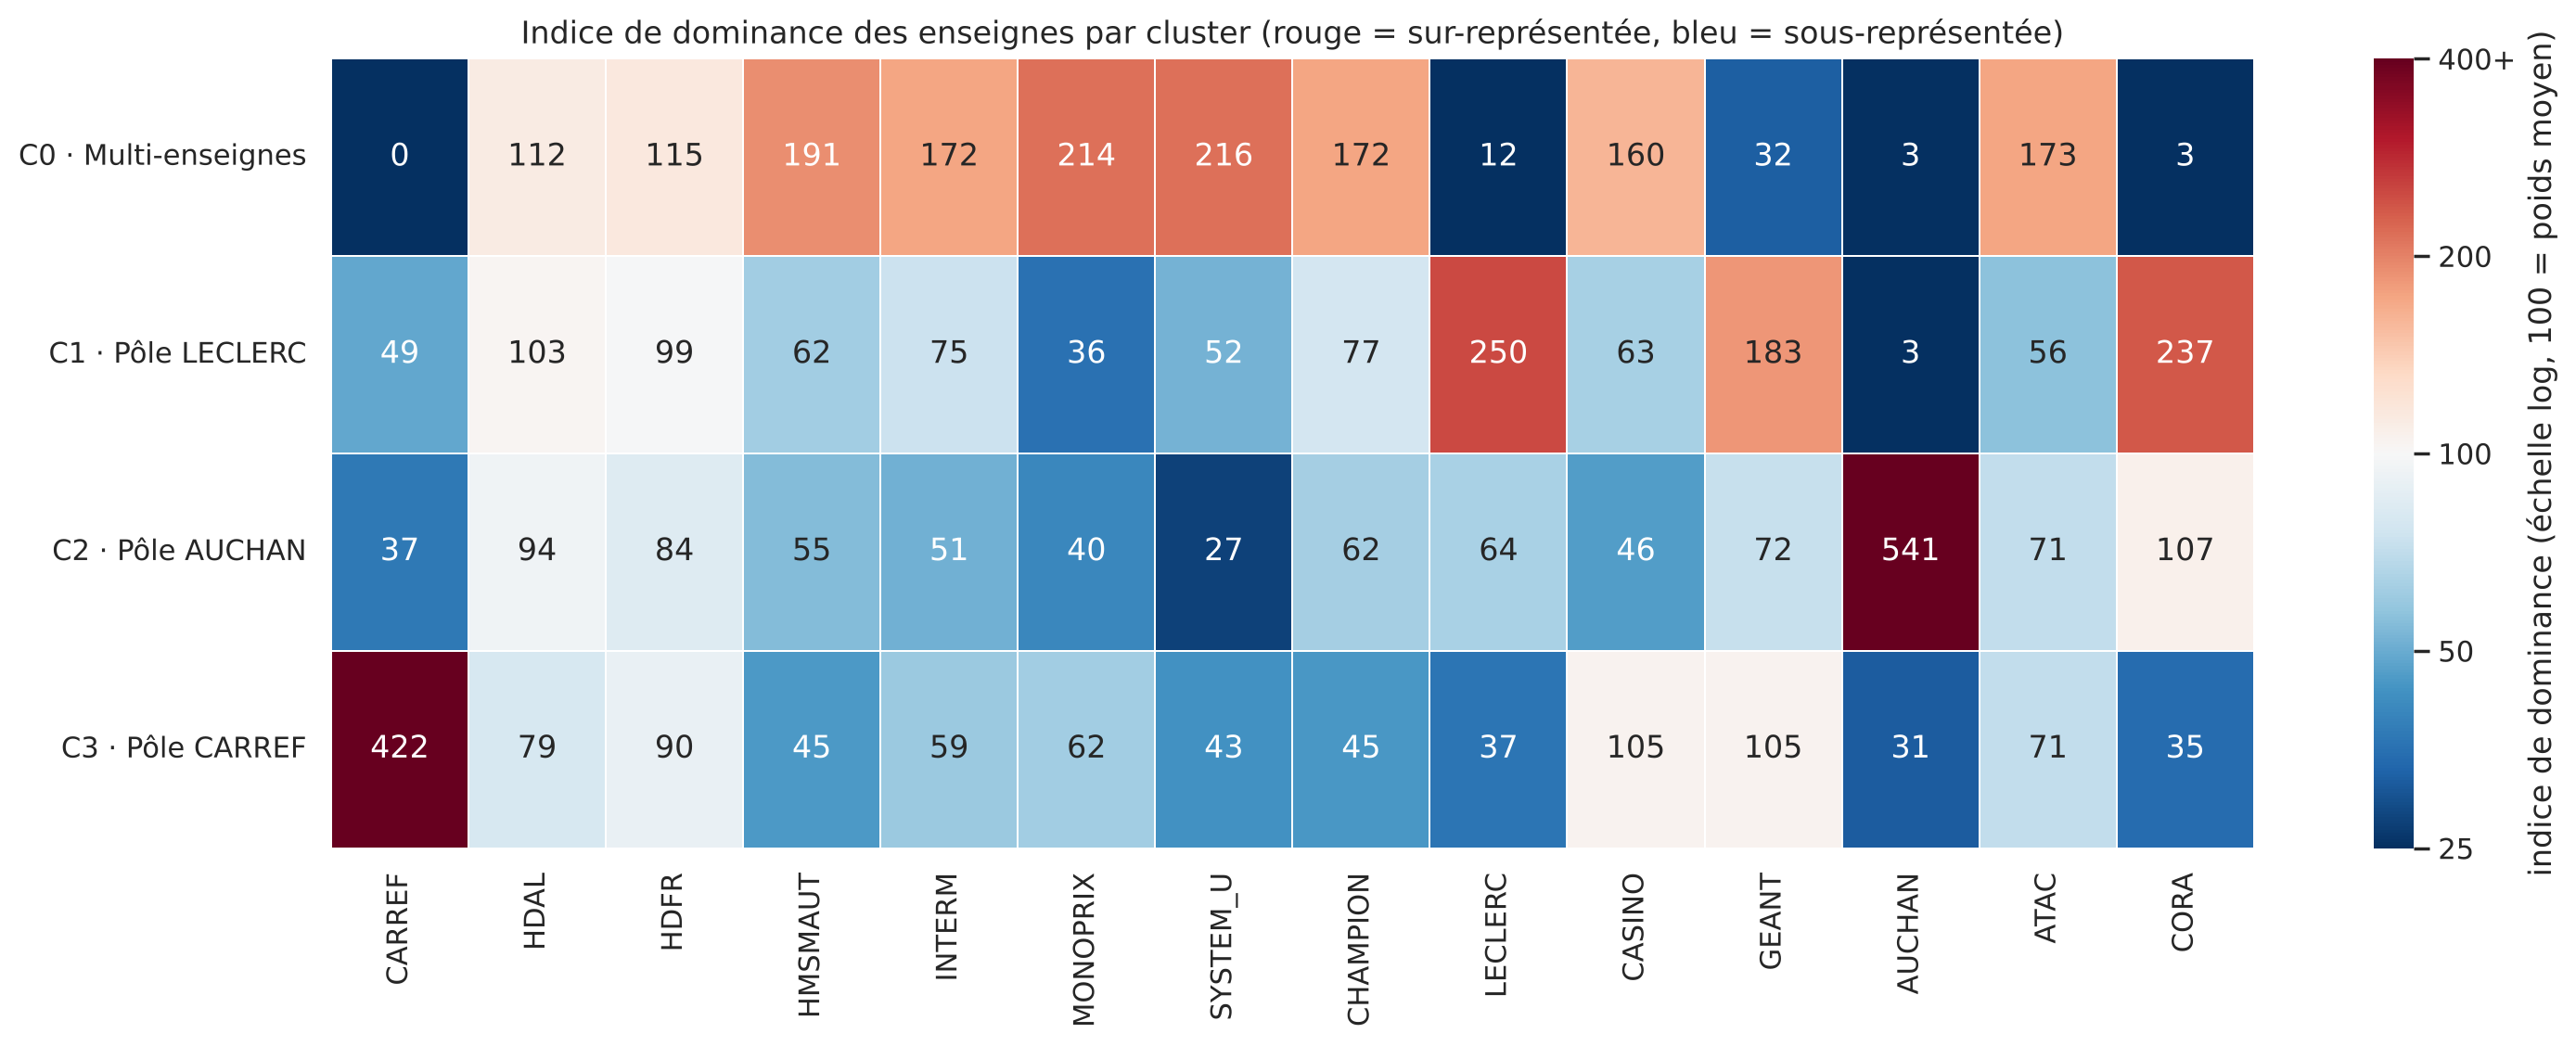

In [22]:
# ---- Graphique 1 : carte thermique de l'indice de dominance (échelle log, centre = 100) ----
idx_plot = indice_dom.rename(index=lab)
fig, ax = plt.subplots(figsize=(15, 2.4 + 0.85 * n_cl))
hm = sns.heatmap(np.log2(idx_plot.clip(lower=1) / 100), annot=idx_plot.round(0), fmt=".0f", cmap="RdBu_r",
                 center=0, vmin=-2, vmax=2, linewidths=.6, linecolor="white",
                 cbar_kws={"ticks": [-2, -1, 0, 1, 2], "label": "indice de dominance (échelle log, 100 = poids moyen)"}, ax=ax)
hm.collections[0].colorbar.set_ticklabels(["25", "50", "100", "200", "400+"])
ax.set_title("Indice de dominance des enseignes par cluster (rouge = sur-représentée, bleu = sous-représentée)")
ax.set_ylabel(""); plt.tight_layout(); plt.show()

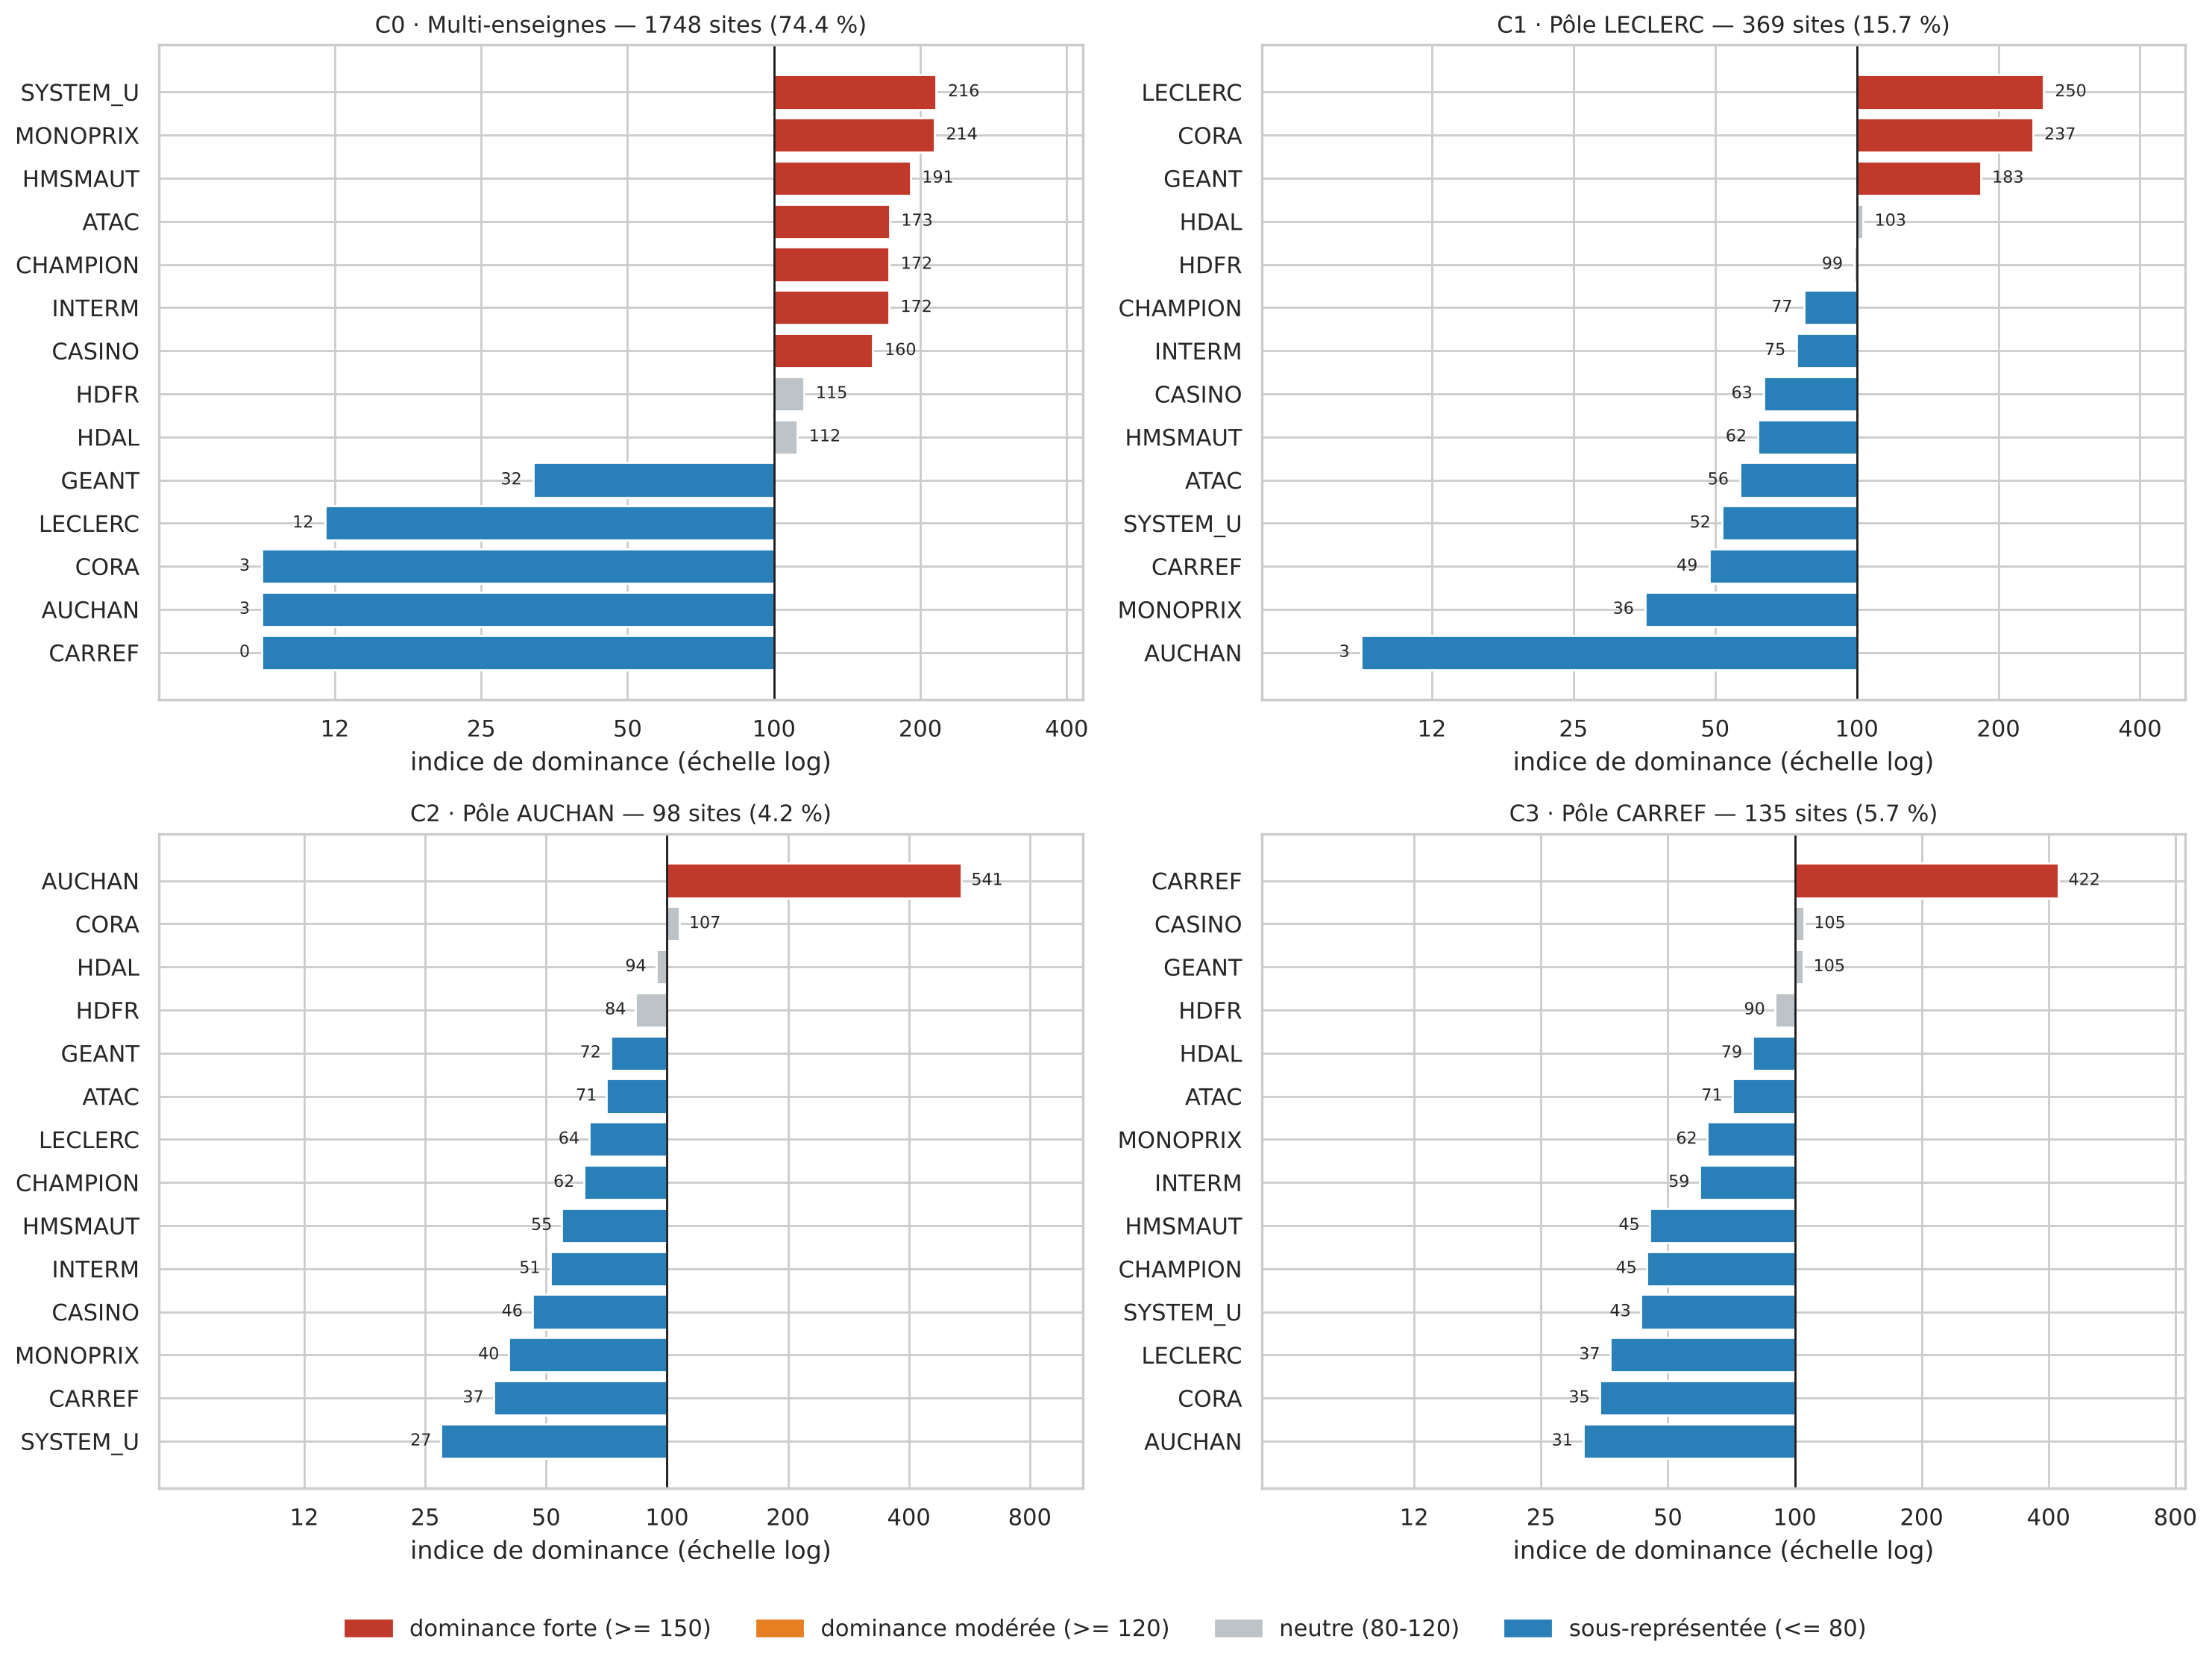

In [23]:
# ---- Graphique 2 : fiche visuelle de chaque cluster (indice de dominance, base 100) ----
couleurs = {"dominance forte": "#c0392b", "dominance modérée": "#e67e22", "neutre": "#bdc3c7", "sous-représentée": "#2980b9"}
ncol = 2; nrow = int(np.ceil(n_cl / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(15, 5.6 * nrow), squeeze=False)
for ax, c in zip(axes.ravel(), clusters):
    v = indice_dom.loc[c].sort_values()
    val = np.clip(np.log2(np.clip(v.values, 1, None) / 100), -3.5, None)
    ax.barh(v.index, val, color=[couleurs[niveau_dom(x)] for x in v.values])
    for yy, (x_, raw) in enumerate(zip(val, v.values)):
        ax.text(x_ + (0.08 if x_ >= 0 else -0.08), yy, f"{raw:.0f}", va="center", ha="left" if x_ >= 0 else "right", fontsize=8)
    ax.axvline(0, c="k", lw=1)
    ax.set_xticks([-3, -2, -1, 0, 1, 2, 3, 4]); ax.set_xticklabels(["12", "25", "50", "100", "200", "400", "800", "1600"])
    ax.set_xlim(-4.2, max(val.max() + 1.0, 2))
    ax.set_title(f"{lab[c]} — {n_sites[c]} sites ({part_sites[c]:.1f} %)", fontsize=11)
    ax.set_xlabel("indice de dominance (échelle log)")
for ax in axes.ravel()[n_cl:]: ax.axis("off")
handles = [plt.Rectangle((0, 0), 1, 1, color=col) for col in couleurs.values()]
fig.legend(handles, [f"{k} ({t})" for k, t in zip(couleurs, [f">= {DOM_FORT}", f">= {DOM_MOD}", f"{DOM_FAIBLE}-{DOM_MOD}", f"<= {DOM_FAIBLE}"])],
           loc="lower center", ncol=4, frameon=False)
plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.show()

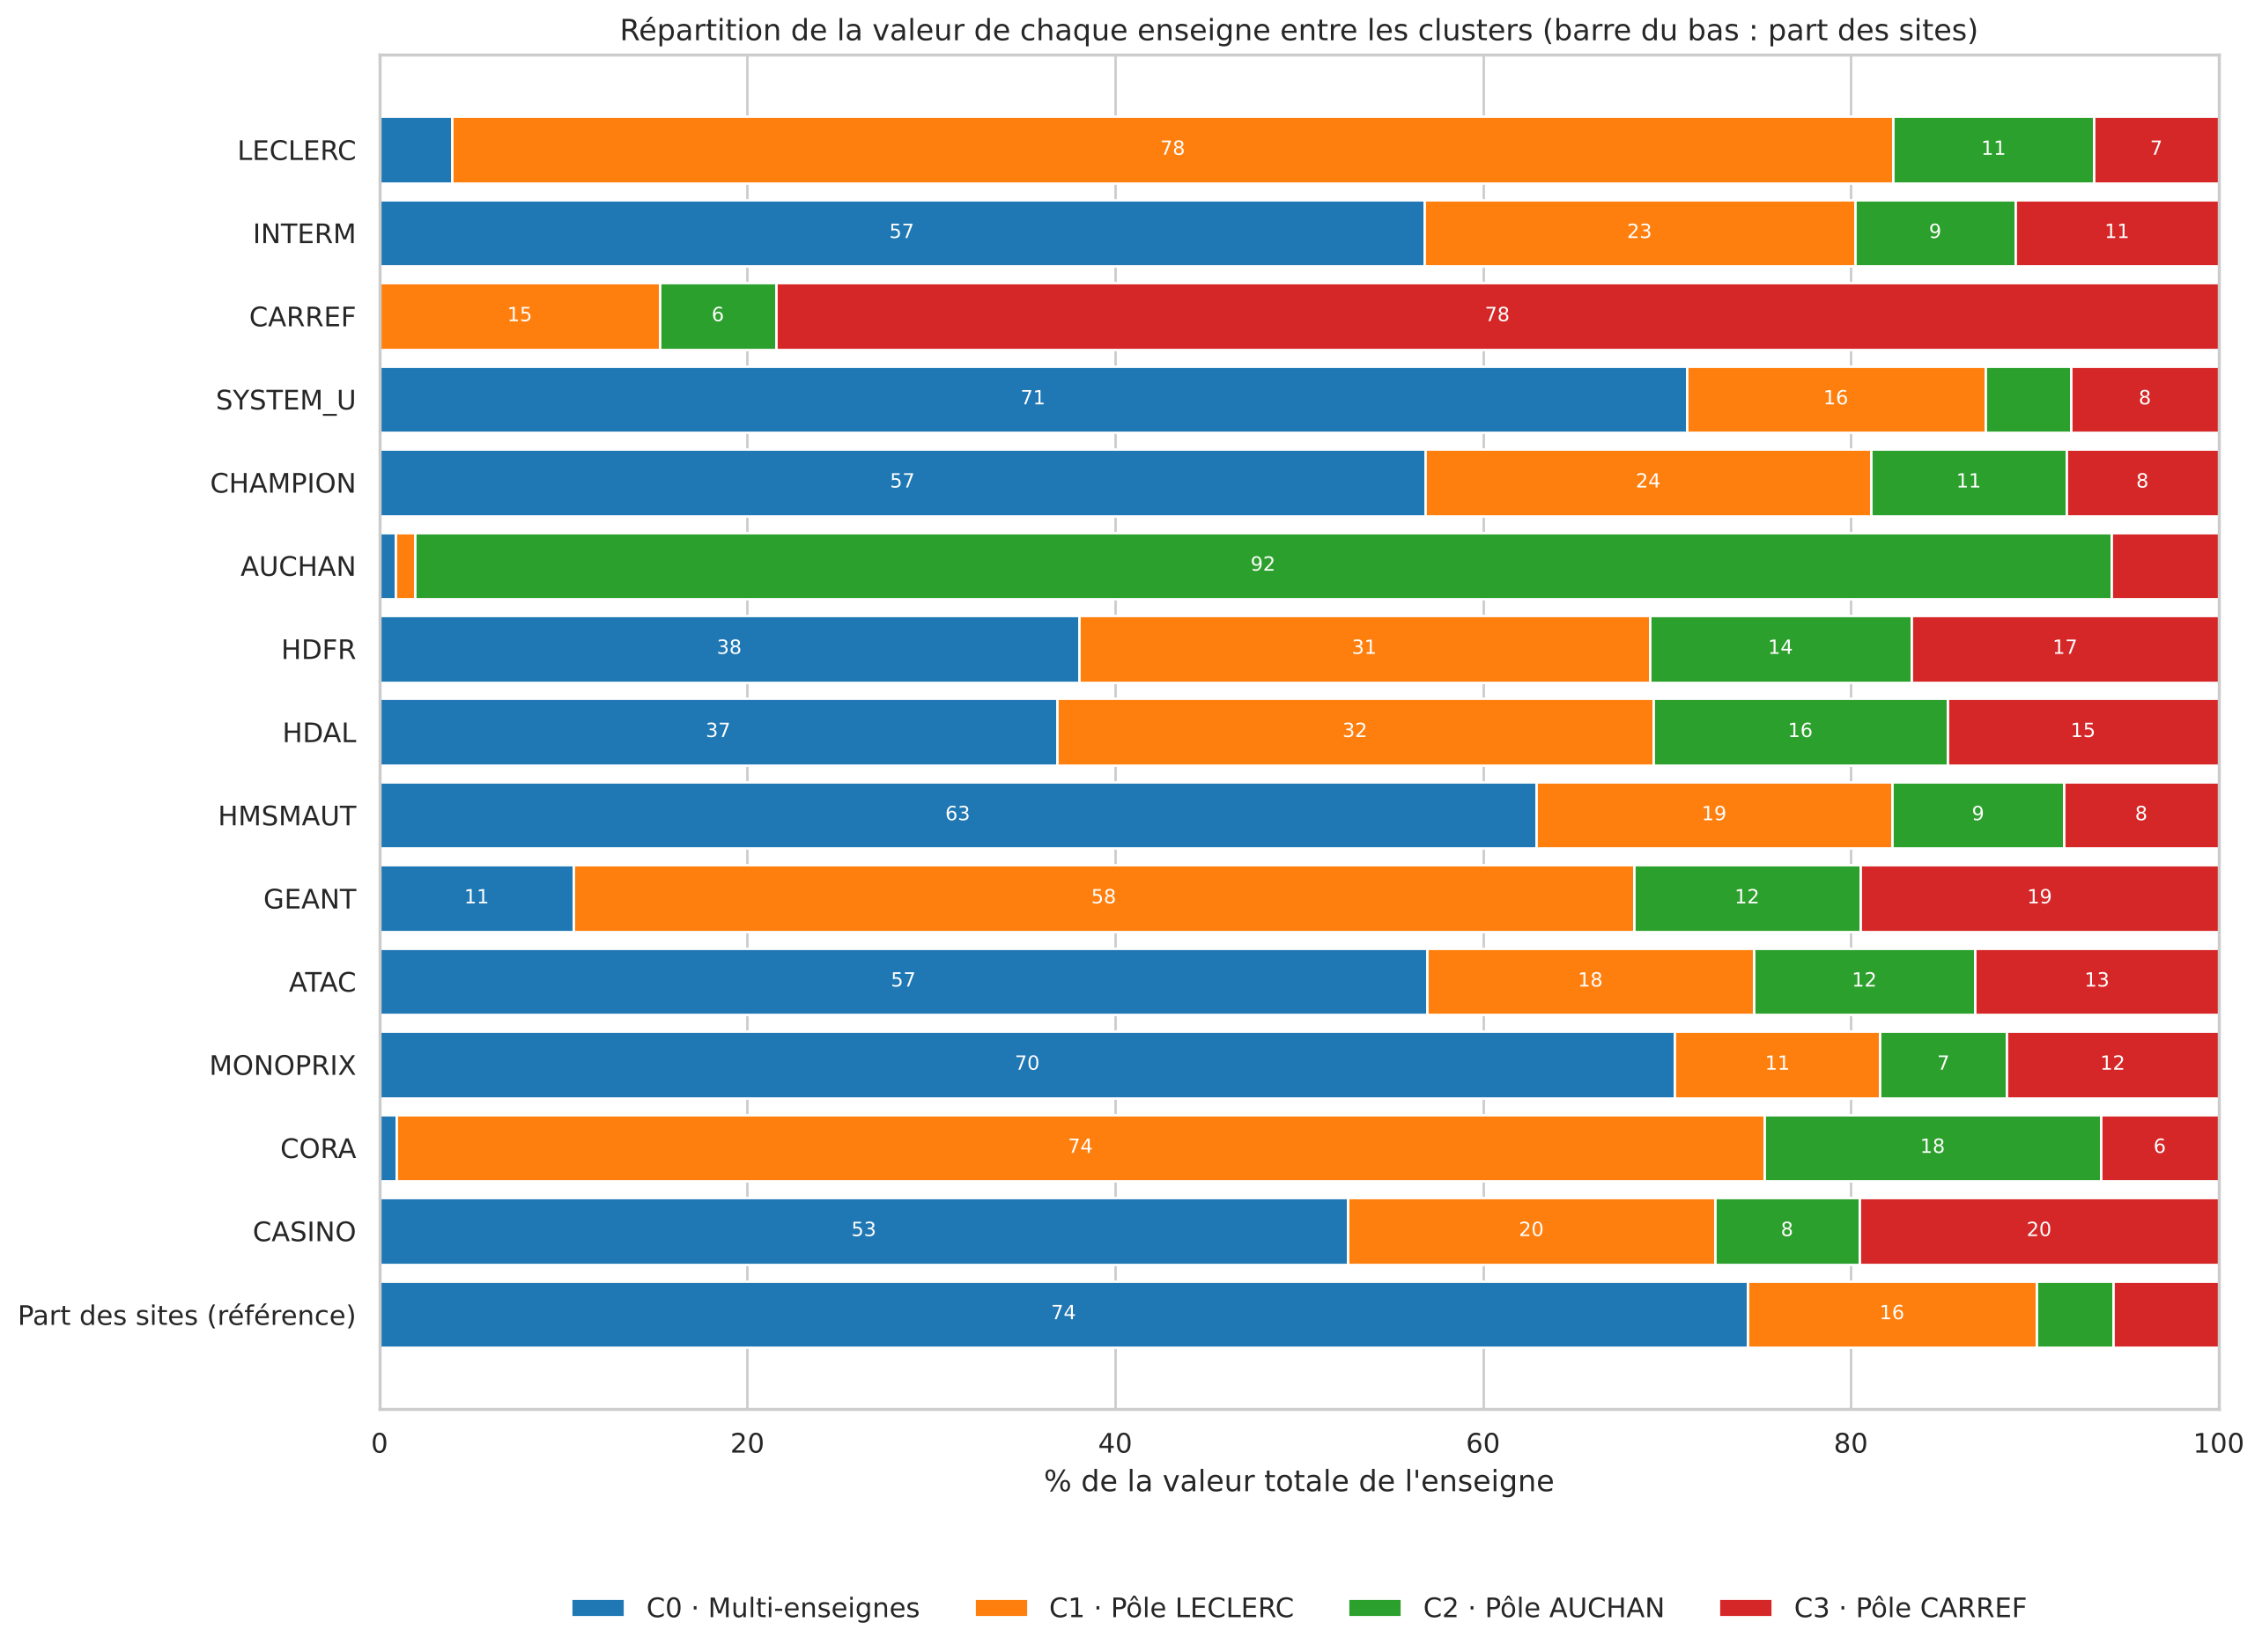

In [24]:
# ---- Graphique 3 : qui capte la valeur de chaque enseigne ? (poids des clusters) ----
ref = pd.DataFrame([part_sites.values], columns=clusters, index=["Part des sites (référence)"])
pw = pd.concat([ref, poids_cl.T.loc[V_tot.sort_values().index]])
fig, ax = plt.subplots(figsize=(13, 0.5 * len(pw) + 2))
left = np.zeros(len(pw))
for c in clusters:
    ax.barh(pw.index, pw[c].values, left=left, color=pal_cl[c], label=lab[c], edgecolor="white")
    for yy, (l_, w_) in enumerate(zip(left, pw[c].values)):
        if w_ >= 6: ax.text(l_ + w_ / 2, yy, f"{w_:.0f}", ha="center", va="center", color="white", fontsize=8)
    left += pw[c].values
ax.set_xlim(0, 100); ax.set_xlabel("% de la valeur totale de l'enseigne")
ax.set_title("Répartition de la valeur de chaque enseigne entre les clusters (barre du bas : part des sites)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=min(n_cl, 4), frameon=False)
plt.tight_layout(); plt.show()

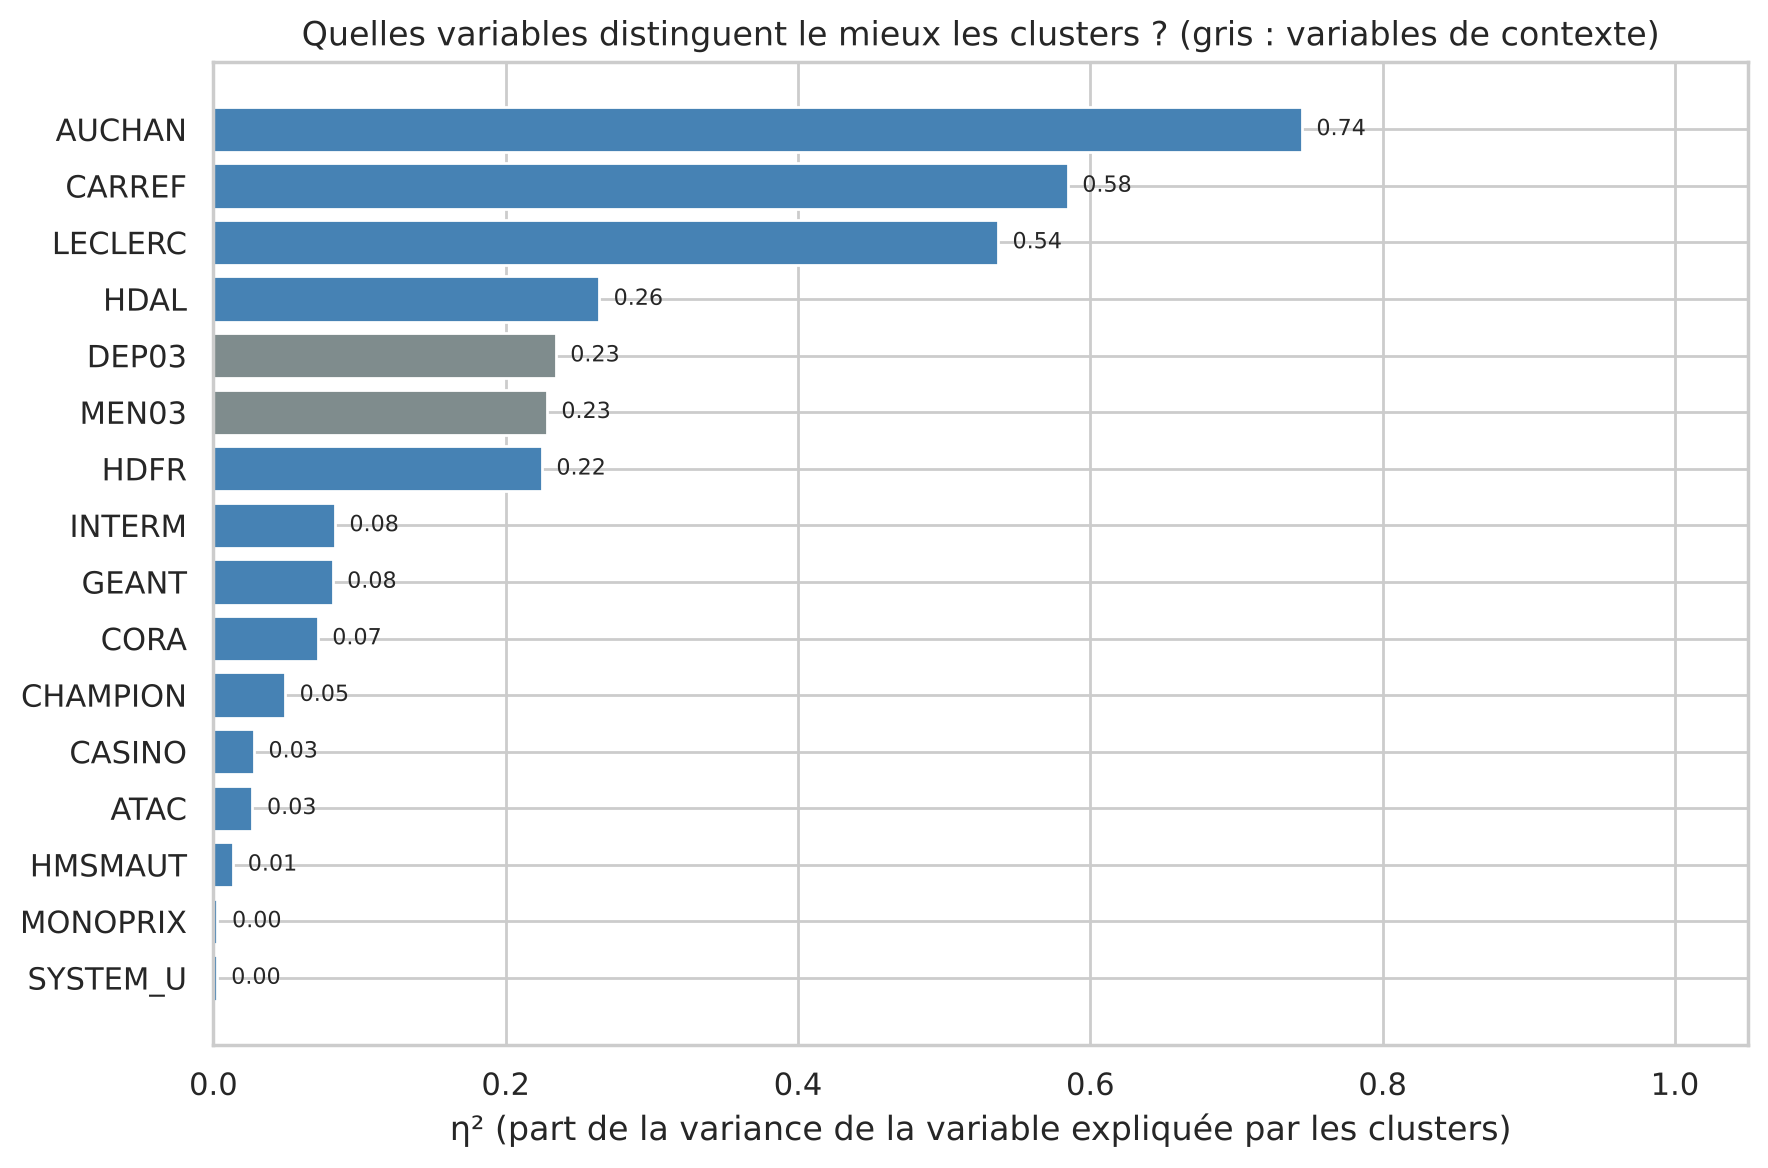

,AUCHAN,CARREF,LECLERC,HDAL,DEP03,MEN03,HDFR,INTERM,GEANT,CORA,CHAMPION,CASINO,ATAC,HMSMAUT,MONOPRIX,SYSTEM_U
eta2,0.745,0.585,0.537,0.264,0.234,0.228,0.225,0.083,0.082,0.071,0.049,0.028,0.027,0.014,0.003,0.002


In [25]:
# ---- Graphique 4 : pouvoir discriminant (η²) de chaque variable d'origine ----
def eta2(v):
    g = df_all.groupby(CL)[v]
    ssb = (g.count() * (g.mean() - df_all[v].mean()) ** 2).sum()
    sst = ((df_all[v] - df_all[v].mean()) ** 2).sum()
    return float(ssb / sst)

vars_all = cols + [c_ for c_ in ["MEN03", "DEP03"] if c_ in df_all.columns]
eta = pd.Series({v_: eta2(v_) for v_ in vars_all}).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(eta.index, eta.values, color=["#7f8c8d" if i in ("MEN03", "DEP03") else "steelblue" for i in eta.index])
for yy, v_ in enumerate(eta.values): ax.text(v_ + 0.01, yy, f"{v_:.2f}", va="center", fontsize=8)
ax.set_xlim(0, 1.05); ax.set_xlabel("η² (part de la variance de la variable expliquée par les clusters)")
ax.set_title("Quelles variables distinguent le mieux les clusters ? (gris : variables de contexte)")
plt.tight_layout(); plt.show()
eta.sort_values(ascending=False).round(3).to_frame("eta2").T

/tmp/ipykernel_235/2905837696.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_all, x="NOM_CLUSTER", y=v_, order=ordre, palette=palette_lab, ax=a_, fliersize=2)
/tmp/ipykernel_235/2905837696.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_all, x="NOM_CLUSTER", y=v_, order=ordre, palette=palette_lab, ax=a_, fliersize=2)


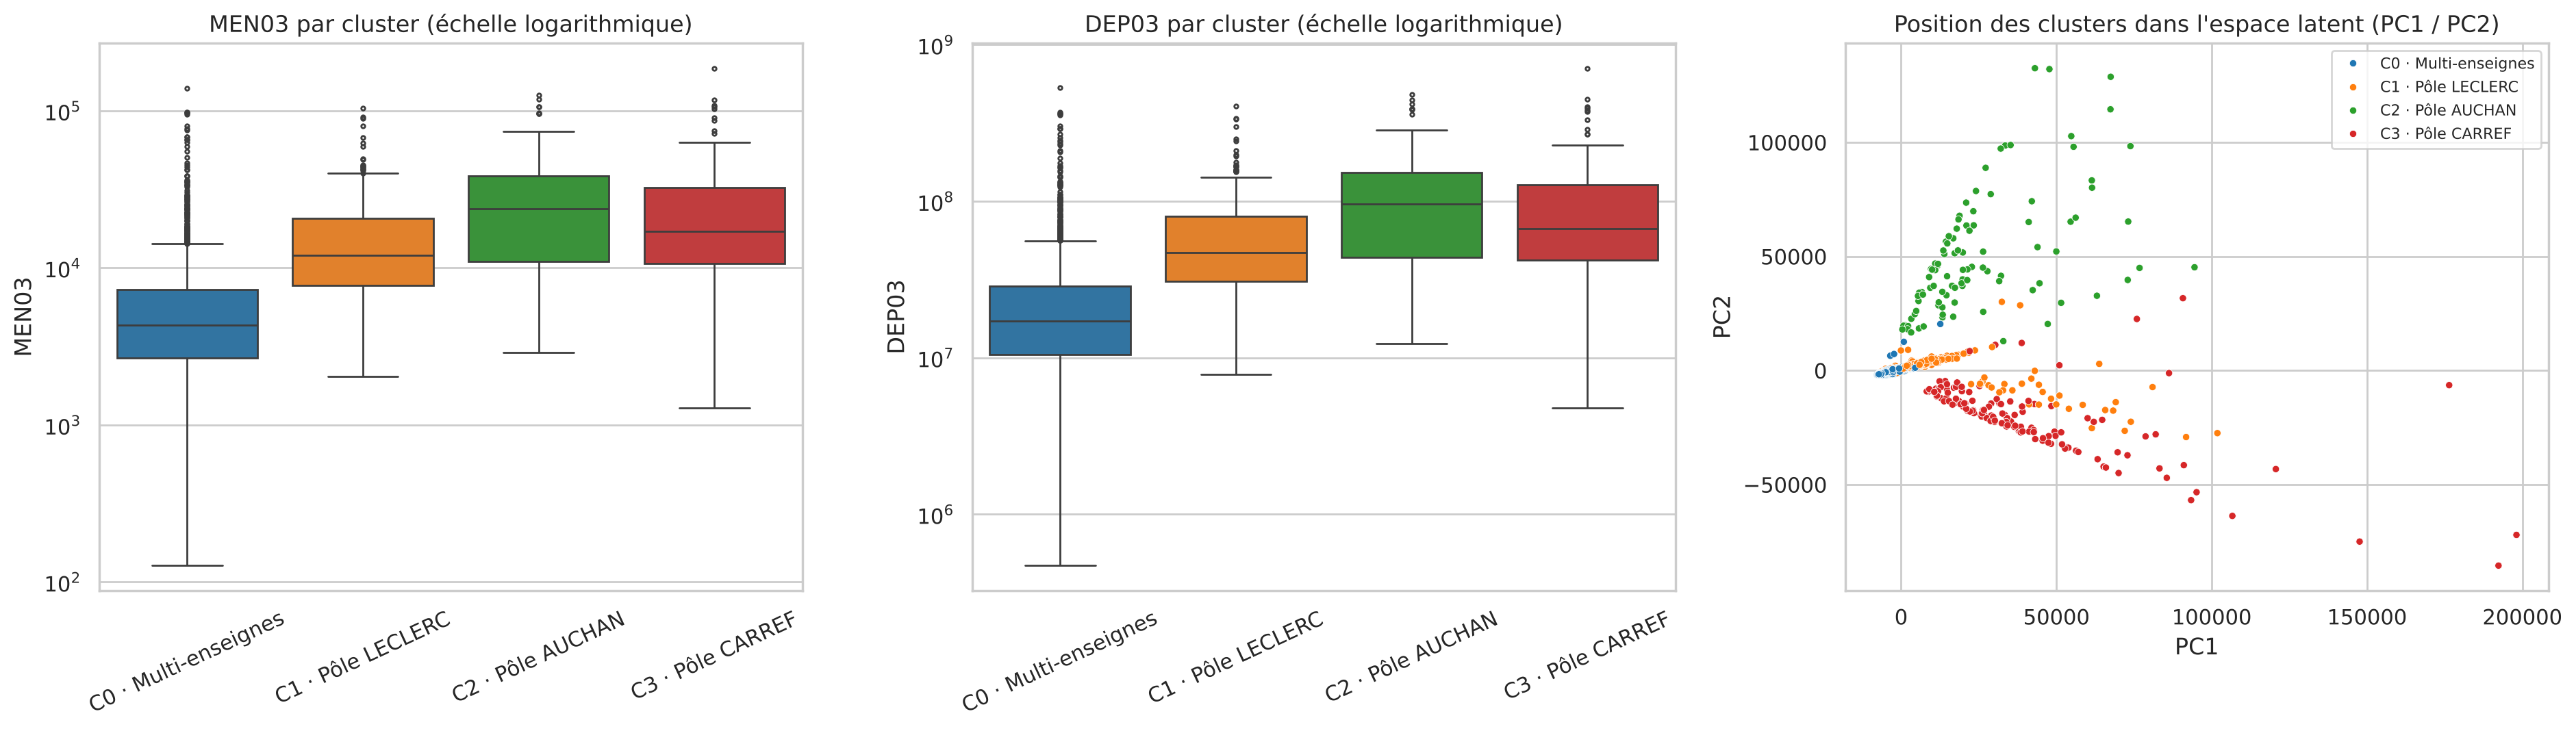

In [26]:
# ---- Graphique 5 : contexte (MEN03 / DEP03) et position des clusters dans l'espace latent ----
ordre = [lab[c] for c in clusters]
palette_lab = {lab[c]: pal_cl[c] for c in clusters}
fig, ax = plt.subplots(1, 3, figsize=(19, 5.5))
for a_, v_ in zip(ax[:2], ["MEN03", "DEP03"]):
    sns.boxplot(data=df_all, x="NOM_CLUSTER", y=v_, order=ordre, palette=palette_lab, ax=a_, fliersize=2)
    a_.set_yscale("log" if df_all[v_].min() > 0 else "symlog"); a_.set_xlabel(""); a_.tick_params(axis="x", rotation=25)
    a_.set_title(f"{v_} par cluster (échelle logarithmique)")
sns.scatterplot(data=df_all, x="PC1", y="PC2", hue="NOM_CLUSTER", hue_order=ordre, palette=palette_lab, s=14, ax=ax[2])
ax[2].set_title("Position des clusters dans l'espace latent (PC1 / PC2)")
ax[2].legend(fontsize=8, title="")
plt.tight_layout(); plt.show()

In [27]:
# ---- Fiches explicatives pour le client (générées à partir des chiffres) ----
from IPython.display import Markdown, display
NL = chr(10)
fmt0 = lambda x: f"{x:,.0f}".replace(",", " ")
pg = 100 * part_glob
mean_glob = df_all[cols].mean()
ctx = {v_: df_all[v_].mean() for v_ in ["MEN03", "DEP03"] if v_ in df_all.columns}

fiches, rows = [], []
for c in clusters:
    sub = df_all[df_all[CL] == c]
    idx_c = indice_dom.loc[c]
    pc = 100 * part_cl.loc[c]
    dom = idx_c[(pc >= PART_MIN) & (idx_c >= DOM_MOD)].sort_values(ascending=False)
    sous = idx_c[(idx_c <= DOM_FAIBLE) & (pg >= PART_MIN)].sort_values()
    ens, val, part_l, pole = info[c]["ens"], info[c]["indice"], info[c]["part"], info[c]["pole"]
    top3 = pc.sort_values(ascending=False).head(3)
    taille_site = sub[cols].sum(axis=1).mean()
    taille_glob = df_all[cols].sum(axis=1).mean()

    L_ = [f"#### {lab[c]} — {n_sites[c]} sites ({part_sites[c]:.1f} % des sites)", ""]
    if pole:
        L_.append(f"- **Enseigne leader** : **{ens}** pèse {part_l:.0f} % de la valeur du cluster contre {pg[ens]:.0f} % sur l'ensemble des sites (indice de dominance **{val:.0f}**, {niveau_dom(val)}).")
    else:
        L_.append(f"- **Aucune enseigne ne domine** : la plus pesante, {ens}, ne représente que {part_l:.0f} % de la valeur du cluster (seuil de pôle : {PART_POLE:.0f} %). Les plus présentes : " + ", ".join(f"{e} ({v:.0f} % contre {pg[e]:.0f} % au global)" for e, v in top3.items()) + ".")
    if len(dom):
        autres = dom if not pole else dom.drop(ens, errors="ignore")
        if len(autres):
            L_.append("- **Enseignes sur-représentées (indice de dominance)** : " + "; ".join(f"**{e}** ({v:.0f}, {niveau_dom(v)})" for e, v in autres.items()) + ".")
    if len(sous):
        L_.append("- **Enseignes sous-représentées** (importantes au global mais peu présentes ici) : " + ", ".join(f"{e} ({v:.0f})" for e, v in sous.items()) + ".")
    else:
        L_.append("- **Enseignes sous-représentées** : aucune enseigne majeure n'est nettement sous-représentée.")
    L_.append(f"- **Poids économique** : {part_sites[c]:.1f} % des sites mais **{part_valeur[c]:.1f} %** de la valeur totale des enseignes (valeur moyenne par site : {fmt0(taille_site)} contre {fmt0(taille_glob)} pour l'ensemble).")
    if pole:
        L_.append(f"- **Intensité de l'enseigne leader** ({ens}) : valeur moyenne par site = {fmt0(sub[ens].mean())}, soit {sub[ens].mean() / mean_glob[ens]:.1f} x la moyenne globale ({fmt0(mean_glob[ens])}) ; ce cluster capte {poids_cl.loc[c, ens]:.0f} % de la valeur totale de {ens}.")
    if ctx:
        L_.append("- **Contexte** : " + " ; ".join(f"{v_} moyen = {fmt0(sub[v_].mean())} (indice {100 * sub[v_].mean() / ctx[v_]:.0f})" for v_ in ctx) + ".")
    if pole and val >= DOM_FORT:
        L_.append(f"- **Lecture pour le client** : zones où **{ens}** pèse nettement plus que sur l'ensemble du parc ({part_l:.0f} % contre {pg[ens]:.0f} %), avec des sites de valeur {'supérieure' if taille_site > taille_glob else 'inférieure'} à la moyenne. Hypothèse à valider avec le client : cluster de référence pour analyser la performance de {ens}.")
    elif pole:
        L_.append(f"- **Lecture pour le client** : zones où **{ens}** est leader avec une dominance modérée, dans un contexte concurrentiel encore partagé. À valider avec le client.")
    else:
        absentes = ", ".join(sous.index[:3]) if len(sous) else "les principales enseignes"
        L_.append(f"- **Lecture pour le client** : zones de sites {'plus modestes' if taille_site < taille_glob else 'plus importants'} que la moyenne, où la valeur est répartie entre plusieurs enseignes ({', '.join(top3.index)}) et où {absentes} {'sont peu présentes' if len(sous) != 1 else 'est peu présente'}. Hypothèse à valider avec le client.")
    fiches.append(NL.join(L_))

    rows.append({"cluster": c, "nom": noms[c], "nb_sites": int(n_sites[c]), "part_sites_%": round(part_sites[c], 1),
                 "part_valeur_totale_%": round(part_valeur[c], 1), "enseigne_leader": ens,
                 "part_leader_%": round(part_l, 1), "indice_leader": round(val, 0),
                 "type": "pôle" if pole else "multi-enseignes", "niveau_leader": niveau_dom(val),
                 "enseignes_sur_representees": ", ".join(f"{e} ({v:.0f})" for e, v in dom.items()),
                 "enseignes_sous_representees": ", ".join(f"{e} ({v:.0f})" for e, v in sous.items()),
                 **{f"{v_}_moyen": round(sub[v_].mean()) for v_ in ctx},
                 **{f"indice_{v_}": round(100 * sub[v_].mean() / ctx[v_]) for v_ in ctx}})

txt_fiches = NL.join(["### Fiches clusters pour le client", ""] + [f + NL for f in fiches])
display(Markdown(txt_fiches))
carac_clients = pd.DataFrame(rows)
carac_clients

### Fiches clusters pour le client

#### C0 · Multi-enseignes — 1748 sites (74.4 % des sites)

- **Aucune enseigne ne domine** : la plus pesante, INTERM, ne représente que 23 % de la valeur du cluster (seuil de pôle : 30 %). Les plus présentes : INTERM (23 % contre 13 % au global), SYSTEM_U (19 % contre 9 % au global), CHAMPION (15 % contre 9 % au global).
- **Enseignes sur-représentées (indice de dominance)** : **SYSTEM_U** (216, dominance forte); **MONOPRIX** (214, dominance forte); **HMSMAUT** (191, dominance forte); **ATAC** (173, dominance forte); **CHAMPION** (172, dominance forte); **INTERM** (172, dominance forte).
- **Enseignes sous-représentées** (importantes au global mais peu présentes ici) : CARREF (0), AUCHAN (3), LECLERC (12).
- **Poids économique** : 74.4 % des sites mais **33.0 %** de la valeur totale des enseignes (valeur moyenne par site : 13 783 contre 31 102 pour l'ensemble).
- **Contexte** : MEN03 moyen = 6 664 (indice 65) ; DEP03 moyen = 26 086 430 (indice 65).
- **Lecture pour le client** : zones de sites plus modestes que la moyenne, où la valeur est répartie entre plusieurs enseignes (INTERM, SYSTEM_U, CHAMPION) et où CARREF, AUCHAN, LECLERC sont peu présentes. Hypothèse à valider avec le client.

#### C1 · Pôle LECLERC — 369 sites (15.7 % des sites)

- **Enseigne leader** : **LECLERC** pèse 39 % de la valeur du cluster contre 16 % sur l'ensemble des sites (indice de dominance **250**, dominance forte).
- **Enseignes sur-représentées (indice de dominance)** : **CORA** (237, dominance forte); **GEANT** (183, dominance forte).
- **Enseignes sous-représentées** (importantes au global mais peu présentes ici) : AUCHAN (3), CARREF (49), SYSTEM_U (52), INTERM (75), CHAMPION (77).
- **Poids économique** : 15.7 % des sites mais **31.4 %** de la valeur totale des enseignes (valeur moyenne par site : 62 213 contre 31 102 pour l'ensemble).
- **Intensité de l'enseigne leader** (LECLERC) : valeur moyenne par site = 24 153, soit 5.0 x la moyenne globale (4 839) ; ce cluster capte 78 % de la valeur totale de LECLERC.
- **Contexte** : MEN03 moyen = 16 116 (indice 157) ; DEP03 moyen = 62 624 151 (indice 156).
- **Lecture pour le client** : zones où **LECLERC** pèse nettement plus que sur l'ensemble du parc (39 % contre 16 %), avec des sites de valeur supérieure à la moyenne. Hypothèse à valider avec le client : cluster de référence pour analyser la performance de LECLERC.

#### C2 · Pôle AUCHAN — 98 sites (4.2 % des sites)

- **Enseigne leader** : **AUCHAN** pèse 46 % de la valeur du cluster contre 9 % sur l'ensemble des sites (indice de dominance **541**, dominance forte).
- **Enseignes sous-représentées** (importantes au global mais peu présentes ici) : SYSTEM_U (27), CARREF (37), INTERM (51), CHAMPION (62), LECLERC (64).
- **Poids économique** : 4.2 % des sites mais **17.0 %** de la valeur totale des enseignes (valeur moyenne par site : 127 096 contre 31 102 pour l'ensemble).
- **Intensité de l'enseigne leader** (AUCHAN) : valeur moyenne par site = 58 749, soit 22.1 x la moyenne globale (2 656) ; ce cluster capte 92 % de la valeur totale de AUCHAN.
- **Contexte** : MEN03 moyen = 30 935 (indice 301) ; DEP03 moyen = 120 935 128 (indice 301).
- **Lecture pour le client** : zones où **AUCHAN** pèse nettement plus que sur l'ensemble du parc (46 % contre 9 %), avec des sites de valeur supérieure à la moyenne. Hypothèse à valider avec le client : cluster de référence pour analyser la performance de AUCHAN.

#### C3 · Pôle CARREF — 135 sites (5.7 % des sites)

- **Enseigne leader** : **CARREF** pèse 51 % de la valeur du cluster contre 12 % sur l'ensemble des sites (indice de dominance **422**, dominance forte).
- **Enseignes sous-représentées** (importantes au global mais peu présentes ici) : AUCHAN (31), LECLERC (37), SYSTEM_U (43), CHAMPION (45), INTERM (59), HDAL (79).
- **Poids économique** : 5.7 % des sites mais **18.6 %** de la valeur totale des enseignes (valeur moyenne par site : 100 632 contre 31 102 pour l'ensemble).
- **Intensité de l'enseigne leader** (CARREF) : valeur moyenne par site = 51 521, soit 13.7 x la moyenne globale (3 773) ; ce cluster capte 78 % de la valeur totale de CARREF.
- **Contexte** : MEN03 moyen = 26 158 (indice 254) ; DEP03 moyen = 101 740 870 (indice 254).
- **Lecture pour le client** : zones où **CARREF** pèse nettement plus que sur l'ensemble du parc (51 % contre 12 %), avec des sites de valeur supérieure à la moyenne. Hypothèse à valider avec le client : cluster de référence pour analyser la performance de CARREF.


,cluster,nom,nb_sites,part_sites_%,part_valeur_totale_%,enseigne_leader,part_leader_%,indice_leader,type,niveau_leader,enseignes_sur_representees,enseignes_sous_representees,MEN03_moyen,DEP03_moyen,indice_MEN03,indice_DEP03
0,0,Multi-enseignes,1748,74.4,33.0,INTERM,22.7,172.0,multi-enseignes,dominance forte,"SYSTEM_U (216), MONOPRIX (214), HMSMAUT (191),...","CARREF (0), AUCHAN (3), LECLERC (12)",6664,26086430,65,65
1,1,Pôle LECLERC,369,15.7,31.4,LECLERC,38.8,250.0,pôle,dominance forte,"LECLERC (250), CORA (237), GEANT (183)","AUCHAN (3), CARREF (49), SYSTEM_U (52), INTERM...",16116,62624151,157,156
2,2,Pôle AUCHAN,98,4.2,17.0,AUCHAN,46.2,541.0,pôle,dominance forte,AUCHAN (541),"SYSTEM_U (27), CARREF (37), INTERM (51), CHAMP...",30935,120935128,301,301
3,3,Pôle CARREF,135,5.7,18.6,CARREF,51.2,422.0,pôle,dominance forte,CARREF (422),"AUCHAN (31), LECLERC (37), SYSTEM_U (43), CHAM...",26158,101740870,254,254


### Guide de lecture et points de vigilance (à partager avec le client)
- **Indice de dominance ≠ volume.** L'indice mesure la *structure* (le poids relatif d'une enseigne dans un cluster). Un cluster peut avoir une enseigne dominante tout en ayant de petits volumes : c'est pourquoi chaque fiche ajoute l'**intensité** (valeur moyenne par site) et le **poids économique** du cluster.
- **Effet de structure.** Quand les très gros acteurs (CARREF, AUCHAN, LECLERC) sont absents d'un cluster, l'indice des autres enseignes monte mécaniquement. C'est pourquoi un cluster n'est qualifié de **pôle** que si une enseigne y pèse au moins `PART_POLE` % ; sinon il est présenté comme **multi-enseignes**.
- **Enseignes à faible poids global** : un indice élevé sur une enseigne marginale est peu parlant ; la règle `PART_MIN` évite de la retenir comme dominante.
- **Données non standardisées** : la PCA et les clusters sont portés par les sites de grande taille (peu de sites, valeurs très élevées). Les petits clusters correspondent donc souvent à des **pôles de gros sites**.
- **Noms des clusters** : générés automatiquement (« Pôle X » quand une enseigne domine) ; ils peuvent être remplacés par des noms métier via `NOMS_MANUELS`.
- **Validation métier** : les lectures proposées sont des hypothèses issues des données ; elles doivent être confirmées avec le client (zone de chalandise, concurrence locale, etc.).

## 10. Caractérisation des composantes latentes par les variables d'origine
Corrélation de Pearson entre chaque composante retenue (PC1…PCL) et chaque variable d'origine.
- Variables **actives** : les 14 enseignes CARREF → CORA (utilisées dans la PCA)
- Variables **supplémentaires** : `MEN03`, `DEP03` (non utilisées dans la PCA, projetées a posteriori)

Lecture : |r| ≥ 0,7 très forte · ≥ 0,5 forte · ≥ 0,3 modérée. Le signe d'une composante est arbitraire ; seule l'opposition entre variables compte.

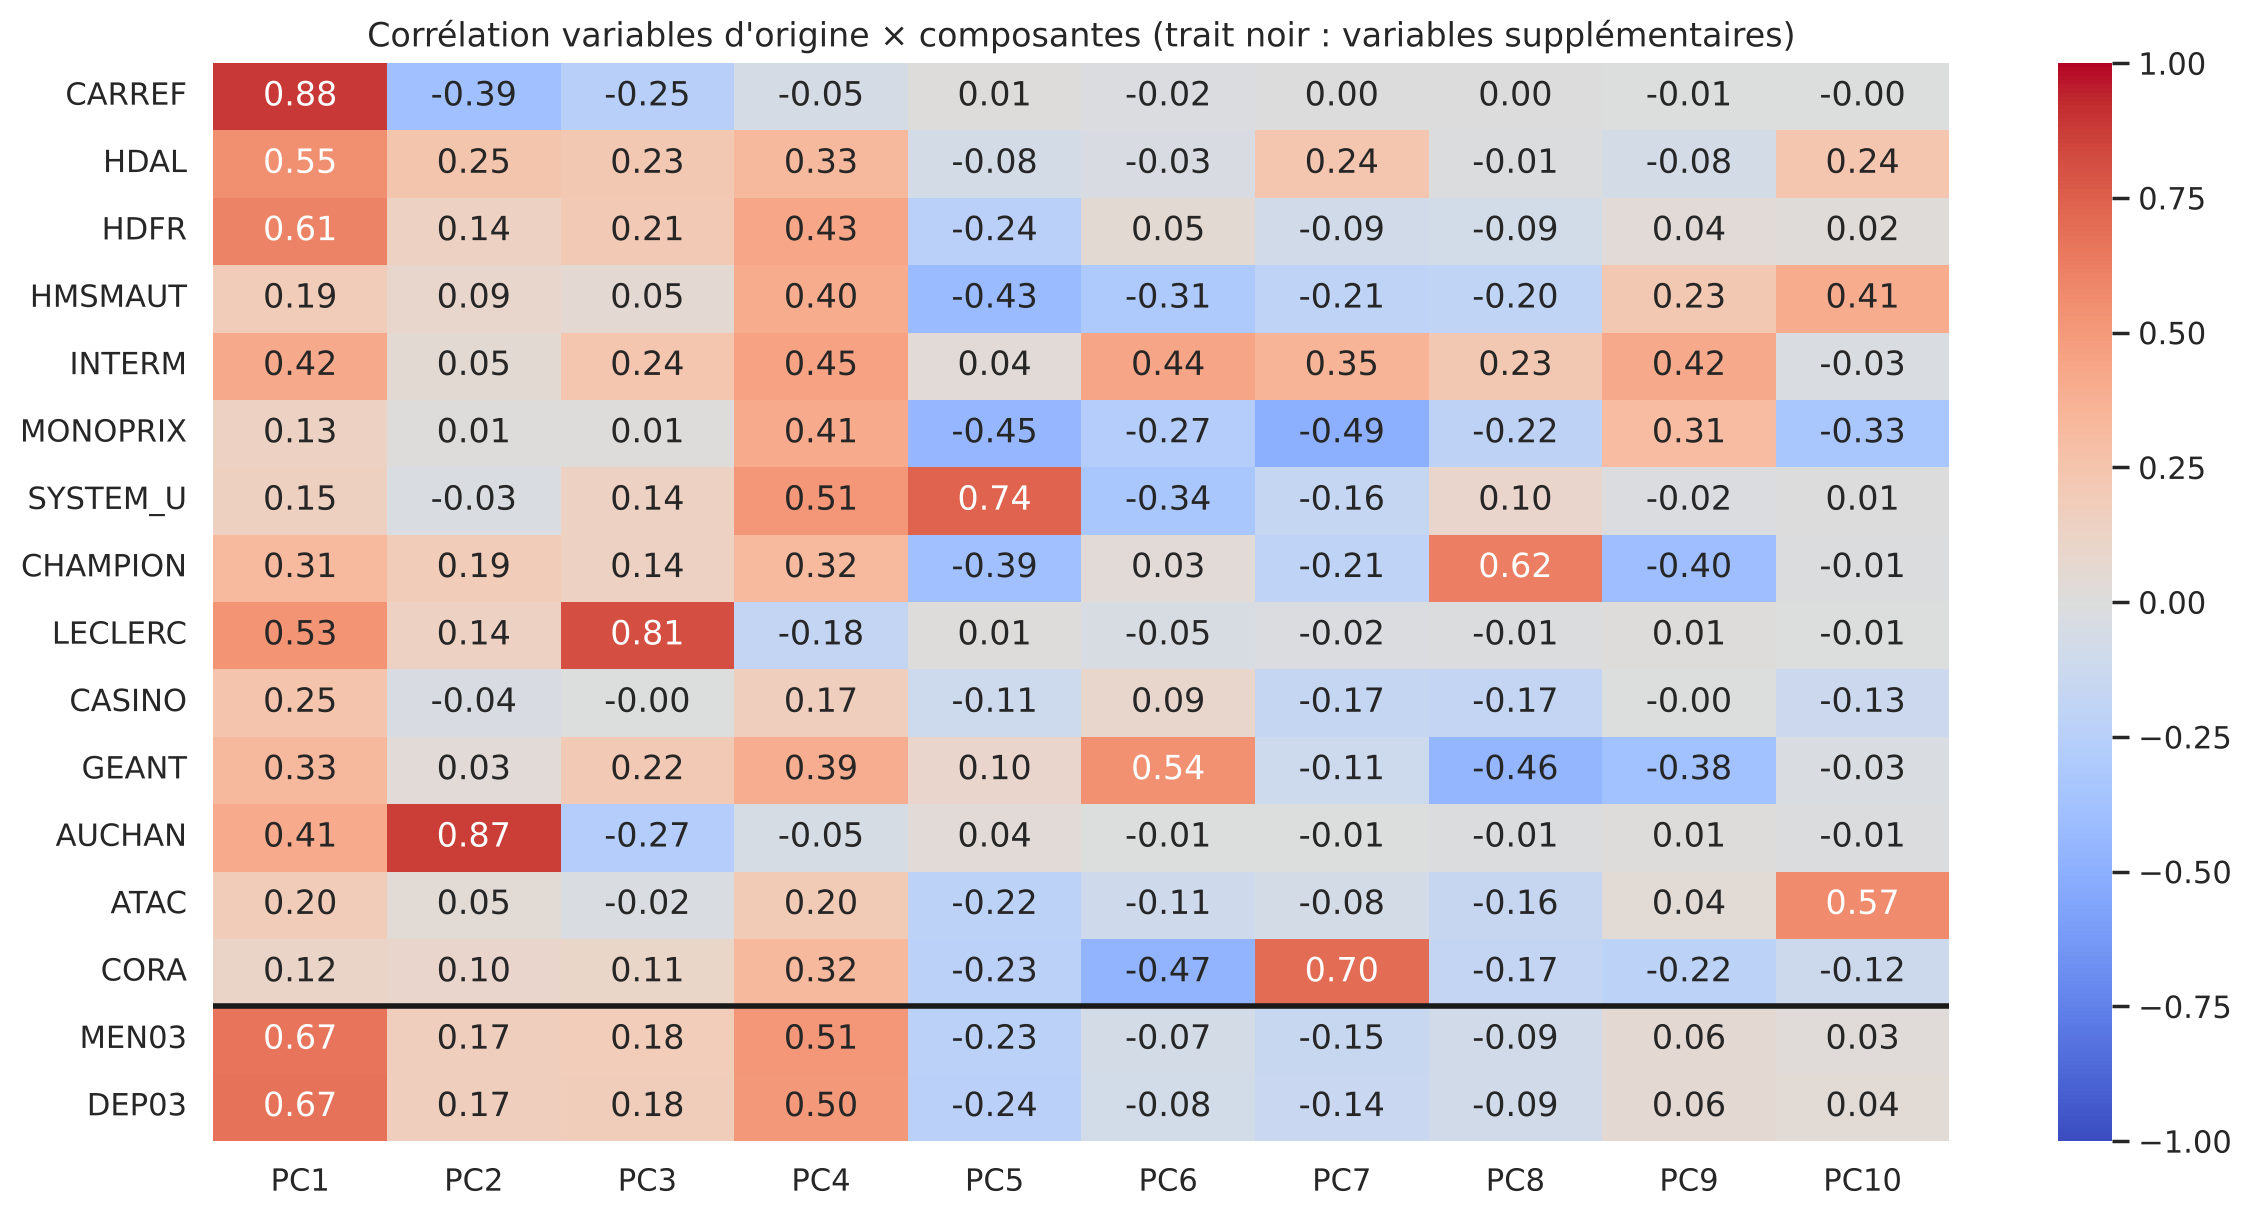

,type,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
CARREF,active,0.88,-0.39,-0.25,-0.05,0.01,-0.02,0.00,0.00,-0.01,-0.00
HDAL,active,0.55,0.25,0.23,0.33,-0.08,-0.03,0.24,-0.01,-0.08,0.24
HDFR,active,0.61,0.14,0.21,0.43,-0.24,0.05,-0.09,-0.09,0.04,0.02
HMSMAUT,active,0.19,0.09,0.05,0.40,-0.43,-0.31,-0.21,-0.20,0.23,0.41
INTERM,active,0.42,0.05,0.24,0.45,0.04,0.44,0.35,0.23,0.42,-0.03
MONOPRIX,active,0.13,0.01,0.01,0.41,-0.45,-0.27,-0.49,-0.22,0.31,-0.33
SYSTEM_U,active,0.15,-0.03,0.14,0.51,0.74,-0.34,-0.16,0.10,-0.02,0.01
CHAMPION,active,0.31,0.19,0.14,0.32,-0.39,0.03,-0.21,0.62,-0.40,-0.01
LECLERC,active,0.53,0.14,0.81,-0.18,0.01,-0.05,-0.02,-0.01,0.01,-0.01
CASINO,active,0.25,-0.04,-0.00,0.17,-0.11,0.09,-0.17,-0.17,-0.00,-0.13


In [28]:
SUPP_COLS = [c for c in ["MEN03", "DEP03"] if c in df_all.columns]
orig_cols = cols + SUPP_COLS

corr = pd.DataFrame(
    {pc: [df_all[c].corr(df_all[pc]) for c in orig_cols] for pc in pc_names_L},
    index=orig_cols,
)
corr.insert(0, "type", ["active"] * len(cols) + ["supplémentaire"] * len(SUPP_COLS))

plt.figure(figsize=(14, 7))
sns.heatmap(corr.drop(columns="type").astype(float), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.axhline(len(cols), color="k", lw=2)
plt.title("Corrélation variables d'origine × composantes (trait noir : variables supplémentaires)")
plt.show()
corr.round(2)

Composantes synthétisées : 10


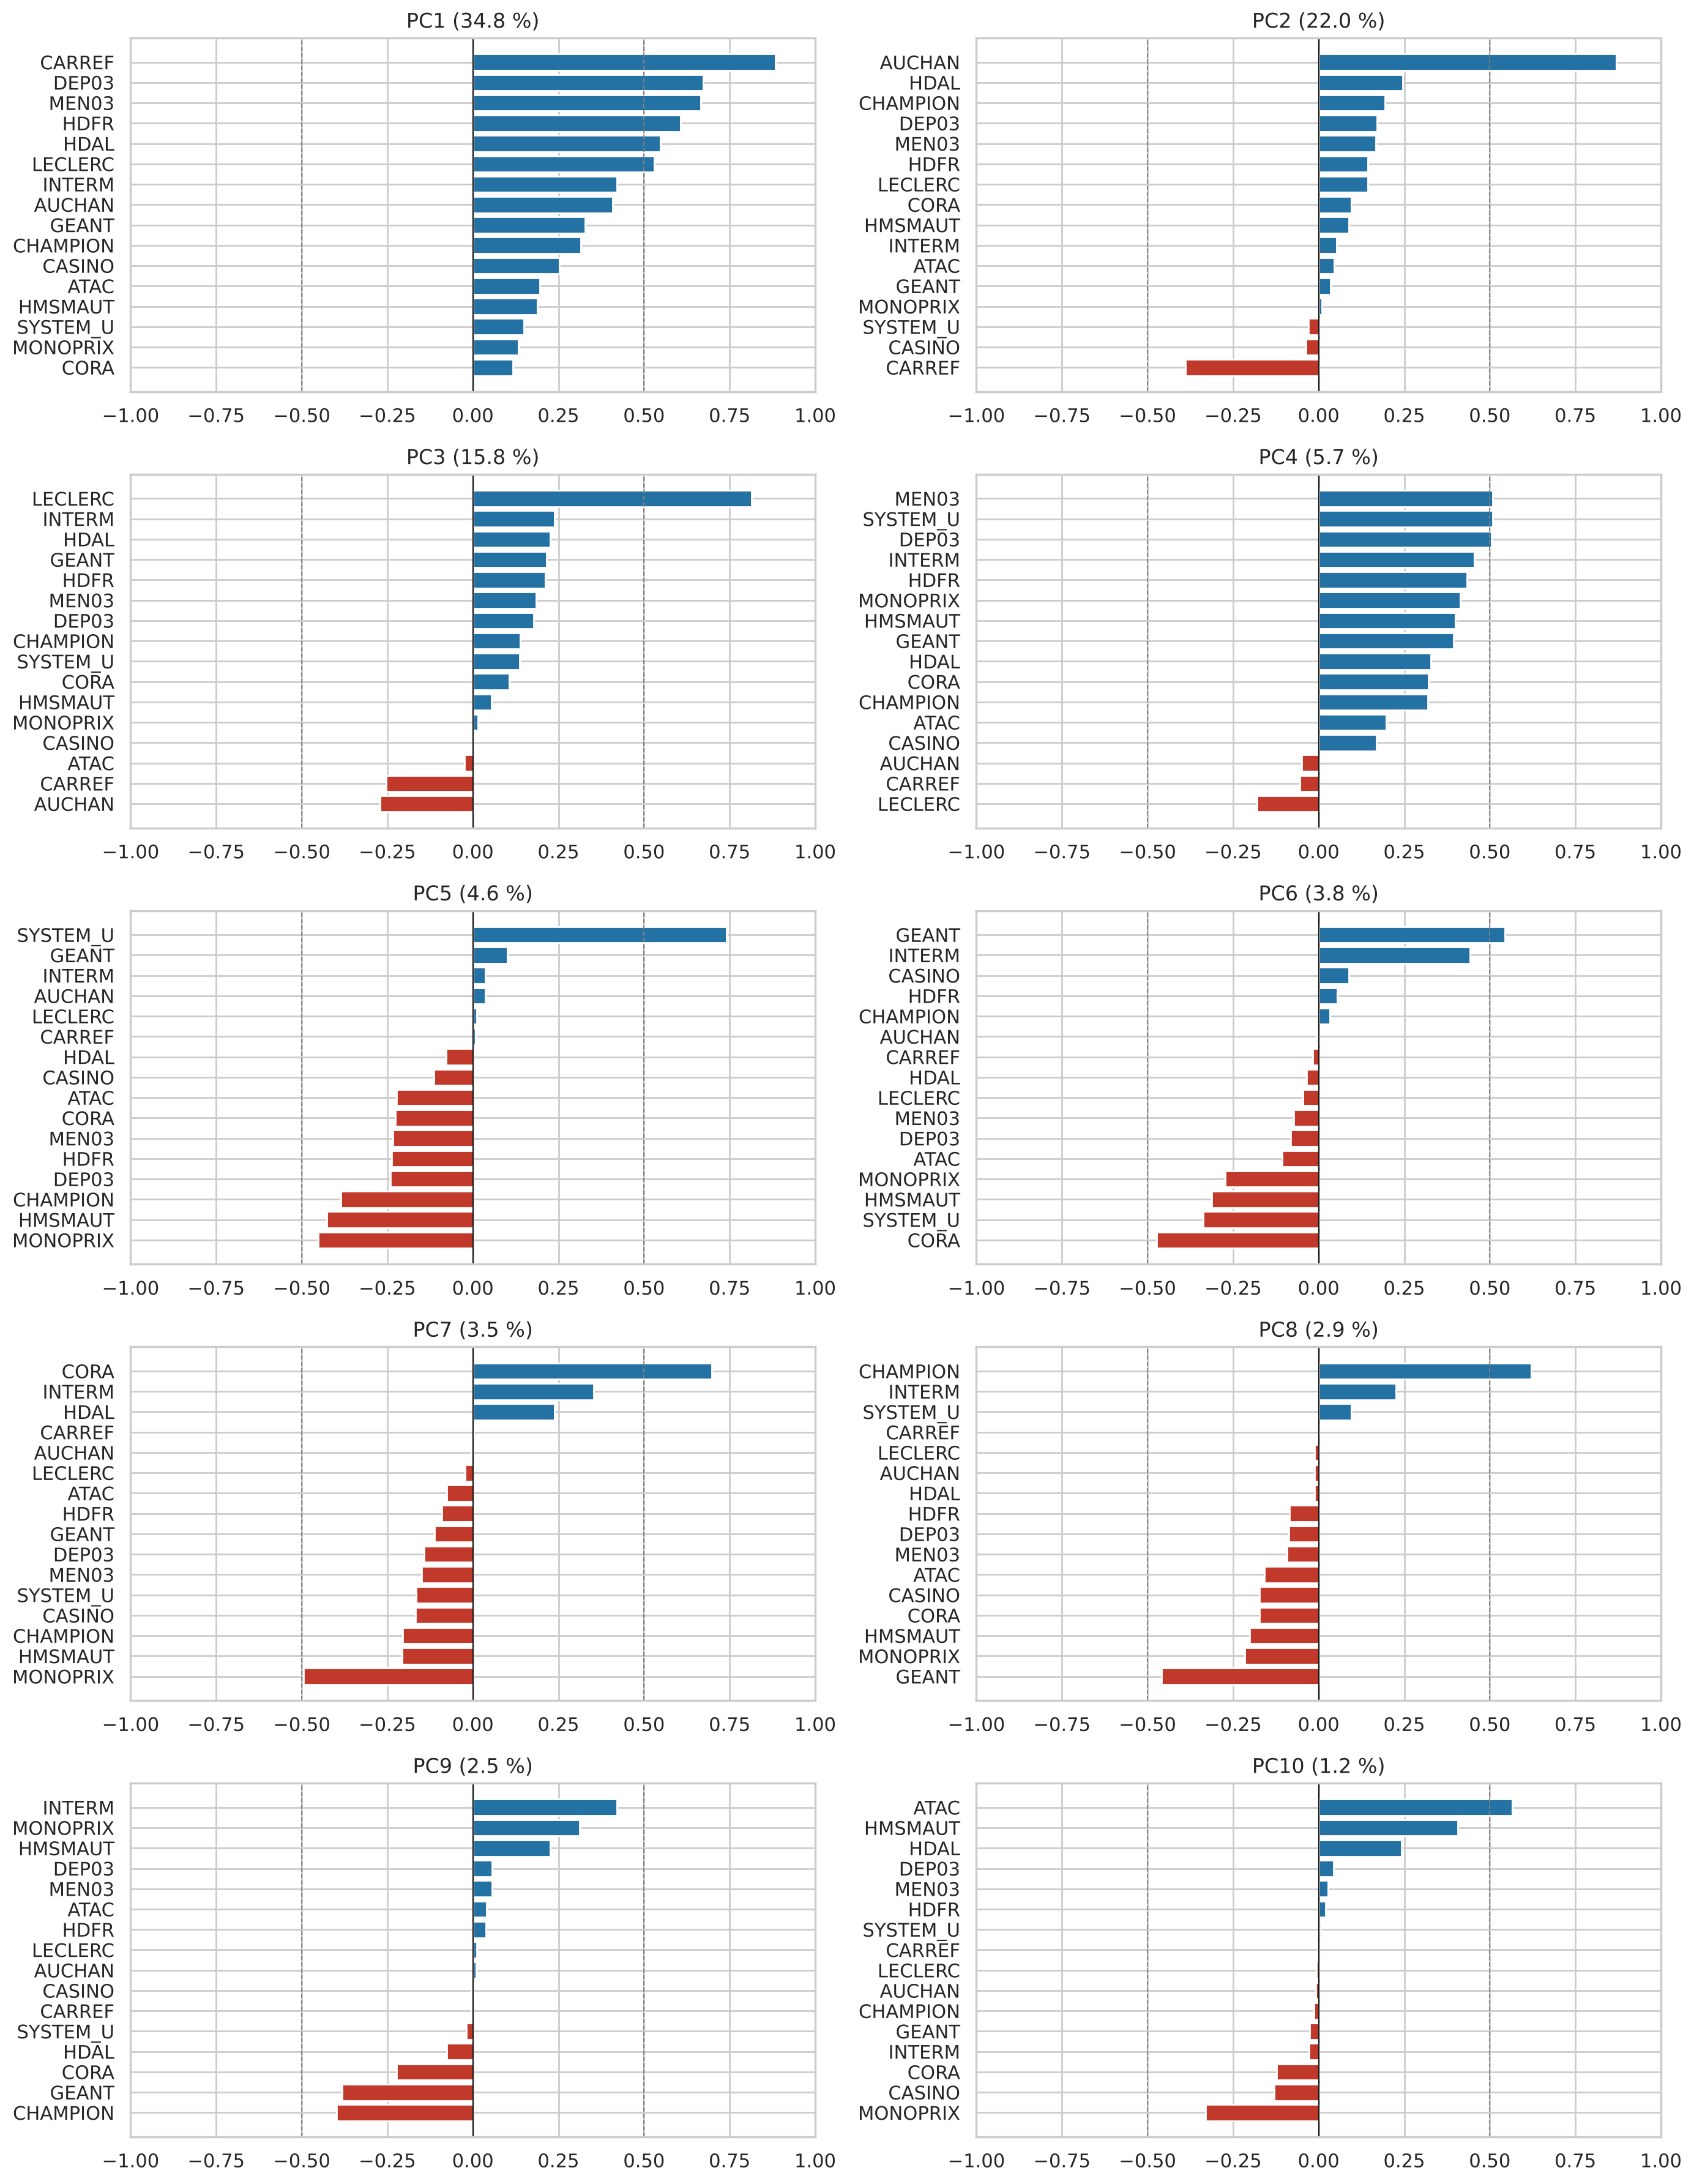

In [29]:
# Barres de corrélation pour chaque composante à synthétiser
cum = np.cumsum(pca.explained_variance_ratio_)
N_SYNTH = L                                          # on synthétise les L composantes retenues
print("Composantes synthétisées :", N_SYNTH)

ncol = 2; nrow = int(np.ceil(N_SYNTH / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(14, 3.6 * nrow), squeeze=False)
for ax, pc in zip(axes.ravel(), pc_names[:N_SYNTH]):
    s = corr[pc].astype(float).sort_values()
    colors = ["#c0392b" if v < 0 else "#2471a3" for v in s]
    ax.barh(s.index, s.values, color=colors)
    ax.axvline(0, c="k", lw=.8)
    for t in (-.5, .5): ax.axvline(t, ls="--", c="grey", lw=.7)
    ax.set_xlim(-1, 1)
    ax.set_title(f"{pc} ({pca.explained_variance_ratio_[pc_names.index(pc)]*100:.1f} %)")
for ax in axes.ravel()[N_SYNTH:]: ax.axis("off")
plt.tight_layout(); plt.show()

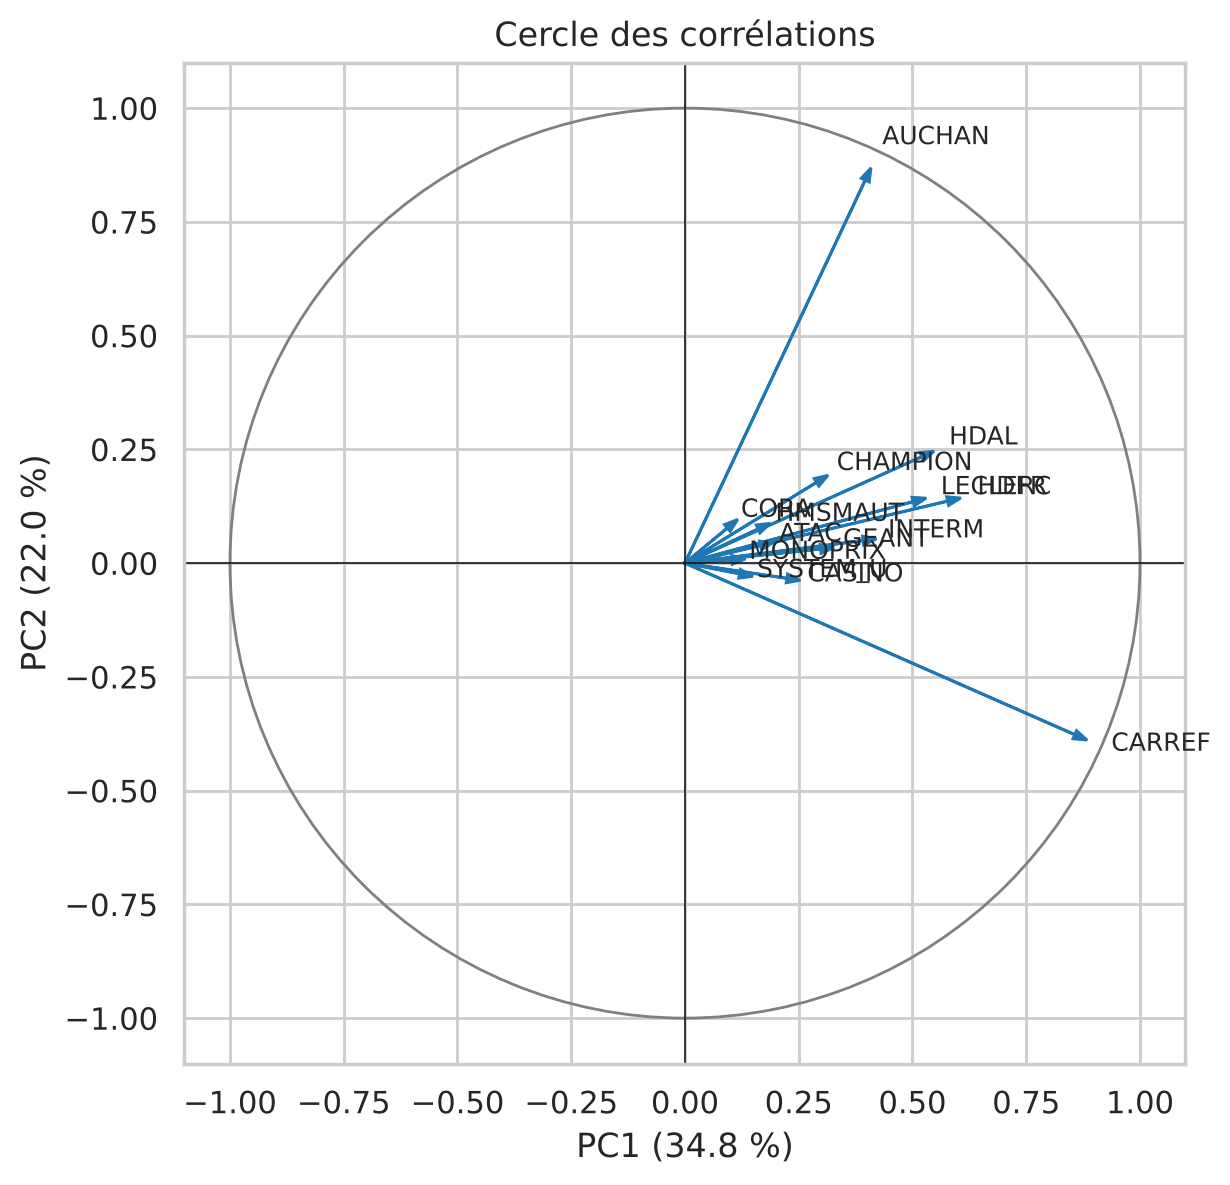

In [30]:
# Cercle des corrélations PC1 / PC2 (variables actives)
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="grey"))
for c in cols:
    x, y = corr.loc[c, "PC1"], corr.loc[c, "PC2"]
    ax.arrow(0, 0, x, y, color="tab:blue", head_width=0.02, length_includes_head=True)
    ax.text(x * 1.06, y * 1.06, c, fontsize=9)
ax.axhline(0, c="k", lw=.6); ax.axvline(0, c="k", lw=.6)
ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1); ax.set_aspect("equal")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f} %)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f} %)")
ax.set_title("Cercle des corrélations")
plt.show()

## 11. Synthèse par composante

In [31]:
from IPython.display import Markdown, display

def niveau(r):
    a = abs(r)
    return "très forte" if a >= .7 else "forte" if a >= .5 else "modérée"

def fmt_vars(s):
    return ", ".join(f"**{k}** ({v:+.2f}, {niveau(v)})" for k, v in s.items())

rows = []
for i, pc in enumerate(pc_names[:N_SYNTH]):
    r_act  = corr.loc[cols, pc].astype(float)
    r_supp = corr.loc[SUPP_COLS, pc].astype(float) if SUPP_COLS else pd.Series(dtype=float)
    pos = r_act[r_act >= .3].sort_values(ascending=False)
    neg = r_act[r_act <= -.3].sort_values()
    ve, vc = pca.explained_variance_ratio_[i] * 100, cum[i] * 100

    txt = f"### {pc} — {ve:.1f} % de la variance (cumul {vc:.1f} %)\n\n"
    if len(pos) == 0 and len(neg) == 0:
        top = r_act.reindex(r_act.abs().sort_values(ascending=False).index)[:3]
        txt += f"- Composante **diffuse** : aucune enseigne n'a |r| ≥ 0,3. Les plus liées : {fmt_vars(top)}.\n"
        nature = "composante diffuse"
    else:
        if len(pos): txt += f"- **Corrélée positivement** à : {fmt_vars(pos)}.\n"
        if len(neg): txt += f"- **Corrélée négativement** à : {fmt_vars(neg)}.\n"
        if len(pos) and len(neg):
            nature = f"opposition {', '.join(pos.index[:2])} vs {', '.join(neg.index[:2])}"
            txt += f"- **Lecture** : axe d'opposition. Un score élevé = sites où {', '.join(pos.index)} dominent ; un score faible = sites où {', '.join(neg.index)} dominent.\n"
        elif len(pos):
            nature = f"intensité {', '.join(pos.index[:3])}"
            txt += f"- **Lecture** : axe d'intensité. Un score élevé = sites où {', '.join(pos.index)} sont élevés.\n"
        else:
            nature = f"intensité inverse {', '.join(neg.index[:3])}"
            txt += f"- **Lecture** : un score faible (négatif) = sites où {', '.join(neg.index)} sont élevés.\n"
    sup = r_supp[r_supp.abs() >= .3]
    if len(sup): txt += f"- **Variables supplémentaires** liées : {fmt_vars(sup)}.\n"
    elif len(r_supp): txt += "- Variables supplémentaires (MEN03, DEP03) : pas de lien notable (|r| < 0,3).\n"

    if "CLUSTER" in df_all:
        m = df_all.groupby("CLUSTER")[pc].mean()
        txt += (f"- **Clusters** : score moyen le plus haut en cluster {m.idxmax()} ({m.max():.0f}), "
                f"le plus bas en cluster {m.idxmin()} ({m.min():.0f}).\n")
    display(Markdown(txt))
    rows.append({"composante": pc, "variance_%": round(ve, 1), "cumul_%": round(vc, 1), "caractérisation": nature})

synthese = pd.DataFrame(rows)
synthese

### PC1 — 34.8 % de la variance (cumul 34.8 %)

- **Corrélée positivement** à : **CARREF** (+0.88, très forte), **HDFR** (+0.61, forte), **HDAL** (+0.55, forte), **LECLERC** (+0.53, forte), **INTERM** (+0.42, modérée), **AUCHAN** (+0.41, modérée), **GEANT** (+0.33, modérée), **CHAMPION** (+0.31, modérée).
- **Lecture** : axe d'intensité. Un score élevé = sites où CARREF, HDFR, HDAL, LECLERC, INTERM, AUCHAN, GEANT, CHAMPION sont élevés.
- **Variables supplémentaires** liées : **MEN03** (+0.67, forte), **DEP03** (+0.67, forte).
- **Clusters** : score moyen le plus haut en cluster 2 (52558), le plus bas en cluster 0 (-4140).


### PC2 — 22.0 % de la variance (cumul 56.8 %)

- **Corrélée positivement** à : **AUCHAN** (+0.87, très forte).
- **Corrélée négativement** à : **CARREF** (-0.39, modérée).
- **Lecture** : axe d'opposition. Un score élevé = sites où AUCHAN dominent ; un score faible = sites où CARREF dominent.
- Variables supplémentaires (MEN03, DEP03) : pas de lien notable (|r| < 0,3).
- **Clusters** : score moyen le plus haut en cluster 1 (56669), le plus bas en cluster 2 (-23118).


### PC3 — 15.8 % de la variance (cumul 72.6 %)

- **Corrélée positivement** à : **LECLERC** (+0.81, très forte).
- **Lecture** : axe d'intensité. Un score élevé = sites où LECLERC sont élevés.
- Variables supplémentaires (MEN03, DEP03) : pas de lien notable (|r| < 0,3).
- **Clusters** : score moyen le plus haut en cluster 0 (824), le plus bas en cluster 1 (-11081).


### PC4 — 5.7 % de la variance (cumul 78.3 %)

- **Corrélée positivement** à : **SYSTEM_U** (+0.51, forte), **INTERM** (+0.45, modérée), **HDFR** (+0.43, modérée), **MONOPRIX** (+0.41, modérée), **HMSMAUT** (+0.40, modérée), **GEANT** (+0.39, modérée), **HDAL** (+0.33, modérée), **CORA** (+0.32, modérée), **CHAMPION** (+0.32, modérée).
- **Lecture** : axe d'intensité. Un score élevé = sites où SYSTEM_U, INTERM, HDFR, MONOPRIX, HMSMAUT, GEANT, HDAL, CORA, CHAMPION sont élevés.
- **Variables supplémentaires** liées : **MEN03** (+0.51, forte), **DEP03** (+0.50, forte).
- **Clusters** : score moyen le plus haut en cluster 0 (101), le plus bas en cluster 2 (-1133).


### PC5 — 4.6 % de la variance (cumul 83.0 %)

- **Corrélée positivement** à : **SYSTEM_U** (+0.74, très forte).
- **Corrélée négativement** à : **MONOPRIX** (-0.45, modérée), **HMSMAUT** (-0.43, modérée), **CHAMPION** (-0.39, modérée).
- **Lecture** : axe d'opposition. Un score élevé = sites où SYSTEM_U dominent ; un score faible = sites où MONOPRIX, HMSMAUT, CHAMPION dominent.
- Variables supplémentaires (MEN03, DEP03) : pas de lien notable (|r| < 0,3).
- **Clusters** : score moyen le plus haut en cluster 1 (1012), le plus bas en cluster 2 (-278).


### PC6 — 3.8 % de la variance (cumul 86.8 %)

- **Corrélée positivement** à : **GEANT** (+0.54, forte), **INTERM** (+0.44, modérée).
- **Corrélée négativement** à : **CORA** (-0.47, modérée), **SYSTEM_U** (-0.34, modérée), **HMSMAUT** (-0.31, modérée).
- **Lecture** : axe d'opposition. Un score élevé = sites où GEANT, INTERM dominent ; un score faible = sites où CORA, SYSTEM_U, HMSMAUT dominent.
- Variables supplémentaires (MEN03, DEP03) : pas de lien notable (|r| < 0,3).
- **Clusters** : score moyen le plus haut en cluster 1 (339), le plus bas en cluster 2 (-489).


### PC7 — 3.5 % de la variance (cumul 90.3 %)

- **Corrélée positivement** à : **CORA** (+0.70, forte), **INTERM** (+0.35, modérée).
- **Corrélée négativement** à : **MONOPRIX** (-0.49, modérée).
- **Lecture** : axe d'opposition. Un score élevé = sites où CORA, INTERM dominent ; un score faible = sites où MONOPRIX dominent.
- Variables supplémentaires (MEN03, DEP03) : pas de lien notable (|r| < 0,3).
- **Clusters** : score moyen le plus haut en cluster 1 (439), le plus bas en cluster 0 (-38).


### PC8 — 2.9 % de la variance (cumul 93.2 %)

- **Corrélée positivement** à : **CHAMPION** (+0.62, forte).
- **Corrélée négativement** à : **GEANT** (-0.46, modérée).
- **Lecture** : axe d'opposition. Un score élevé = sites où CHAMPION dominent ; un score faible = sites où GEANT dominent.
- Variables supplémentaires (MEN03, DEP03) : pas de lien notable (|r| < 0,3).
- **Clusters** : score moyen le plus haut en cluster 2 (258), le plus bas en cluster 1 (-940).


### PC9 — 2.5 % de la variance (cumul 95.7 %)

- **Corrélée positivement** à : **INTERM** (+0.42, modérée), **MONOPRIX** (+0.31, modérée).
- **Corrélée négativement** à : **CHAMPION** (-0.40, modérée), **GEANT** (-0.38, modérée).
- **Lecture** : axe d'opposition. Un score élevé = sites où INTERM, MONOPRIX dominent ; un score faible = sites où CHAMPION, GEANT dominent.
- Variables supplémentaires (MEN03, DEP03) : pas de lien notable (|r| < 0,3).
- **Clusters** : score moyen le plus haut en cluster 1 (751), le plus bas en cluster 2 (-948).


### PC10 — 1.2 % de la variance (cumul 96.9 %)

- **Corrélée positivement** à : **ATAC** (+0.57, forte), **HMSMAUT** (+0.41, modérée).
- **Corrélée négativement** à : **MONOPRIX** (-0.33, modérée).
- **Lecture** : axe d'opposition. Un score élevé = sites où ATAC, HMSMAUT dominent ; un score faible = sites où MONOPRIX dominent.
- Variables supplémentaires (MEN03, DEP03) : pas de lien notable (|r| < 0,3).
- **Clusters** : score moyen le plus haut en cluster 0 (16), le plus bas en cluster 2 (-181).


,composante,variance_%,cumul_%,caractérisation
0,PC1,34.8,34.8,"intensité CARREF, HDFR, HDAL"
1,PC2,22.0,56.8,opposition AUCHAN vs CARREF
2,PC3,15.8,72.6,intensité LECLERC
3,PC4,5.7,78.3,"intensité SYSTEM_U, INTERM, HDFR"
4,PC5,4.6,83.0,"opposition SYSTEM_U vs MONOPRIX, HMSMAUT"
5,PC6,3.8,86.8,"opposition GEANT, INTERM vs CORA, SYSTEM_U"
6,PC7,3.5,90.3,"opposition CORA, INTERM vs MONOPRIX"
7,PC8,2.9,93.2,opposition CHAMPION vs GEANT
8,PC9,2.5,95.7,"opposition INTERM, MONOPRIX vs CHAMPION, GEANT"
9,PC10,1.2,96.9,"opposition ATAC, HMSMAUT vs MONOPRIX"


### Points de vigilance
- La PCA n'étant **pas standardisée**, les enseignes aux volumes les plus élevés pèsent davantage dans les premières composantes ; c'est voulu ici, mais cela favorise les grosses enseignes.
- Beaucoup de sites ont des valeurs à 0 pour plusieurs enseignes (présence / absence) : certaines composantes traduisent donc surtout **la présence d'une enseigne** plutôt qu'un volume.
- Une corrélation décrit un lien linéaire, pas une causalité.

## 12. Visualisations

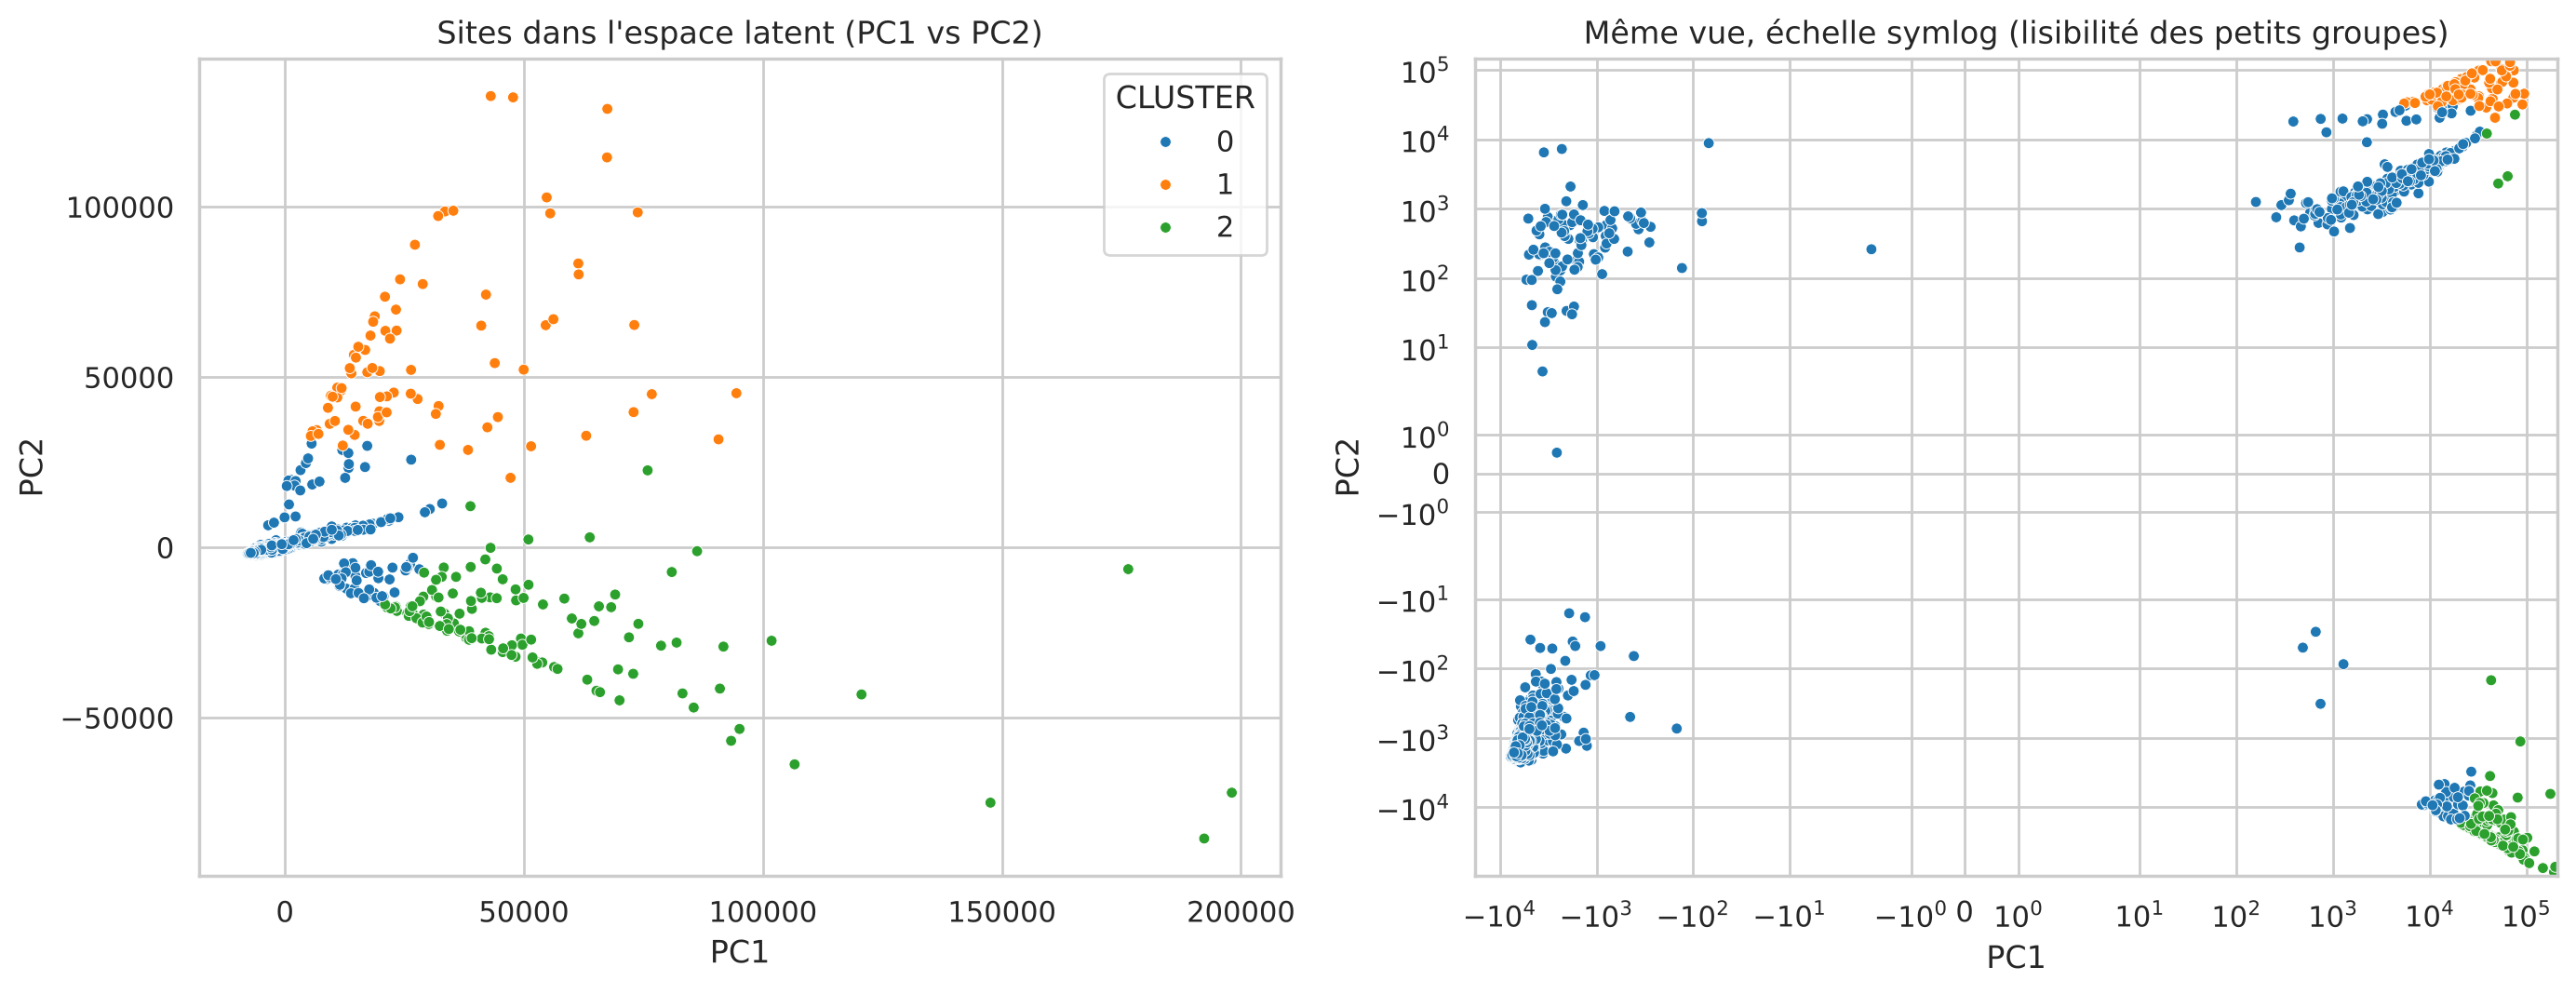

In [32]:
# 12.1 Projection PC1 / PC2 colorée par cluster
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
sns.scatterplot(data=df_all, x="PC1", y="PC2", hue="CLUSTER", palette="tab10", s=18, ax=ax[0])
ax[0].set_title("Sites dans l'espace latent (PC1 vs PC2)")
sns.scatterplot(data=df_all, x="PC1", y="PC2", hue="CLUSTER", palette="tab10", s=18, ax=ax[1], legend=False)
ax[1].set_xscale("symlog"); ax[1].set_yscale("symlog")
ax[1].set_title("Même vue, échelle symlog (lisibilité des petits groupes)")
plt.tight_layout(); plt.show()

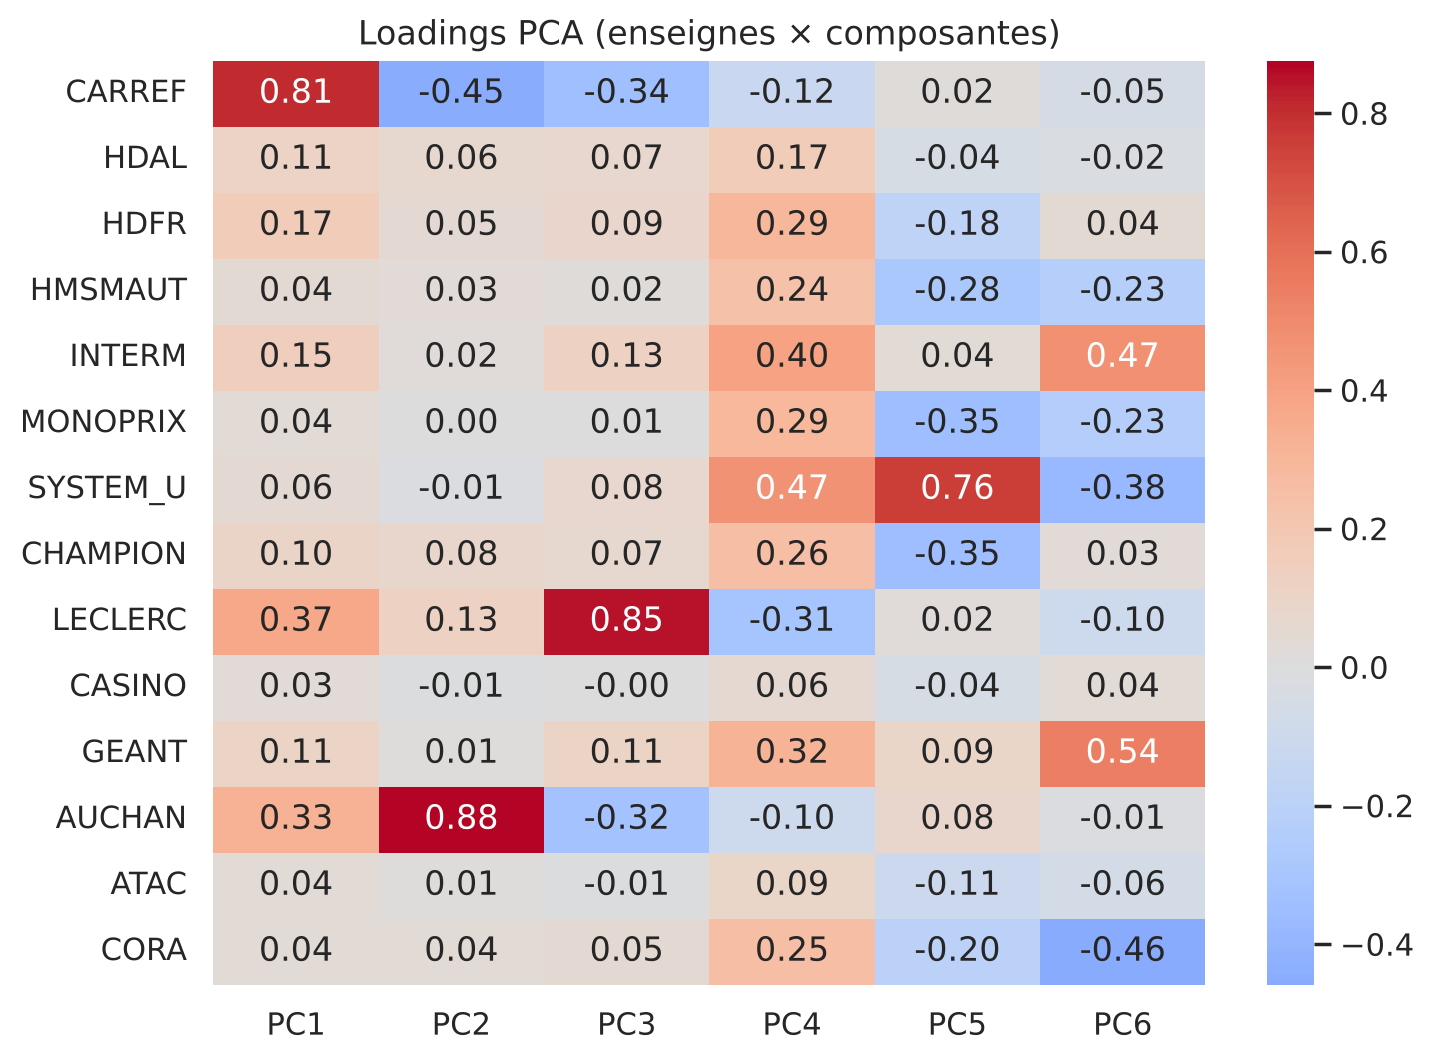

In [33]:
# 12.2 Loadings : contribution de chaque enseigne aux composantes
n_show = min(6, L)
load = pd.DataFrame(pca.components_[:n_show].T, index=cols, columns=pc_names[:n_show])
plt.figure(figsize=(8, 6))
sns.heatmap(load, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Loadings PCA (enseignes × composantes)"); plt.show()

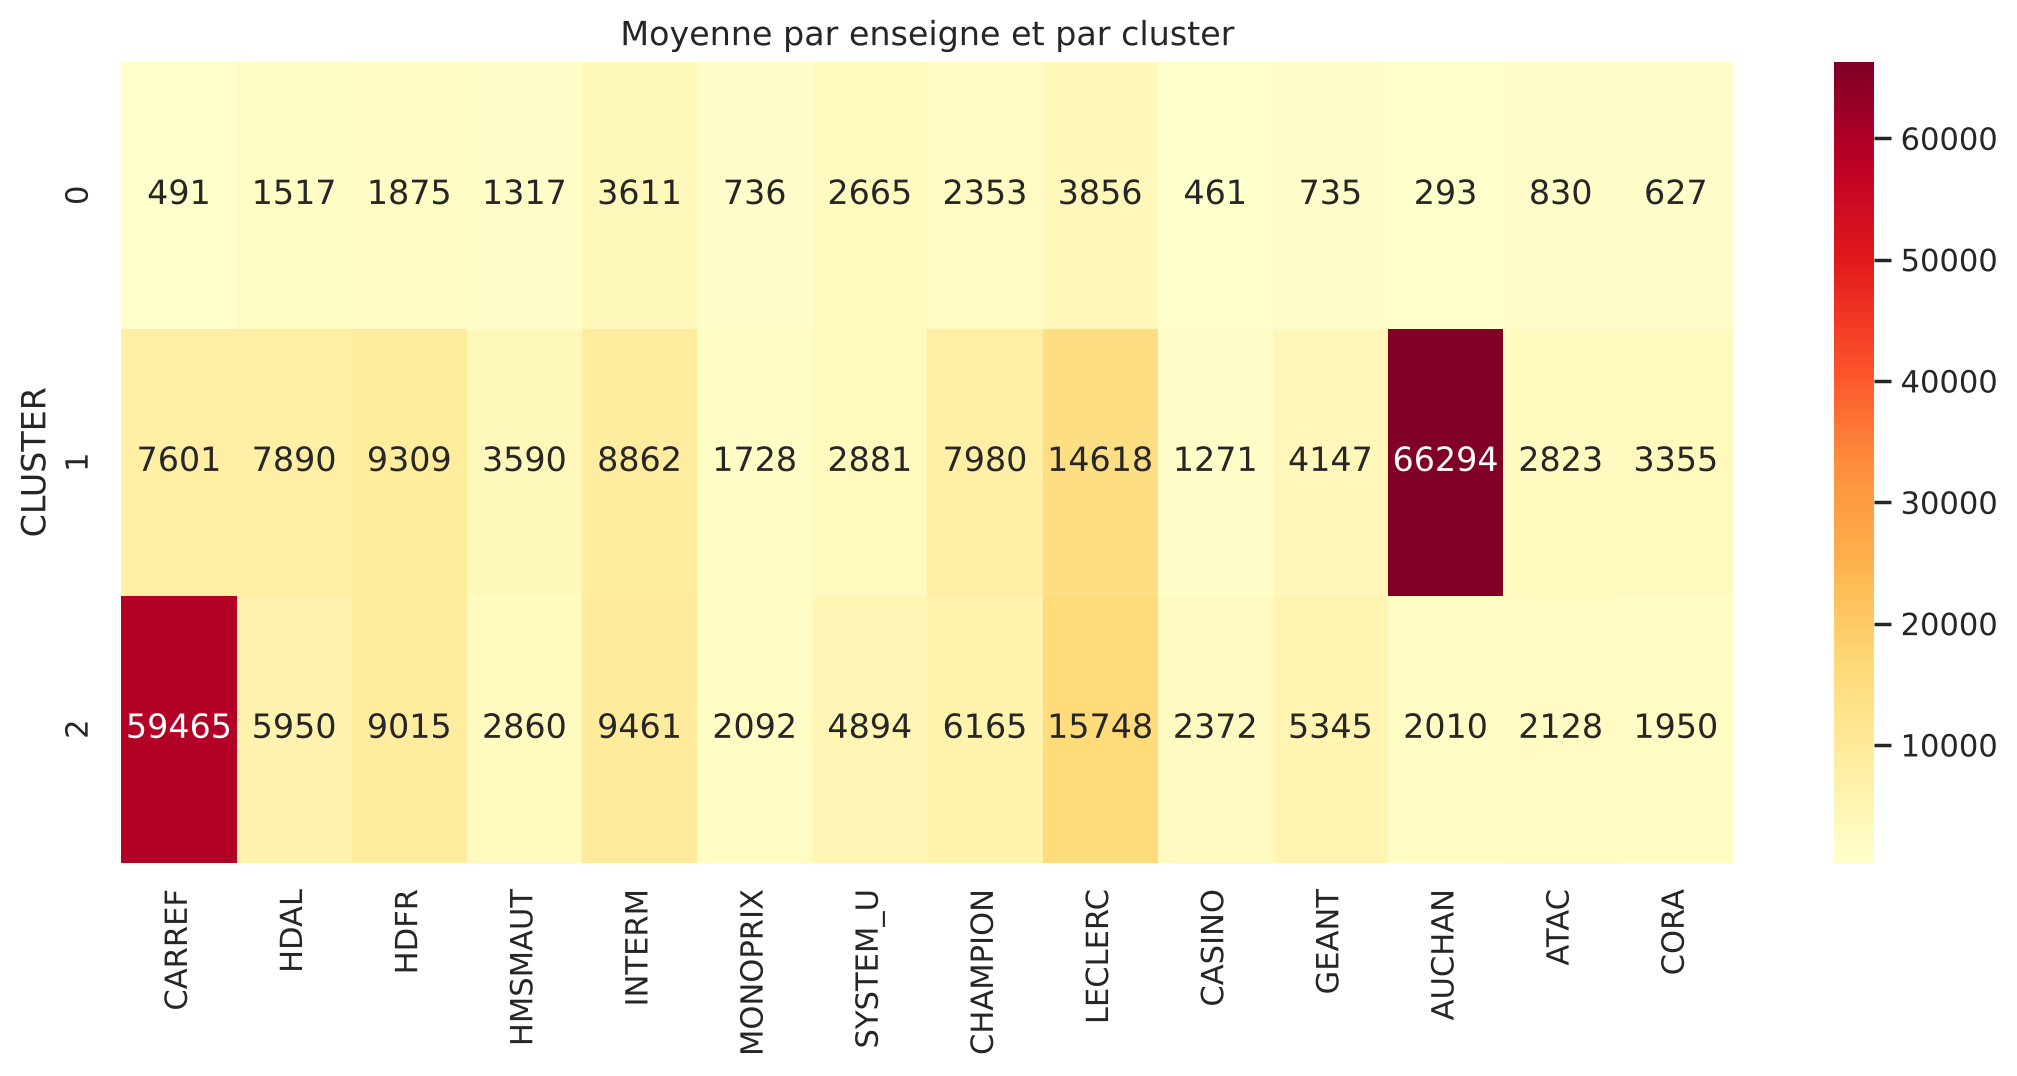

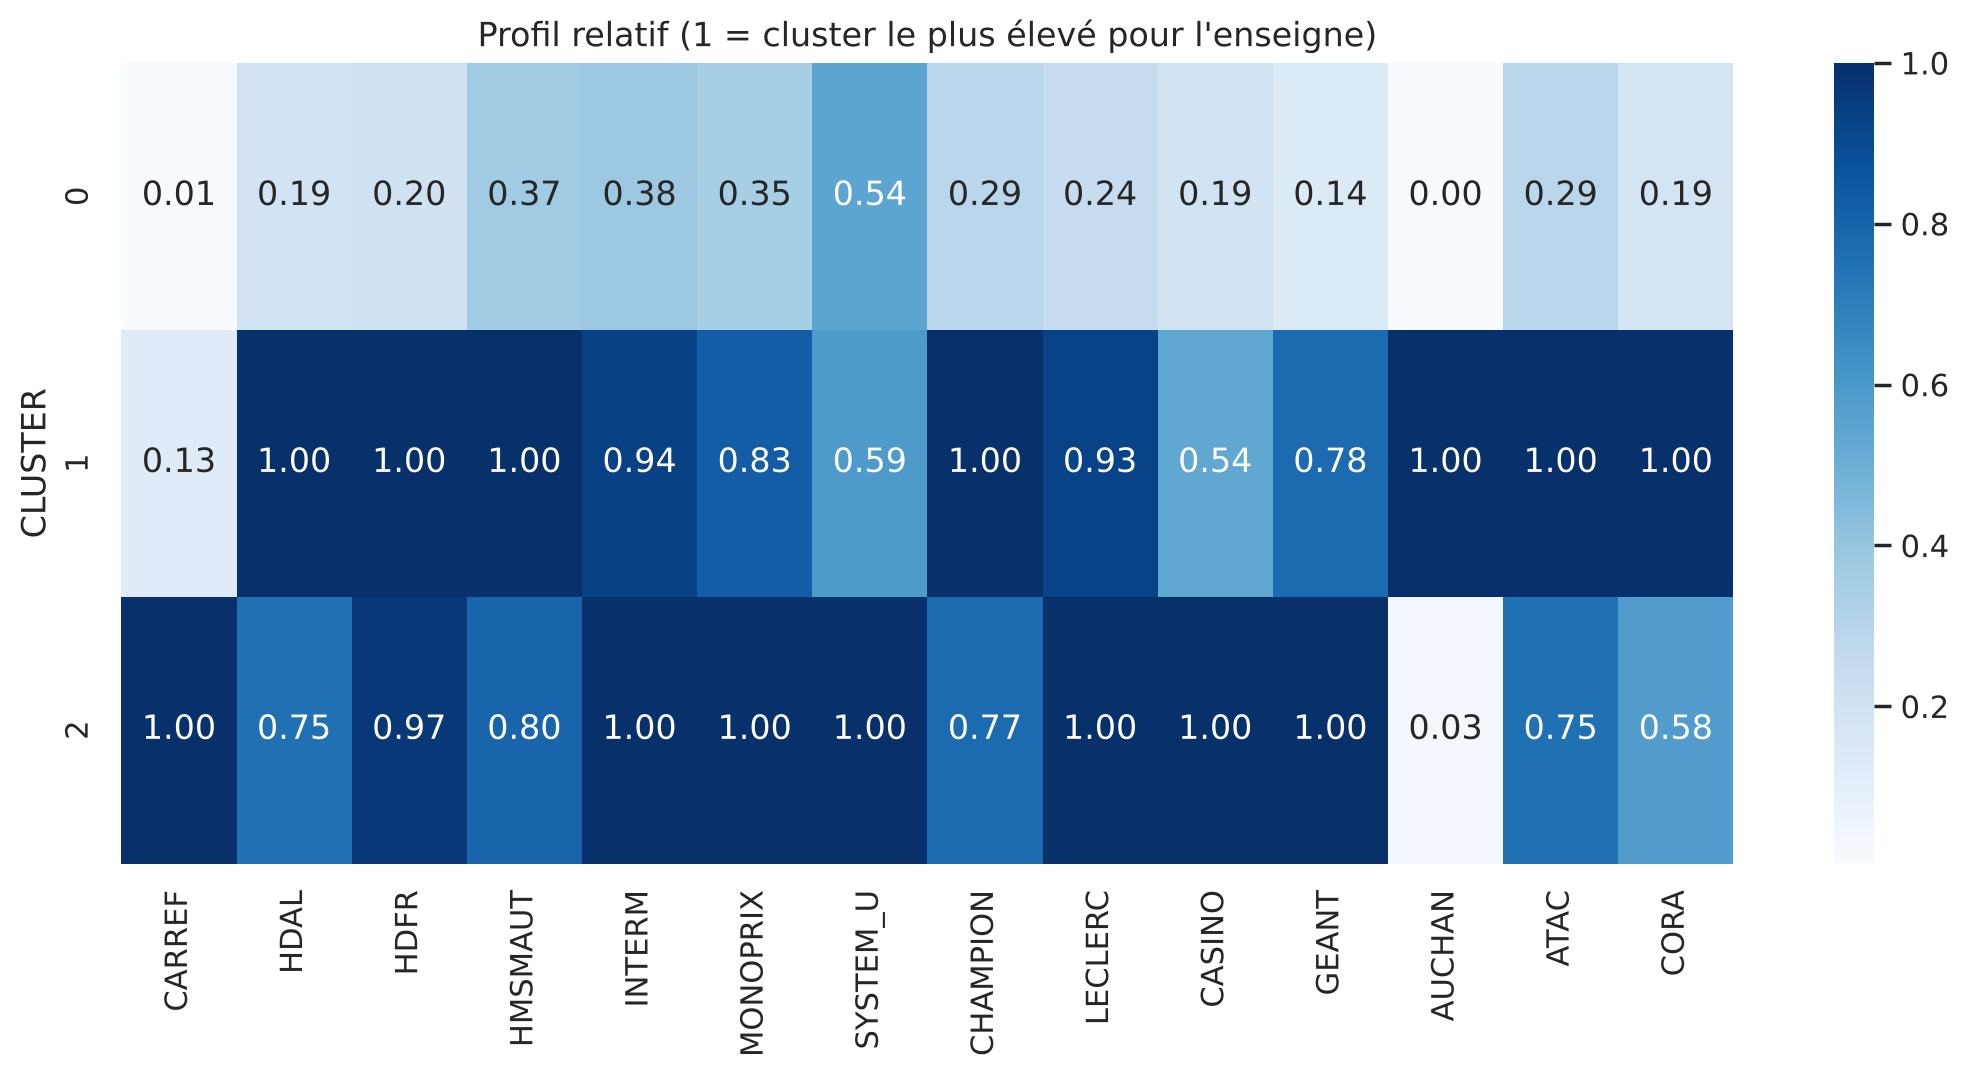

In [34]:
# 12.3 Profil moyen de chaque cluster (variables originales)
profile = df_all.groupby("CLUSTER")[cols].mean()
plt.figure(figsize=(13, 4 + 0.4 * K))
sns.heatmap(profile, annot=True, fmt=".0f", cmap="YlOrRd")
plt.title("Moyenne par enseigne et par cluster"); plt.show()

# version normalisée par colonne (pour comparer les enseignes entre elles)
plt.figure(figsize=(13, 4 + 0.4 * K))
sns.heatmap(profile / profile.max(), annot=True, fmt=".2f", cmap="Blues")
plt.title("Profil relatif (1 = cluster le plus élevé pour l'enseigne)"); plt.show()

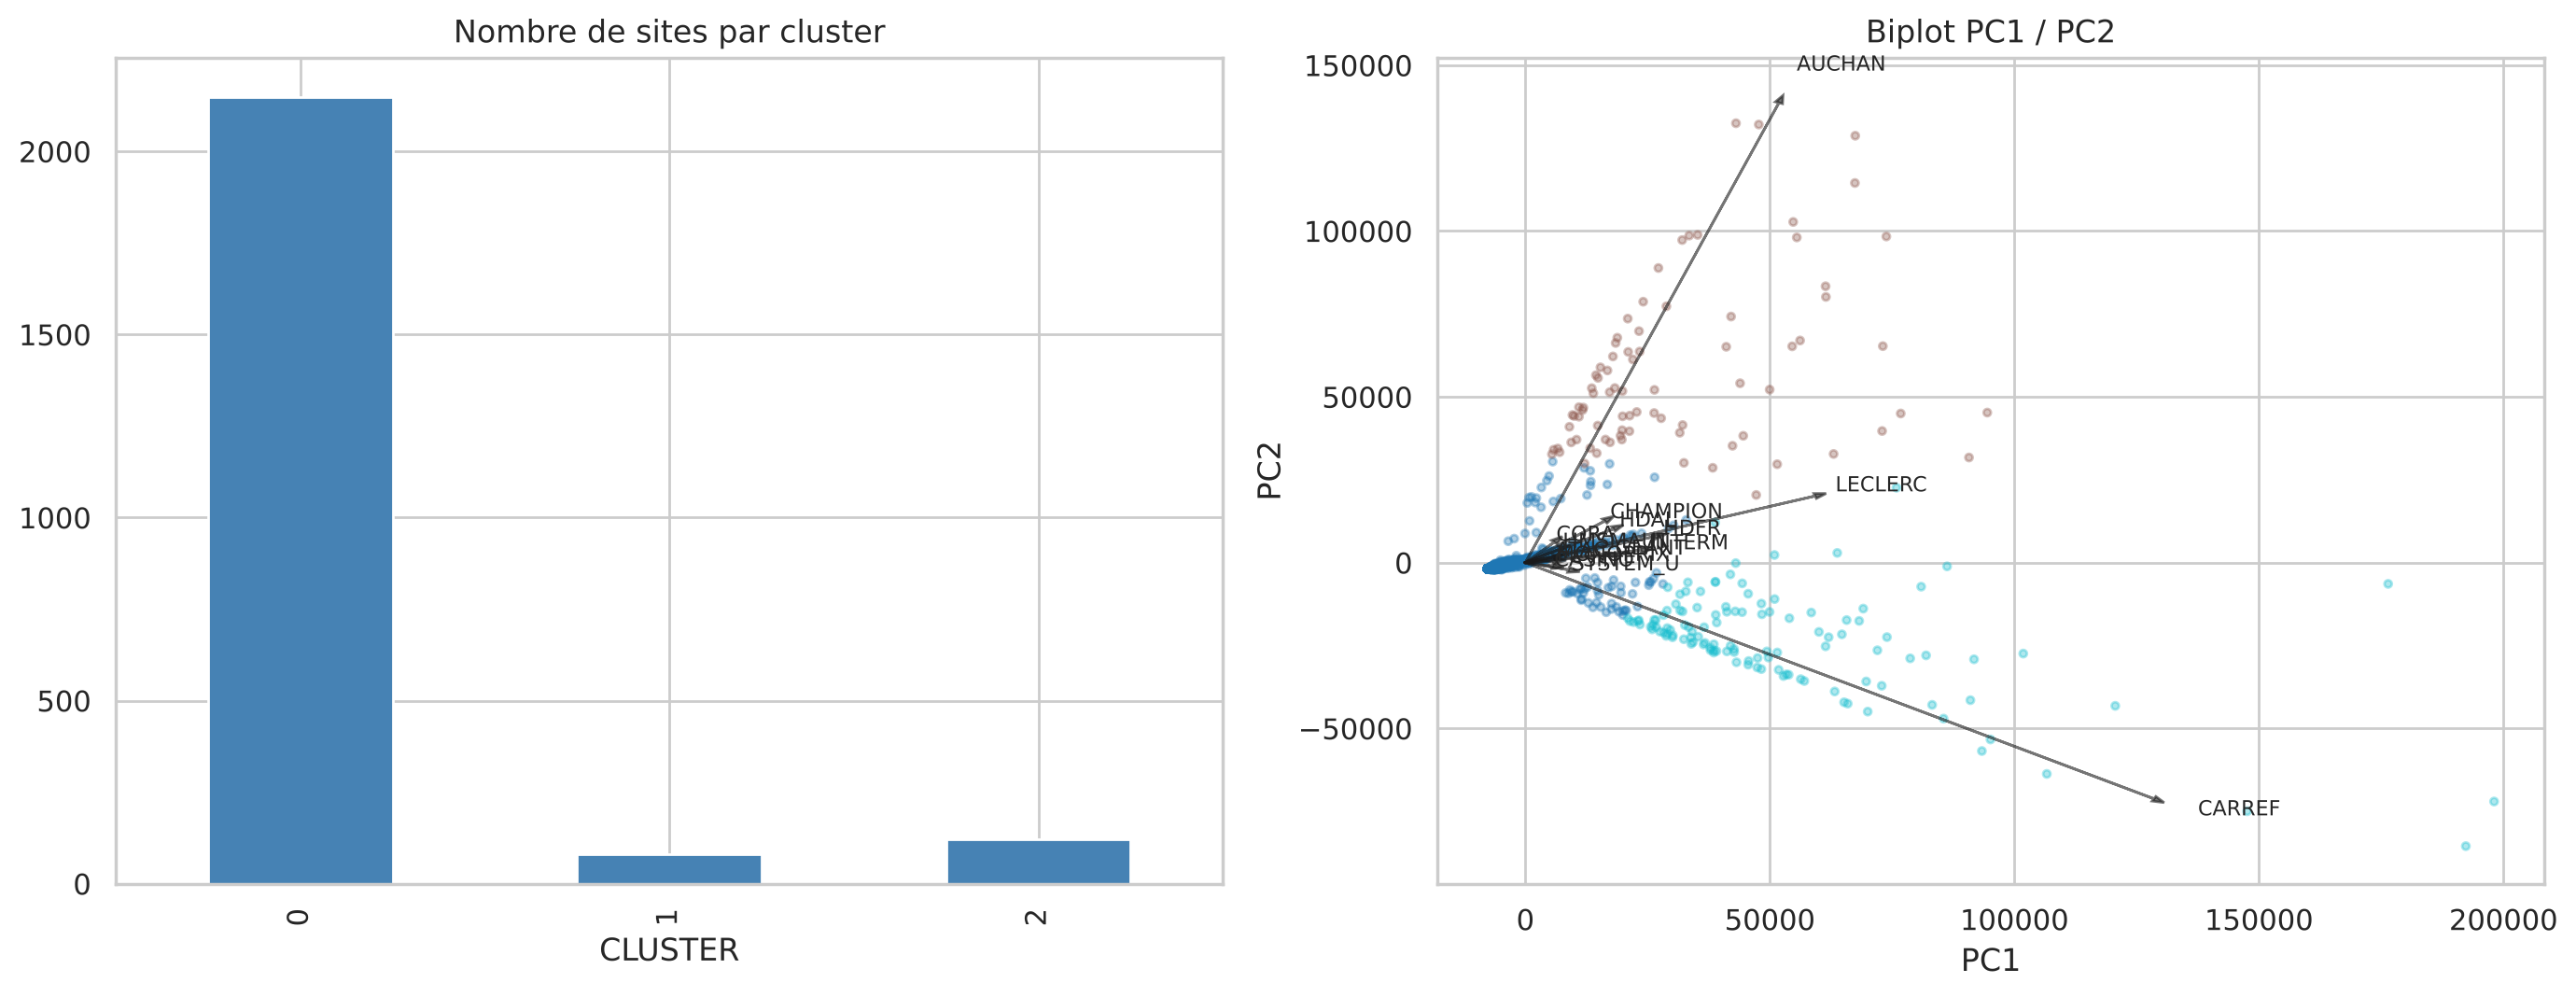

In [35]:
# 12.4 Taille des clusters + biplot PC1/PC2 avec vecteurs des enseignes
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
df_all["CLUSTER"].value_counts().sort_index().plot.bar(ax=ax[0], color="steelblue")
ax[0].set_title("Nombre de sites par cluster"); ax[0].set_xlabel("CLUSTER")

ax[1].scatter(df_all["PC1"], df_all["PC2"], c=df_all["CLUSTER"], cmap="tab10", s=8, alpha=.35)
scale = np.abs(Z[:, :2]).max() * 0.8
for i, c in enumerate(cols):
    ax[1].arrow(0, 0, pca.components_[0, i]*scale, pca.components_[1, i]*scale, color="k", alpha=.6, head_width=scale*0.01)
    ax[1].text(pca.components_[0, i]*scale*1.07, pca.components_[1, i]*scale*1.07, c, fontsize=8)
ax[1].set_title("Biplot PC1 / PC2"); ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2")
plt.tight_layout(); plt.show()

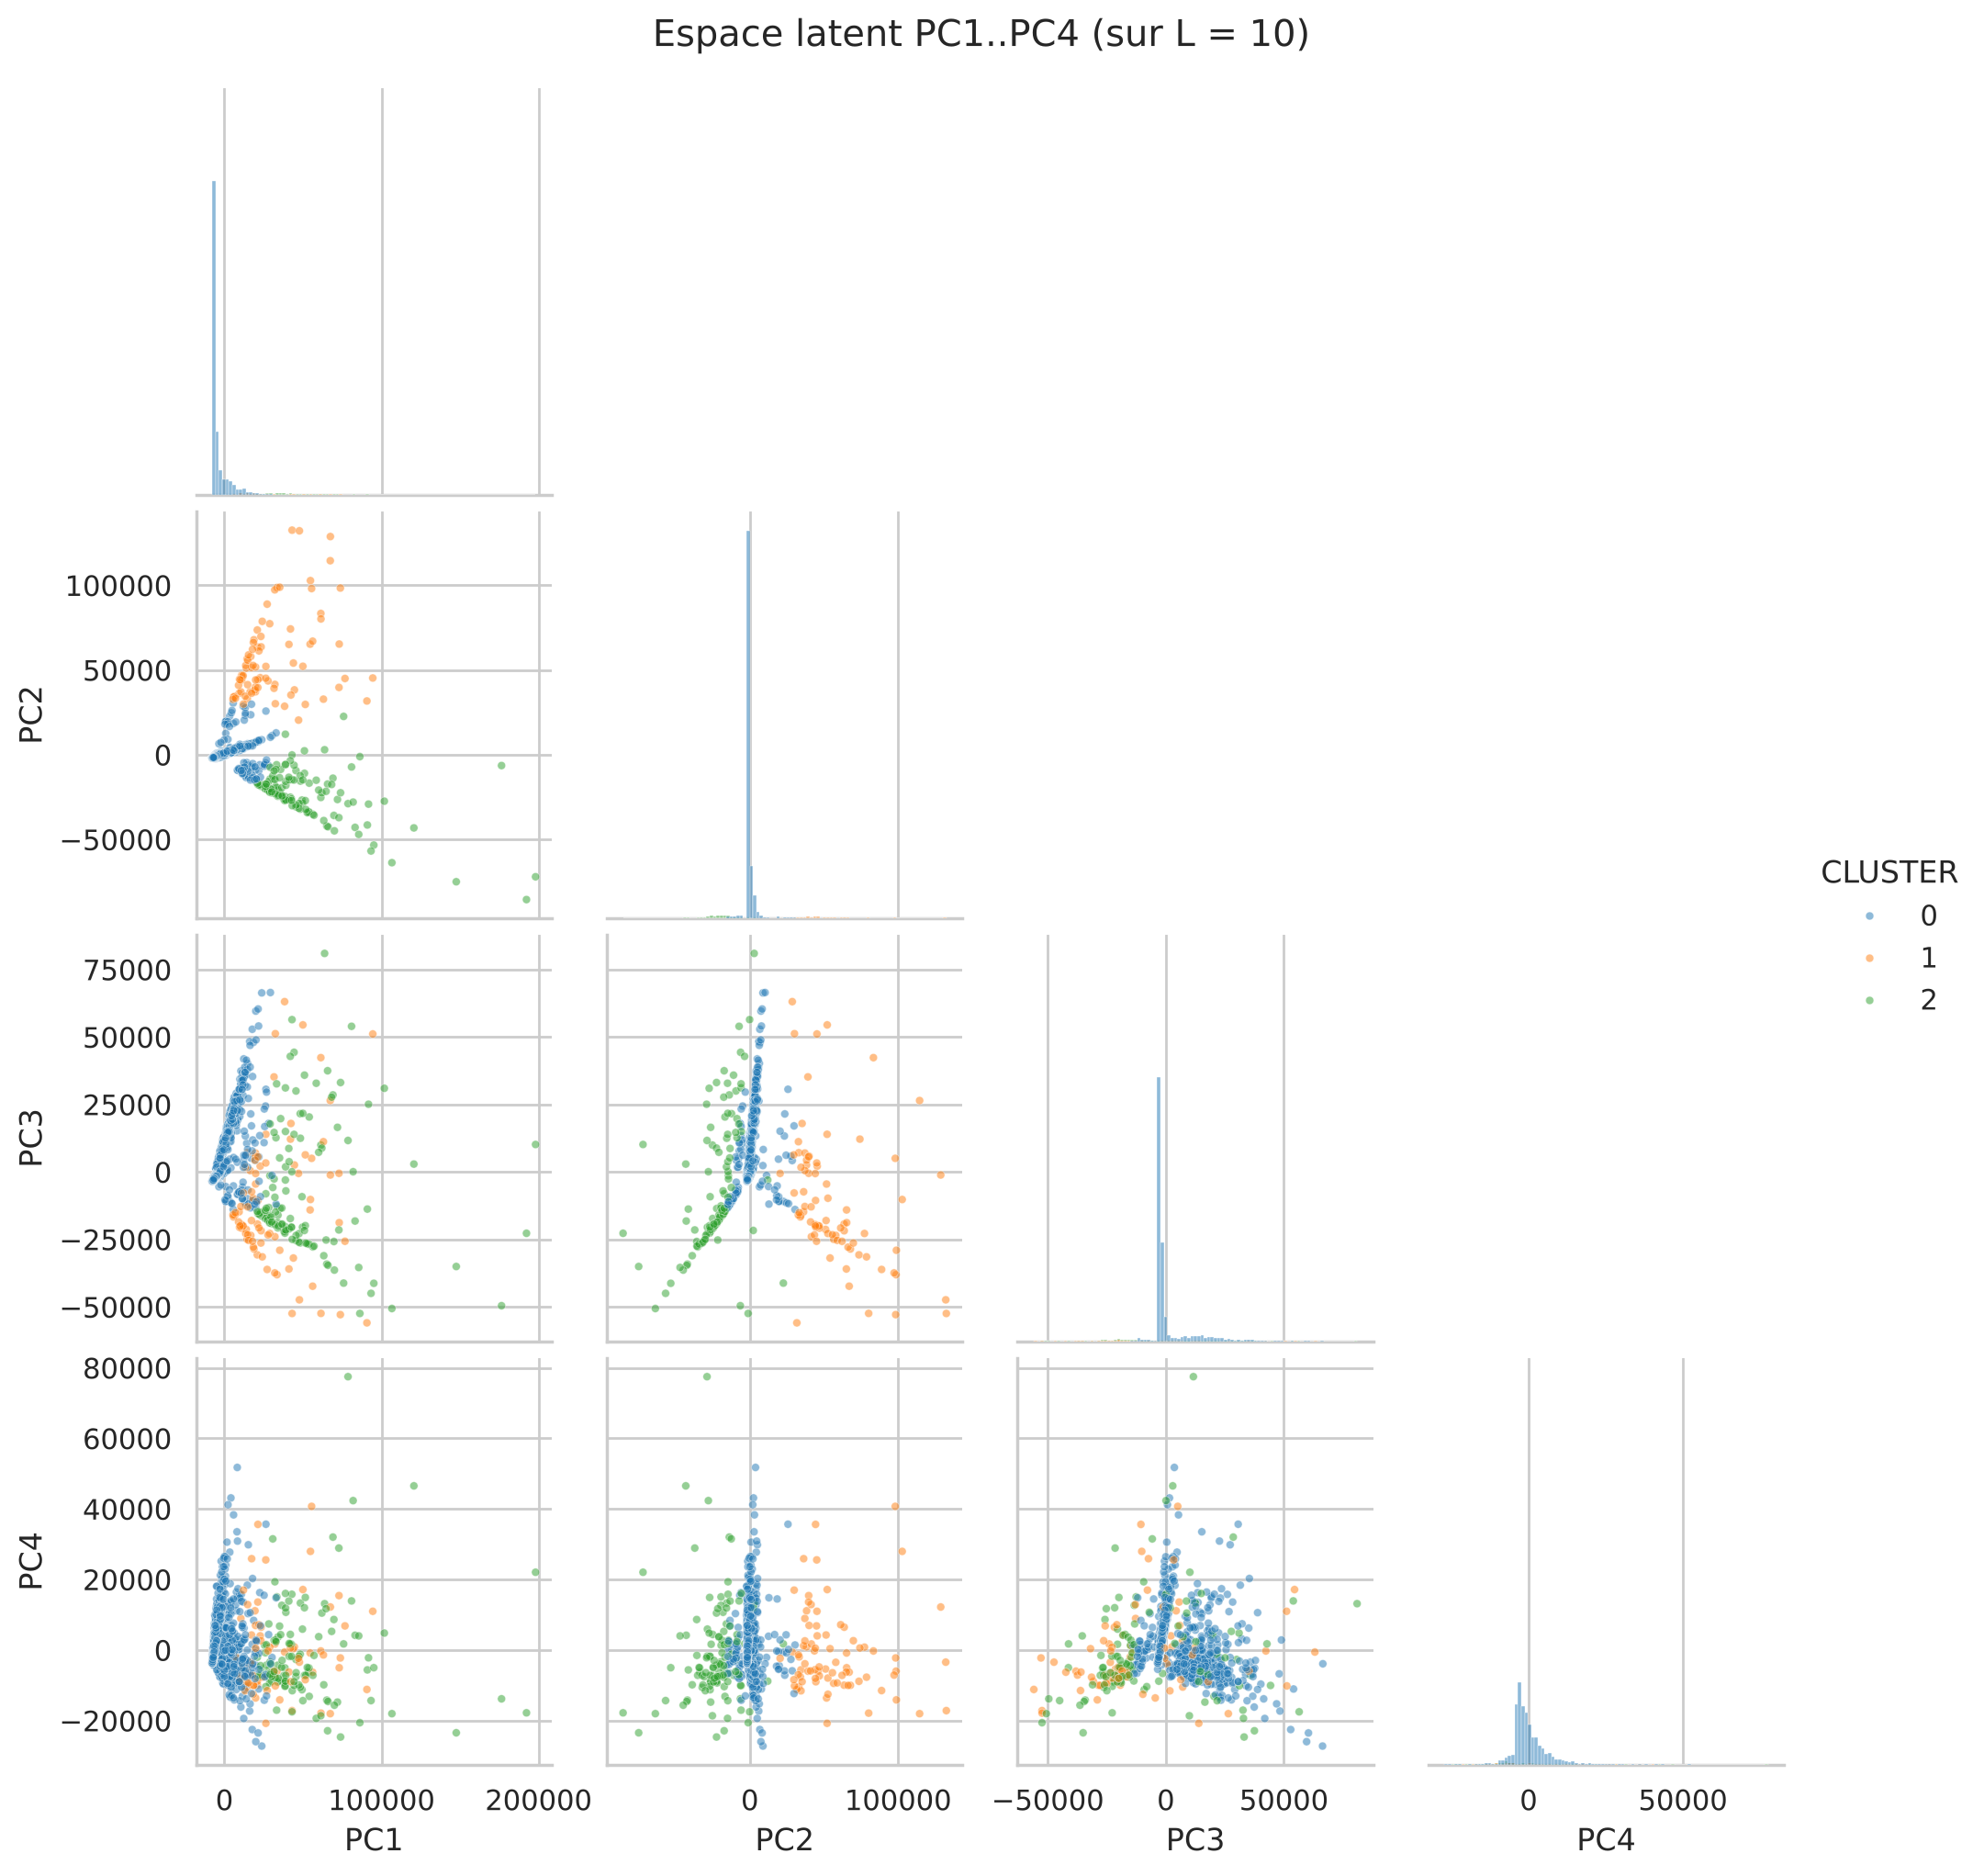

In [36]:
# 12.5 Nuage de points matriciel des composantes latentes retenues (4 premières au plus)
k_show = min(L, 4)
g = sns.pairplot(df_all, vars=pc_names_L[:k_show], hue="CLUSTER", palette="tab10",
                 plot_kws=dict(s=10, alpha=.5), diag_kind="hist", corner=True)
g.fig.suptitle(f"Espace latent PC1..PC{k_show} (sur L = {L})", y=1.02)
plt.show()

## 13. Export

In [37]:
out = "site_2350_pca_clusters.csv"
df_all.to_csv(out, sep=";", index=False)
print("Fichier exporté :", out, df_all.shape)
corr.drop(columns="type").to_csv("correlations_variables_composantes.csv", sep=";")
synthese.to_csv("synthese_composantes.csv", sep=";", index=False)
crit_table.to_csv("choix_L_criteres.csv", sep=";", index=False)
cah_table.to_csv("cah_ward_indices.csv", sep=";")
pd.DataFrame(centers, columns=pc_names_L).assign(taille=sizes, classe_cah=lab_micro).to_csv("kmeans_fin_centres_cah.csv", sep=";", index_label="micro_cluster")
synth_classes.to_csv("synthese_classes_cah.csv", sep=";", index=False)
with open("synthese_choix_nombre_classes.md", "w", encoding="utf-8") as f:
    f.write(txt_choix)
carac_clients.to_csv("caracterisation_clusters_indice_dominance.csv", sep=";", index=False)
indice_dom.rename(index=lab).round(1).to_csv("indice_dominance_matrice.csv", sep=";")
eta.sort_values(ascending=False).to_frame("eta2").to_csv("eta2_variables.csv", sep=";")
with open("fiches_clusters_client.md", "w", encoding="utf-8") as f:
    f.write(txt_fiches)
print("Exportés : correlations_variables_composantes.csv, synthese_composantes.csv, choix_L_criteres.csv, cah_ward_indices.csv, kmeans_fin_centres_cah.csv, synthese_classes_cah.csv, synthese_choix_nombre_classes.md, caracterisation_clusters_indice_dominance.csv, indice_dominance_matrice.csv, eta2_variables.csv, fiches_clusters_client.md")
print(f"Résumé : L = {L} composantes ; fichier original + latent : {out_latent} ; fichier avec clusters : {out}")

Fichier exporté : site_2350_pca_clusters.csv (2350, 31)
Exportés : correlations_variables_composantes.csv, synthese_composantes.csv, choix_L_criteres.csv, cah_ward_indices.csv, kmeans_fin_centres_cah.csv, synthese_classes_cah.csv, synthese_choix_nombre_classes.md, caracterisation_clusters_indice_dominance.csv, indice_dominance_matrice.csv, eta2_variables.csv, fiches_clusters_client.md
Résumé : L = 10 composantes ; fichier original + latent : site_2350_original_latent_PC1_PC10.csv ; fichier avec clusters : site_2350_pca_clusters.csv
